# Health02 – Triage decision support on the Medical Archive (rebuilt after feedback)

**Course:** IND310 · **Group 8:** Mobashra Abeer, Izza Qamar · **Data:** `Medical_archieve.csv` (course material, simulated)

This notebook replaces version 3. It was rebuilt after the feedback on the first report.

**How to run:** put `Medical_archieve.csv` next to this notebook (in Colab: upload it) and run all cells. It takes about 3–5 minutes. If the course workbook `Akerhus_universitetssykehus_V3_5_JF.xlsx` is also there, one extra check runs (§2.5). Figures and tables are written to the folder `outputs/`.

The main changes:

| Feedback | What changed |
|---|---|
| *"Where does symptom figure into it?"* | We checked it. The triage colour belongs to the **symptom**, so a lookup table is exact for symptoms the archive knows (§4.1). The model is now used where a table cannot help: **symptoms the archive does not know** (§4) and **critical findings the patient has not revealed yet** (§5). |
| *"Leakage if you know after the fact what examinations were given"* | Examination columns say **how a symptom is revealed**. They are no longer predictors. They only decide *when* a symptom becomes known (§3.3). |
| *"Prediction of red flag, diagnosis or department?"* | Target stated in §1.4. A department recommendation is added in §5.9. |
| Stronger operations research framing | System definition, assumptions and the objective function in §1.3; used in §6. |
| Cost-sensitivity frontier | §5.5 and §6.4. |
| Subgroup analysis | §5.7. |
| Narrower RQ4 | §1.4. |
| HospitalSim | Its triage rule is a baseline in §5; a demo that plugs our model into HospitalSim is in §7. |
| Define terms; say which rows were duplicates; table of included and excluded columns | §1.2, §3.2, §3.4. |

The notebook follows CRISP-DM: business understanding (1), data understanding (2), data preparation (3), modelling (4–5), evaluation (5–6), deployment (7–8).

# 0. Setup

In [1]:
import os, re, json, math, heapq, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.stats import norm

import sklearn, joblib
from sklearn.model_selection import StratifiedGroupKFold, RepeatedStratifiedKFold, StratifiedKFold, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (f1_score, recall_score, precision_score, accuracy_score, confusion_matrix, roc_auc_score, roc_curve,
                             brier_score_loss, mean_absolute_error, r2_score, adjusted_mutual_info_score)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 90)
OUT_DIR = "outputs"; os.makedirs(OUT_DIR, exist_ok=True)

try:
    display
except NameError:                      # plain-python fallback (outside Jupyter)
    def display(x): print(x.to_string() if hasattr(x, "to_string") else x)

# One colour system for all figures. Categorical colours are assigned to an entity once and never change.
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#e87ba4"
LEVEL_COL = {0: "#0ca30c", 1: "#fab219", 2: "#d03b3b"}          # triage colours: green / yellow / red
LEVEL_NAME = {0: "green", 1: "yellow", 2: "red"}
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#f3f7fd", "#cde2fb", "#86b6ef", "#3987e5", "#184f95"])
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": AXIS,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
                     "axes.axisbelow": True, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 10,
                     "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 9, "font.size": 10,
                     "lines.linewidth": 2, "figure.dpi": 110})

def show(name=None):
    # save every figure for the report, then show it
    plt.tight_layout()
    if name: plt.savefig(f"{OUT_DIR}/{name}.png", dpi=220, bbox_inches="tight")
    plt.show(); plt.close("all")

def bar_labels(ax, bars, fmt="{:.2f}", horizontal=False, pad=3, size=8.5, err=None):
    # value label at the end of each bar (beyond the error bar if there is one), so that values are never read from colour or position alone
    for i, b in enumerate(bars):
        v = b.get_width() if horizontal else b.get_height()
        if np.isnan(v): continue
        e = 0.0 if err is None else float(np.asarray(err)[i])
        if horizontal:
            neg = v < 0
            ax.annotate(fmt.format(v), (v - e if neg else v + e, b.get_y() + b.get_height() / 2), xytext=(-pad if neg else pad, 0), textcoords="offset points", va="center",
                        ha="right" if neg else "left", fontsize=size, color=INK2)
        else:
            ax.annotate(fmt.format(v), (b.get_x() + b.get_width() / 2, v + e), xytext=(0, pad), textcoords="offset points", ha="center", fontsize=size, color=INK2)

T_START = time.time()
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

pandas 3.0.1 | numpy 2.5.2 | scikit-learn 1.8.0


# 1. Business understanding

## 1.1 Context and stakeholder
An emergency department (ED) sorts arriving patients by urgency. We use three colours: **red** = critical, must be seen at once; **yellow** = serious; **green** = can wait. The sorting is called *triage*.

The stakeholders are the **triage nurse**, who decides the colour at the desk, and the **ED and hospital management**, who answer for three KPIs: critical patients who are missed, the waiting time of critical patients, and capacity used on patients who did not need it.

## 1.2 Terms used in this project

| Term | Meaning here |
|---|---|
| **Triage desk** | The first contact. The nurse knows what the patient says in the interview and what can be seen without an examination. |
| **Bedside observation** | Something the nurse can see or hear at the desk without equipment: can the patient talk, walk, is there visible bleeding, how much discomfort. |
| **Revealed symptom** | A symptom that is known. The archive says how each symptom is revealed: by interview, by a bedside examination, or by an instrument, laboratory test or scan. |
| **Hidden finding** | A symptom the patient has but that is not revealed yet. |
| **Under-triage** | The patient gets a lower colour than the true one. Dangerous when the true colour is red. |
| **Over-triage** | The patient gets a higher colour than the true one. Wastes capacity and delays others. |
| **Cost asymmetry** | Under-triage is worse than over-triage. We write the ratio as *w*: one missed level costs *w* times one extra level. |
| **Red-flag rule** | A fixed checklist: if the patient cannot talk, cannot move or bleeds visibly, the colour is red. |
| **Lookup rule** | A table from symptom name to colour. The patient gets the colour of the most urgent revealed symptom. This is the logic of the traffic-light sheet in the course workbook. |
| **Keyword rule** | The priority score built into HospitalSim: fixed points for words such as "chest pain" or "fever". |
| **Simulation** | A computer model that imitates a system to see what would happen under given assumptions. |
| **Discrete-event simulation (DES)** | A simulation that jumps from event to event (a patient arrives, a treatment starts, a treatment ends) and keeps track of the queue. We program it directly in Python (§6); the library *SimPy* does the same job. |

## 1.3 The operations research problem

Triage is a **priority-assignment decision under uncertainty with unequal error costs, in a queue that runs close to capacity**. We define the system explicitly. Values marked *assumed* are not in the archive and must be set with the hospital.

| Element | Definition in this study |
|---|---|
| Arrivals | Poisson process (independent arrivals). The rate is set so that the treatment places are busy a given share of the time (utilisation 0.90 in the base case). *Assumed.* |
| Patient mix | Random patients generated from the archive (§5.1). |
| Service (treatment) time | Exponential, mean by **true** colour: red 40, yellow 25, green 12 minutes. *Assumed.* In the base case a wrong colour only changes the order of treatment; §6.5 tests what happens if an over-triaged patient needs 5 or 10 extra minutes. |
| Capacity | *c* identical treatment places (a place = room + staff). Base case *c* = 3; varied 2–6. Nurses, doctors and rooms are not modelled separately. |
| Queue discipline | Non-pre-emptive priority by assigned colour, first come first served within a colour. A variant orders patients of the same colour by predicted risk. |
| Deterioration | The archive gives, for some symptoms, the hours until a collapse can start. A patient with such a symptom **deteriorates** if treatment starts later than that time. No patient leaves the queue. |
| Maximum waiting time | Targets: red 10, yellow 60, green 120 minutes. *Assumed.* |
| Decision variables | (i) the triage rule and its decision weight *w′*; (ii) the number of treatment places *c*. |

**Objective.** With the professors' suggestion, the cost per 100 patients is

$$J = \alpha \cdot \text{MissedRed} + \beta \cdot \text{RedWait} + \gamma \cdot \text{OtherWait} + \delta \cdot \text{OverTriage}$$

where MissedRed and OverTriage are counts per 100 patients, RedWait is the mean wait of truly red patients in minutes and OtherWait the mean wait of the others. We minimise *J* subject to capacity (*c* places) and the clinical-priority rule (red before yellow before green). The weights are *assumed*: β = 1, γ = 0.2, δ = 1 and α = *w*·δ with the cost ratio *w* = 10 in the base case. §6.4 shows how the best decision changes with *w*.

## 1.4 Problem statement and research questions

**Problem statement.** For emergency-department triage nurses and managers: can a machine-learning decision-support model, validated on diagnoses it has not seen, reduce under-triage of critical patients while keeping waiting times and over-triage acceptable under stated staffing and capacity assumptions?

**What is predicted.** The **triage colour** (green, yellow, red). Not the diagnosis. At symptom level the target is the archive's criticality category of a symptom. At patient level it is the colour of the most urgent symptom the patient actually has, revealed or not. A department recommendation is a side result (§5.9).

| | Research question |
|---|---|
| RQ1 | Which archive columns carry triage information, which are irrelevant, which leak the label, and when is each known? |
| RQ2 | How well can the colour be predicted (a) for a symptom the archive does not know and (b) for a patient at the triage desk, compared with a lookup rule, a red-flag rule and the HospitalSim keyword rule? |
| RQ3 | How should the decision rule be tuned to the cost asymmetry, and what does it trade, measured as Six Sigma defects and over-triage? |
| RQ4 | Under the study's assumed queueing scenarios, how does model-based priority redistribute waiting times, and what validation and monitoring conditions would be required before a shadow deployment? |

## 1.5 Success criteria (fixed before modelling)
* **C1 (safety):** recall of red ≥ 0.90.
* **C2 (overall quality, symptom level):** macro-F1 ≥ 0.80.
* **C3 (validity):** only information that is available at the moment of the decision.
* **Patient level:** meet C1 with the lowest over-triage. The reference is the rule "everybody is red", which meets C1 by wasting the most capacity.

# 2. Data understanding
## 2.1 Collect initial data

In [2]:
CANDIDATE_PATHS = ["Medical_archieve.csv", "/content/Medical_archieve.csv", "data/Medical_archieve.csv", "../Medical_archieve.csv",
                   "/mnt/user-data/uploads/Medical_archieve.csv"]
URL = "https://pvexpect.com/Healthcare/Medical_archieve.csv"          # source used in the course notebook
DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), URL)

# Semicolon-delimited. keep_default_na=False: pandas would otherwise turn the real category "None" (= no discomfort) into NaN.
raw = pd.read_csv(DATA_PATH, sep=";", keep_default_na=False, na_values=[""])
raw.columns = raw.columns.str.strip()
raw_default = pd.read_csv(DATA_PATH, sep=";"); raw_default.columns = raw_default.columns.str.strip()   # default parsing, only to document the pitfall
P_COL = [c for c in raw.columns if c.startswith("Sannsynlighet")][0]
TARGET_RAW = "Kritiskhet kategori"
print("Loaded from:", DATA_PATH, "| shape (rows, columns):", raw.shape)
display(raw.iloc[:4, :10])

Loaded from: Medical_archieve.csv | shape (rows, columns): (3676, 49)


,Diagnosis,Symptom,Examination,Examination_2,Behandlding,Avdeling,Common/uncommon,"Sannsynlighet for kritisk utfall, når symptom er påvist",Kritiskhet kategori,Interview reveal
0,Acute Rheumatic Fever,Rheumatic Fever,an echocardiogram,NaN,antibiotics,Cardiology,Uncommon,100 %,Medium Hazard,False
1,Acute Rheumatic Fever,Sore Throat,an interview,an oral cavity inspection,analgesics,Cardiology,Uncommon,70 %,Low Hazard,True
2,Acute Rheumatic Fever,Muscle and Joint Pain,an interview,a physical examination,rest,Cardiology,Uncommon,70 %,Medium Hazard,True
3,Acute Rheumatic Fever,Rash,an interview,a physical examination,steroid cream,Cardiology,Uncommon,70 %,Low Hazard,True


## 2.2 Describe data – what kind of table is this?
The archive is a **knowledge base of diseases**, not a list of patients. One row is one symptom of one diagnosis. The columns sit at three levels, and the level decides when a value can be known:

| Level | Columns | Known when |
|---|---|---|
| **Symptom** (same value wherever the symptom appears) | criticality category (the label), `Hazard`, discomfort, mobility, bleeding, cannot talk, collapse and death-risk hours | when the symptom is identified |
| **Row** = symptom within a diagnosis | share of cases in which the symptom occurs, how it is revealed (interview, examinations) | how it is revealed: always; the share: only with the diagnosis |
| **Diagnosis** | department, how common, treatment, rooms, cost | after the diagnosis |

Each column gets a role in the dictionary below. Roles: **KEY**, **TARGET**, **LEAK** (copy of the label), **BEDSIDE** (visible at the desk), **PROGNOSIS** (what the simulator knows about a symptom once it is identified), **REVEAL** (how the symptom is found), **DX** (diagnosis level), **TREAT** (treatment side), **DROP** (duplicate, constant, text, graphics).

In [3]:
# column -> (role, meaning, decision)
INFO = {
 "Diagnosis":        ("KEY", "Diagnosis name; several rows per diagnosis", "Group key for splitting and for generating patients. Not a predictor."),
 "Symptom":          ("KEY", "Symptom name", "Key of the lookup table (§4.1). Not a model input: a new symptom has a new name."),
 "Symptom.1":        ("DROP", "Upper-case copy of Symptom", "Duplicate."),
 TARGET_RAW:         ("TARGET", "Criticality category: Low / Medium / High Hazard", "Triage colour green / yellow / red."),
 "Hazard":           ("LEAK", "Hazard Low/Medium/High in the simulator", "Copy of the label. Excluded."),
 P_COL:              ("DX", "Percentage per symptom of a diagnosis", "Share of cases in which the symptom occurs (§2.5). Used to generate patients, not as a predictor."),
 "Common/uncommon":  ("DX", "How common the diagnosis is", "Known only with the diagnosis. Used for a subgroup table."),
 "Avdeling":         ("DX", "Department of the diagnosis (8 values)", "Known only with the diagnosis. Target of the department recommendation (§5.9)."),
 "Interview reveal": ("REVEAL", "True if the symptom is revealed in the interview", "Decides whether the symptom is known at the desk."),
 "Examination":      ("REVEAL", "First way to reveal the symptom", "Decides the stage at which the symptom becomes known (§3.3)."),
 "Examination_2":    ("REVEAL", "Second way to reveal the symptom", "Same."),
 "Examination 1":    ("DROP", "Upper-case copy of Examination", "Duplicate."),
 "Examination 2":    ("DROP", "Upper-case copy of Examination_2", "Duplicate."),
 "Examination 3":    ("DROP", "Third examination (almost always empty)", "Almost constant."),
 "IsMainSymptom":    ("DX", "Main symptom of a diagnosis", "Diagnosis level. Not used."),
 "DiscomfortLevel":  ("BEDSIDE", "Discomfort: None / Low / Medium / High", "Visible at the desk, but very close to the label. Tested with and without (§4.3)."),
 "PatientComplains": ("BEDSIDE", "Does the patient complain about it?", "Kept."),
 "PatientMobility":  ("BEDSIDE", "MOBILE / IMMOBILE / INTUBATED", "Kept."),
 "ShameLevel":       ("BEDSIDE", "Embarrassment 0-50", "Kept for screening; expected to be irrelevant."),
 "WalkAnim":         ("DROP", "Walking animation", "Graphics; same information as WalkSpeedModifier."),
 "WalkSpeedModifier":("BEDSIDE", "Limping (0 or 0.5)", "Kept."),
 "CollapseSymptom":  ("PROGNOSIS", "Type of collapse the symptom can lead to", "Known once the symptom is identified. Not visible for an unknown symptom."),
 "RiskOfCollapseStartHours": ("PROGNOSIS", "Hours until a collapse can start", "Same. Also used as the deterioration deadline in the queue (§6)."),
 "RiskOfCollapseEndHours":   ("PROGNOSIS", "Hours until the collapse window ends", "Same."),
 "CannotTalk":       ("BEDSIDE", "Patient cannot talk", "Kept."),
 "RiskOfDeathStartHours":    ("PROGNOSIS", "Hours until risk of death starts", "Known once the symptom is identified."),
 "RiskOfDeathEndHours":      ("PROGNOSIS", "Hours until risk of death ends", "Same."),
 "BleedingLevel":    ("BEDSIDE", "Visible bleeding 0-5", "Kept."),
 "CollapseProcedure":("DROP", "Procedure after a collapse", "Response of the simulator, not an observation."),
 "ICON":             ("DROP", "Icon file name", "Graphics."),
 "Behandlding":      ("TREAT", "Treatment", "Consequence of the diagnosis. Not known at triage."),
 "Treatment":        ("DROP", "Upper-case copy of Behandlding", "Duplicate."),
 "Behandling (Engelsk)":  ("DROP", "Treatment name in English", "Duplicate."),
 "Behandling (Norsk)":    ("DROP", "Treatment name in Norwegian", "Translation."),
 "Behandling beskrivelse (Engelsk)": ("DROP", "Treatment description", "Free text."),
 "Behandling beskrivelse (Norsk)":   ("DROP", "Treatment description", "Free text."),
 "Krav":             ("DROP", "Requirement text", "Free text."),
 "PlanAllTreatments":("DROP", "Constant", "Constant column."),
 "Surgery room":     ("TREAT", "Surgery room required", "Not known at triage."),
 "Diagnoses":        ("DROP", "Text about diagnoses the treatment fits", "Free text."),
 "Diagnoses_temp":   ("DROP", "Helper column", "Almost constant."),
 "Required Room(s)": ("TREAT", "Rooms required", "Not known at triage."),
 "Departement(s)":   ("DROP", "Departments allowed to treat", "Overlaps with Avdeling."),
 "Required Equipment(s)": ("DROP", "Constant", "Constant column."),
 "Legehåndbok":      ("DROP", "Links", "URLs and spreadsheet errors."),
 "Virtuell sykehus": ("DROP", "Links", "URLs."),
 "Kostnader($)":     ("TREAT", "Payment for the diagnosis in USD", "Not known at triage."),
 "Sykdoms beskrivelse (Engelsk)": ("DROP", "Disease description", "Free text."),
 "Sykdoms beskrivelse (Norsk)":   ("DROP", "Disease description", "Free text."),
}
assert set(INFO) == set(raw.columns), set(raw.columns) ^ set(INFO)
coltab = pd.DataFrame({"no": range(1, len(raw.columns) + 1), "column": [c[:36] for c in raw.columns], "role": [INFO[c][0] for c in raw.columns],
                       "n_unique": [raw[c].nunique() for c in raw.columns], "missing_%": [round(100 * raw[c].isna().mean(), 1) for c in raw.columns],
                       "meaning": [INFO[c][1] for c in raw.columns], "decision": [INFO[c][2] for c in raw.columns]})
display(coltab)
print("\nColumns per role:"); print(coltab.role.value_counts().to_string())

,no,column,role,n_unique,missing_%,meaning,decision
0,1,Diagnosis,KEY,349,0.0,Diagnosis name; several rows per diagnosis,Group key for splitting and for generating patients. Not a predictor.
1,2,Symptom,KEY,611,0.0,Symptom name,Key of the lookup table (§4.1). Not a model input: a new symptom has a new name.
2,3,Examination,REVEAL,62,1.3,First way to reveal the symptom,Decides the stage at which the symptom becomes known (§3.3).
3,4,Examination_2,REVEAL,57,34.2,Second way to reveal the symptom,Same.
4,5,Behandlding,TREAT,169,0.0,Treatment,Consequence of the diagnosis. Not known at triage.
5,6,Avdeling,DX,8,0.0,Department of the diagnosis (8 values),Known only with the diagnosis. Target of the department recommendation (§5.9).
6,7,Common/uncommon,DX,3,0.0,How common the diagnosis is,Known only with the diagnosis. Used for a subgroup table.
7,8,"Sannsynlighet for kritisk utfall, nå",DX,23,0.0,Percentage per symptom of a diagnosis,"Share of cases in which the symptom occurs (§2.5). Used to generate patients, not as a..."
8,9,Kritiskhet kategori,TARGET,5,0.1,Criticality category: Low / Medium / High Hazard,Triage colour green / yellow / red.
9,10,Interview reveal,REVEAL,2,0.0,True if the symptom is revealed in the interview,Decides whether the symptom is known at the desk.



Columns per role:
role
DROP         22
BEDSIDE       7
PROGNOSIS     5
TREAT         4
DX            4
REVEAL        3
KEY           2
TARGET        1
LEAK          1


## 2.3 Explore data

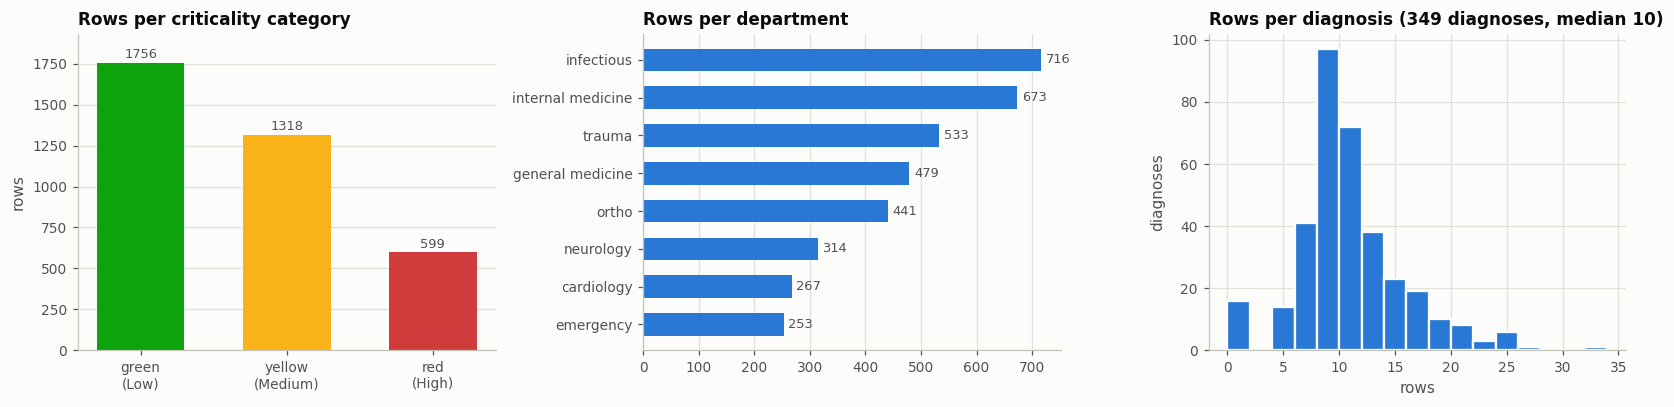

Rows without simulator attributes: 891 (24.2%). The simulator columns are missing on exactly the same rows: True


In [4]:
tmp = raw.copy(); tmp[TARGET_RAW] = tmp[TARGET_RAW].astype(str).str.strip()
order = ["Low Hazard", "Medium Hazard", "High Hazard"]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
vc = tmp[TARGET_RAW].value_counts().reindex(order)
b = ax[0].bar(["green\n(Low)", "yellow\n(Medium)", "red\n(High)"], vc.values, color=[LEVEL_COL[k] for k in range(3)], width=0.6)
bar_labels(ax[0], b, "{:.0f}"); ax[0].set_title("Rows per criticality category"); ax[0].set_ylabel("rows"); ax[0].grid(axis="x", visible=False); ax[0].set_ylim(0, vc.max() * 1.1)
dep = tmp["Avdeling"].str.strip().str.lower().value_counts().sort_values()
b = ax[1].barh(dep.index, dep.values, color=BLUE, height=0.6); bar_labels(ax[1], b, "{:.0f}", horizontal=True)
ax[1].set_title("Rows per department"); ax[1].grid(axis="y", visible=False)
rows_per_dx = raw.groupby("Diagnosis").size()
ax[2].hist(rows_per_dx, bins=range(0, rows_per_dx.max() + 3, 2), color=BLUE, edgecolor=SURFACE, linewidth=1.5)
ax[2].set_title(f"Rows per diagnosis ({raw.Diagnosis.nunique()} diagnoses, median {int(rows_per_dx.median())})"); ax[2].set_xlabel("rows"); ax[2].set_ylabel("diagnoses")
show("fig_explore")

same = raw[["Symptom.1", "Hazard", "DiscomfortLevel", "PatientMobility", "ShameLevel", "BleedingLevel"]].isna()
print(f"Rows without simulator attributes: {raw['Hazard'].isna().sum()} ({raw['Hazard'].isna().mean():.1%}).",
      "The simulator columns are missing on exactly the same rows:", bool((same["Hazard"] == same["ShameLevel"]).all()))

## 2.4 Verify data quality

In [5]:
q = []
dup_mask = raw.duplicated(keep=False)
q.append(("Exact duplicate rows", f"{int(raw.duplicated().sum())} (listed in §3.2)", "kept, with reason (§3.2)"))
const = [c for c in raw.columns if raw[c].nunique(dropna=True) <= 1]
q.append(("Constant columns", ", ".join(const), "drop"))
def same_ci(a, b):
    m = raw[a].notna() & raw[b].notna()
    return m.sum() > 0 and (raw.loc[m, a].astype(str).str.strip().str.upper() == raw.loc[m, b].astype(str).str.strip().str.upper()).mean() > 0.99
pairs = [(a, b) for a, b in [("Symptom", "Symptom.1"), ("Examination", "Examination 1"), ("Examination_2", "Examination 2"), ("Behandlding", "Treatment")] if same_ci(a, b)]
q.append(("Duplicate columns (ignoring case)", "; ".join(f"{a} = {b}" for a, b in pairs), "keep one"))
q.append(("Target categories (raw)", str(raw[TARGET_RAW].value_counts(dropna=False).to_dict()), "strip blanks -> 3 classes; drop rows without a label"))
praw = raw[P_COL].astype(str).str.strip(); is_pct = praw.str.fullmatch(r"-?\d+(\.\d+)? ?%")
bad_text = raw.loc[~is_pct & raw[P_COL].notna(), P_COL]
q.append(("Percentage column holds text", f"{len(bad_text)} rows (text spilled over from multi-line cells)", "set to missing"))
vals = pd.to_numeric(praw[is_pct].str.replace("%", "").str.strip(), errors="coerce")
q.append(("Percentage column: impossible values", f"{int((vals < 0).sum() + (vals > 100).sum())} outside 0-100", "set to missing"))
dc = [c for c in ["RiskOfCollapseStartHours", "RiskOfCollapseEndHours", "RiskOfDeathStartHours", "RiskOfDeathEndHours", "WalkSpeedModifier"] if raw[c].astype(str).str.contains(",").any()]
q.append(("Decimal comma in numeric columns", ", ".join(dc), "replace ',' by '.'"))
zero_bool = [c for c in ["IsMainSymptom", "PatientComplains", "Hazard"] if (raw[c].astype(str).str.strip() == "0").any()]
q.append(("Placeholder '0' in text columns", ", ".join(f"{c} ({(raw[c].astype(str).str.strip() == '0').sum()})" for c in zero_bool), "treat as missing"))
ex2 = raw["Examination_2"].dropna().astype(str).str.strip()
q.append(("Examination_2 holds treatment text", f"{int(ex2.str.endswith('.').sum())} values such as 'rest.' or 'NSAIDs.'", "set to missing"))
na_swallowed = int(raw_default["DiscomfortLevel"].isna().sum() - raw["DiscomfortLevel"].isna().sum())
q.append(("Default reading of the file", f"{na_swallowed} real 'None' values of DiscomfortLevel become missing", "read with keep_default_na=False"))
both = raw["Hazard"].notna()
agree = (raw.loc[both, "Hazard"].astype(str).str.strip().str.lower() == raw.loc[both, TARGET_RAW].astype(str).str.replace("Hazard", "").str.strip().str.lower())
q.append(("Hazard against the label", f"same value on {agree.mean():.1%} of {int(both.sum())} rows where both exist", "LEAK -> excluded"))
quality = pd.DataFrame(q, columns=["check", "finding", "action"])
display(quality)

,check,finding,action
0,Exact duplicate rows,8 (listed in §3.2),"kept, with reason (§3.2)"
1,Constant columns,"PlanAllTreatments, Required Equipment(s)",drop
2,Duplicate columns (ignoring case),Symptom = Symptom.1,keep one
3,Target categories (raw),"{' Low Hazard': 1756, ' Medium Hazard': 1315, ' High Hazard ': 592, ' High Hazard': 7,...",strip blanks -> 3 classes; drop rows without a label
4,Percentage column holds text,3 rows (text spilled over from multi-line cells),set to missing
5,Percentage column: impossible values,1 outside 0-100,set to missing
6,Decimal comma in numeric columns,"RiskOfCollapseStartHours, RiskOfCollapseEndHours, RiskOfDeathStartHours, RiskOfDeathEn...","replace ',' by '.'"
7,Placeholder '0' in text columns,"IsMainSymptom (32), PatientComplains (32), Hazard (32)",treat as missing
8,Examination_2 holds treatment text,134 values such as 'rest.' or 'NSAIDs.',set to missing
9,Default reading of the file,531 real 'None' values of DiscomfortLevel become missing,read with keep_default_na=False


## 2.5 Structure checks – the answer to "where does the symptom figure into it?"
Before any model we check how the label relates to the symptom, and how symptoms become known. These checks decide the whole design.

In [6]:
t = raw.copy()
t["lvl"] = t[TARGET_RAW].astype(str).str.strip().map({"Low Hazard": 0, "Medium Hazard": 1, "High Hazard": 2})
t = t[t.lvl.notna()]
t["Symptom"] = t["Symptom"].astype(str).str.strip()
g = t.groupby("Symptom")
n_lab = g.lvl.nunique(); n_dx = g.Diagnosis.nunique()
iv = t["Interview reveal"].astype(str).str.strip().str.upper().eq("TRUE")
pnum = pd.to_numeric(t[P_COL].astype(str).str.replace("%", "").str.strip(), errors="coerce")
main = t["IsMainSymptom"].astype(str).str.strip().str.upper().eq("TRUE")

STRUCT = {
 "symptom names": int(len(n_lab)),
 "symptoms that always have the same colour": int((n_lab == 1).sum()),
 "share of rows whose symptom also appears in another diagnosis": float(t.Symptom.map(n_dx).gt(1).mean()),
 "symptoms where DiscomfortLevel varies between rows": int((g["DiscomfortLevel"].nunique(dropna=True) > 1).sum()),
 "symptoms where PatientMobility varies between rows": int((g["PatientMobility"].nunique(dropna=True) > 1).sum()),
 "share of red among interview-revealed rows": float(t.lvl[iv].eq(2).mean()),
 "share of red among rows NOT revealed by interview": float(t.lvl[~iv].eq(2).mean()),
 "share of red rows that are not revealed by interview": float((~iv)[t.lvl == 2].mean()),
 "mean percentage for main symptoms": float(pnum[main].mean()),
 "mean percentage for other symptoms": float(pnum[~main & t["IsMainSymptom"].notna()].mean()),
}
display(pd.Series(STRUCT).to_frame("value").round(3))
print("Symptoms with more than one colour:", n_lab[n_lab > 1].index.tolist())
print("\nReading:")
print(f"1. The colour belongs to the symptom: {STRUCT['symptoms that always have the same colour']} of {STRUCT['symptom names']} symptom names always have the same colour, and the simulator attributes never vary within a symptom.")
print("   -> a lookup table symptom -> colour is exact for every symptom it knows. A model is only needed where a table has no entry.")
print(f"2. Critical findings are mostly hidden at the desk: {STRUCT['share of red among interview-revealed rows']:.1%} of interview-revealed rows are red, against "
      f"{STRUCT['share of red among rows NOT revealed by interview']:.1%} of the others; {STRUCT['share of red rows that are not revealed by interview']:.0%} of all red rows need an examination.")
print(f"3. The percentage column is {STRUCT['mean percentage for main symptoms']:.0f} % for main symptoms and {STRUCT['mean percentage for other symptoms']:.0f} % on average for the others:")
print("   it behaves like 'share of cases in which the symptom occurs' (confirmed against the course workbook in the next cell).")

,value
symptom names,608.000
symptoms that always have the same colour,605.000
share of rows whose symptom also appears in another diagnosis,0.900
symptoms where DiscomfortLevel varies between rows,0.000
symptoms where PatientMobility varies between rows,0.000
share of red among interview-revealed rows,0.058
share of red among rows NOT revealed by interview,0.384
share of red rows that are not revealed by interview,0.761
mean percentage for main symptoms,100.000
mean percentage for other symptoms,64.488


Symptoms with more than one colour: ['S. Typhi Detected', 'Trypanosoma Detected', 'Ulnar Fracture']

Reading:
1. The colour belongs to the symptom: 605 of 608 symptom names always have the same colour, and the simulator attributes never vary within a symptom.
   -> a lookup table symptom -> colour is exact for every symptom it knows. A model is only needed where a table has no entry.
2. Critical findings are mostly hidden at the desk: 5.8% of interview-revealed rows are red, against 38.4% of the others; 76% of all red rows need an examination.
3. The percentage column is 100 % for main symptoms and 64 % on average for the others:
   it behaves like 'share of cases in which the symptom occurs' (confirmed against the course workbook in the next cell).


In [7]:
# Optional check against the course workbook (Akerhus_universitetssykehus_V3_5_JF.xlsx), if the file is next to the notebook.
# The workbook keeps the original text of the percentage, e.g. "70% of cases | Low Hazard", and states how each symptom is "revealed".
XLSX = next((p for p in ["Akerhus_universitetssykehus_V3_5_JF.xlsx", "/content/Akerhus_universitetssykehus_V3_5_JF.xlsx",
                         "../Akerhus_universitetssykehus_V3_5_JF.xlsx"] if os.path.exists(p)), None)
WORKBOOK_CHECK = None
if XLSX is None:
    print("Workbook not found next to the notebook - check skipped. (Result when we ran it: the percentage equals the workbook text 'X% of cases' on all 3,673 labelled rows.)")
else:
    try:
        import openpyxl
        ws = openpyxl.load_workbook(XLSX, read_only=True, data_only=True)["Data_og_risiko_profil"]
        n = ok = 0
        for row in ws.iter_rows(min_row=2, max_col=54, values_only=True):
            h, txt = row[7], row[53]
            m_ = re.match(r"\s*(-?\d+)% of cases", str(txt)) if txt is not None else None
            if m_ is None or h is None: continue
            n += 1
            try: ok += abs(float(h) - int(m_.group(1)) / 100) < 1e-9
            except (TypeError, ValueError): pass
        WORKBOOK_CHECK = {"rows compared": n, "percentage equals 'X% of cases'": int(ok)}
        print(WORKBOOK_CHECK)
        print("Weights in the workbook's traffic-light sheet: Low 0.25, Medium 0.5, High 1; risk = weight x percentage; patient value = MAX over the patient's symptoms.")
    except Exception as e:
        print("Workbook check skipped:", type(e).__name__, e)

Workbook not found next to the notebook - check skipped. (Result when we ran it: the percentage equals the workbook text 'X% of cases' on all 3,673 labelled rows.)


**Consequences for the design.**

1. **Symptom level.** For a symptom the archive knows, use the lookup. The model's job is a symptom the archive does *not* know. So the model must be tested on **unseen symptoms**, and its inputs must be things that can be observed for a new symptom (§4).
2. **Patient level.** The danger at the desk is the hidden finding. The model's job is to estimate, from what is known at the desk, the risk that the patient is in fact red (§5).
3. **Examinations** are not predictors. They say when a symptom becomes known (§3.3).

# 3. Data preparation
Steps of the data-processing lecture: **select → clean → construct → integrate → format**. The selection by role is the table in §2.2 and is summarised again in §3.4.

## 3.1–3.2 Clean data
Every step is logged. The log is the data-cleaning report.

In [8]:
clog = []
def log(step, affected, action): clog.append({"step": step, "rows/values affected": affected, "action": action})

# 1) blanks
df = raw.apply(lambda s: s.map(lambda v: v.strip() if isinstance(v, str) else v))
df.insert(0, "raw_row", raw.index)
log("Strip leading/trailing blanks", "all text cells", "str.strip()")

# 2) target
df["y"] = df[TARGET_RAW].map({"Low Hazard": 0, "Medium Hazard": 1, "High Hazard": 2})
n_no_target = int(df["y"].isna().sum())
df = df[df["y"].notna()].reset_index(drop=True); df["y"] = df["y"].astype(int)
log("Target: ' High Hazard' and 'High Hazard ' are the same class", f"{len(raw)} rows", "mapped to 0 green / 1 yellow / 2 red")
log("Target missing", n_no_target, "rows dropped")

# 3) percentage column = share of cases in which the symptom occurs
praw = df[P_COL].astype(str); is_pct = praw.str.fullmatch(r"-?\d+(\.\d+)? ?%")
p = pd.to_numeric(praw.where(is_pct).str.replace("%", "", regex=False).str.strip(), errors="coerce")
log("Percentage column: text in the cell", int((~is_pct & df[P_COL].notna()).sum()), "set to missing")
log("Percentage column: values below 0 or above 100", int(((p < 0) | (p > 100)).sum()), "set to missing")
df["occ_pct"] = p.mask((p < 0) | (p > 100))

# 4) numbers stored as text with a decimal comma
def to_num(s): return pd.to_numeric(s.astype(str).str.replace(",", ".", regex=False).str.strip(), errors="coerce")
num_map = {"ShameLevel": "shame", "BleedingLevel": "bleeding", "WalkSpeedModifier": "walk_mod", "RiskOfCollapseStartHours": "collapse_start",
           "RiskOfCollapseEndHours": "collapse_end", "RiskOfDeathStartHours": "death_start", "RiskOfDeathEndHours": "death_end", "Kostnader($)": "cost"}
for src, dst in num_map.items(): df[dst] = to_num(df[src])
log("Numeric columns stored as text (decimal comma)", f"{len(num_map)} columns", "replace ',' by '.', convert")

# 5) booleans
def to_bool(s): return s.map(lambda v: {"TRUE": 1, "FALSE": 0}.get(str(v).strip().upper(), np.nan))
for src, dst in {"Interview reveal": "interview", "IsMainSymptom": "is_main", "PatientComplains": "complains", "CannotTalk": "cannot_talk"}.items(): df[dst] = to_bool(df[src])
df["cannot_talk"] = df["cannot_talk"].fillna(df["CannotTalk"].map(lambda v: 0 if str(v).strip() == "0" else np.nan))      # '0' means no
n_zero = int((df["IsMainSymptom"].astype(str) == "0").sum())
log("TRUE/FALSE stored as text; '0' placeholders", f"4 columns, {n_zero} placeholders", "to 1/0; placeholder -> missing (CannotTalk: '0' = no)")

# 6) categories
def cat(s, zero=np.nan): return s.mask(s.astype(str).eq("0"), zero)
df["discomfort"] = cat(df["DiscomfortLevel"])                     # 'None' is a real value; '0' is a placeholder
df["mobility"] = cat(df["PatientMobility"])
df["collapse_symptom"] = cat(df["CollapseSymptom"], "None")       # '0' = no collapse symptom
df["common"] = df["Common/uncommon"]; df["avdeling"] = df["Avdeling"].str.lower()
log("Placeholder '0' in categories", f"{n_zero} rows", "'0' -> missing (discomfort, mobility); '0' -> 'None' (collapse symptom)")

# 7) examination text
treat_like = df["Examination_2"].notna() & df["Examination_2"].astype(str).str.endswith(".")
df["exam2_clean"] = df["Examination_2"].mask(treat_like)
log("Examination_2 holds treatment text ('rest.', 'NSAIDs.')", int(treat_like.sum()), "set to missing")

# 8) the block of rows without simulator attributes
df["has_attr"] = df["Hazard"].notna()
log("Rows without simulator attributes (same rows in 23 columns)", int((~df.has_attr).sum()), "kept; these symptoms have no bedside description")
print(f"Clean frame: {len(df)} rows, {df.Diagnosis.nunique()} diagnoses, {df.Symptom.nunique()} symptoms.")
print("Rows per colour:", {LEVEL_NAME[k]: int(v) for k, v in df.y.value_counts().sort_index().items()})

Clean frame: 3673 rows, 349 diagnoses, 608 symptoms.
Rows per colour: {'green': 1756, 'yellow': 1318, 'red': 599}


In [9]:
# 9) duplicate rows: which diagnoses are they? (question from the feedback)
dmask = df.drop(columns=["raw_row"]).duplicated(keep=False)
dups = (df[dmask].groupby(["Diagnosis", "Symptom"]).agg(copies=("y", "size"), colour=("y", lambda s: LEVEL_NAME[int(s.iloc[0])]), department=("avdeling", "first")).reset_index())
n_extra = int(df.drop(columns=["raw_row"]).duplicated().sum())
print(f"{n_extra} rows are exact copies of another row. They sit in {len(dups)} diagnosis/symptom pairs:")
display(dups)
log("Duplicate rows", n_extra, "kept: a copy has the same diagnosis and the same symptom as its original, so it always falls on the same side of every split; "
                              "patients are drawn per diagnosis, so a copy only makes that diagnosis slightly more likely")

# 10) outliers: screen only. The numeric columns are bounded codes (hours, 0-5 scales).
rows = []
for c in ["occ_pct", "shame", "bleeding", "walk_mod", "collapse_start", "collapse_end", "death_start", "death_end"]:
    x = df[c].dropna(); q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    out = int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()) if iqr > 0 else int((x != x.median()).sum())
    rows.append((c, x.min(), x.median(), x.max(), out))
outl = pd.DataFrame(rows, columns=["column", "min", "median", "max", "values flagged (1.5 IQR)"]); display(outl)
log("Outliers (IQR screen)", int(outl.iloc[:, 4].sum()), "kept: legitimate rare states (long collapse windows, heavy bleeding), not entry errors")
report = pd.DataFrame(clog); print("\nDATA CLEANING REPORT"); display(report)
report.to_csv(f"{OUT_DIR}/data_cleaning_report.csv", index=False)

8 rows are exact copies of another row. They sit in 8 diagnosis/symptom pairs:


,Diagnosis,Symptom,copies,colour,department
0,Appendicitis,Abdominal Cramps,2,yellow,general medicine
1,Appendicitis,Diarrhea,2,green,general medicine
2,Appendicitis,Fever,2,yellow,general medicine
3,Conjunctivitis,Blurred Vision,2,green,neurology
4,Conjunctivitis,Burning Eye,2,green,neurology
5,Conjunctivitis,Itchy Eyes,2,green,neurology
6,Conjunctivitis,Red Eye,2,green,neurology
7,Conjunctivitis,Watery Eyes,2,green,neurology


,column,min,median,max,values flagged (1.5 IQR)
0,occ_pct,0.0,70.0,100.0,163
1,shame,0.0,30.0,90.0,0
2,bleeding,0.0,0.0,5.0,66
3,walk_mod,0.0,0.0,0.5,93
4,collapse_start,0.0,0.0,6.0,329
5,collapse_end,0.0,0.0,24.0,329
6,death_start,0.0,0.0,2.0,48
7,death_end,0.0,0.0,24.0,48



DATA CLEANING REPORT


,step,rows/values affected,action
0,Strip leading/trailing blanks,all text cells,str.strip()
1,Target: ' High Hazard' and 'High Hazard ' are the same class,3676 rows,mapped to 0 green / 1 yellow / 2 red
2,Target missing,3,rows dropped
3,Percentage column: text in the cell,0,set to missing
4,Percentage column: values below 0 or above 100,1,set to missing
5,Numeric columns stored as text (decimal comma),8 columns,"replace ',' by '.', convert"
6,TRUE/FALSE stored as text; '0' placeholders,"4 columns, 32 placeholders",to 1/0; placeholder -> missing (CannotTalk: '0' = no)
7,Placeholder '0' in categories,32 rows,"'0' -> missing (discomfort, mobility); '0' -> 'None' (collapse symptom)"
8,"Examination_2 holds treatment text ('rest.', 'NSAIDs.')",134,set to missing
9,Rows without simulator attributes (same rows in 23 columns),888,kept; these symptoms have no bedside description


## 3.3 Construct data

| New attribute | Built from | Why |
|---|---|---|
| `stage` | `Interview reveal`, `Examination`, `Examination_2` | **When the symptom becomes known:** 0 = interview at the desk, 1 = bedside examination, 2 = instrument, laboratory or imaging. This is the only use of the examination columns. |
| `immobile`, `limp` | `PatientMobility`, `WalkSpeedModifier` | Bedside observations as 0/1. |
| `discomfort_ord` | `DiscomfortLevel` | None 0, Low 1, Medium 2, High 3. |
| `bedside_flags` | `CannotTalk`, `immobile`, `BleedingLevel` | Number of red flags a nurse can see (0–3). The **red-flag rule** says red when it is 1 or more. |
| `has_collapse`, `has_death_risk` | collapse and death-risk columns | Prognosis known once a symptom is identified. |
| `occ` | percentage column | Share of cases with the symptom, 0–1. Missing values get the median. |

In [10]:
def exam_level(a, b):
    # 0 = interview, 1 = bedside examination, 2 = instrument / laboratory / imaging
    BEDSIDE = r"physical|inspection|palpation|auscultation|percussion|measurement|visual"
    lv = []
    for e in (a, b):
        if not isinstance(e, str): continue
        e = e.lower(); lv.append(0 if "interview" in e else (1 if re.search(BEDSIDE, e) else 2))
    return min(lv) if lv else np.nan            # the easiest way to reveal the symptom decides

df["exam_lvl"] = [exam_level(a, b) for a, b in zip(df["Examination"], df["exam2_clean"])]
df["stage"] = np.where(df.interview == 1, 0, np.where(df.exam_lvl == 1, 1, 2)).astype(int)
df["immobile"] = np.where(df.mobility.isna(), np.nan, df.mobility.isin(["IMMOBILE", "INTUBATED"]).astype(float))
df["limp"] = np.where(df.walk_mod.isna(), np.nan, (df.walk_mod > 0).astype(float))
df["discomfort_ord"] = df.discomfort.map({"None": 0, "Low": 1, "Medium": 2, "High": 3})
df["bedside_flags"] = np.where(df.has_attr, df[["cannot_talk", "immobile"]].fillna(0).sum(axis=1) + (df.bleeding.fillna(0) > 0), np.nan)
df["has_collapse"] = np.where(df.collapse_symptom.isna() | ~df.has_attr, np.nan, (df.collapse_symptom != "None").astype(float))
df["has_death_risk"] = np.where(df.death_end.isna(), np.nan, (df.death_end > 0).astype(float))
df["occ"] = (df.occ_pct / 100).fillna(df.occ_pct.median() / 100).clip(0.01, 1.0)

stage_tab = pd.crosstab(df.stage.map({0: "0 interview (desk)", 1: "1 bedside examination", 2: "2 instrument / lab / imaging"}), df.y.map(LEVEL_NAME))[["green", "yellow", "red"]]
stage_tab["rows"] = stage_tab.sum(axis=1); stage_tab["share red"] = (stage_tab["red"] / stage_tab["rows"]).round(3)
print("When does a symptom become known, and how urgent is it?"); display(stage_tab)
flag_tab = df[df.has_attr].groupby("bedside_flags").agg(rows=("y", "size"), share_red=("y", lambda s: (s == 2).mean())).round(3)
print("Visible red flags and the share of red rows:"); display(flag_tab)

When does a symptom become known, and how urgent is it?


y,green,yellow,red,rows,share red
stage,,,,,
0 interview (desk),1373,970,143,2486,0.058
1 bedside examination,70,131,137,338,0.405
2 instrument / lab / imaging,313,217,319,849,0.376


Visible red flags and the share of red rows:


,rows,share_red
bedside_flags,,
0.0,2572,0.075
1.0,131,0.786
2.0,79,1.000
3.0,3,1.000


## 3.3b Integrate – the symptom table
The colour and the simulator attributes are properties of the symptom, so we build one row per symptom. This table is the **lookup** of §4.1 and the data set for the symptom-level model of §4.2.

In [11]:
first = lambda s: s.dropna().iloc[0] if s.notna().any() else np.nan
SYM = df.groupby("Symptom").agg(
    y=("y", "max"), n_rows=("y", "size"), n_dx=("Diagnosis", "nunique"), has_attr=("has_attr", "max"), stage=("stage", "min"),
    cannot_talk=("cannot_talk", first), bleeding=("bleeding", first), immobile=("immobile", first), limp=("limp", first), complains=("complains", first),
    shame=("shame", first), mobility=("mobility", first), discomfort=("discomfort", first), discomfort_ord=("discomfort_ord", first),
    bedside_flags=("bedside_flags", first), has_collapse=("has_collapse", first), collapse_start=("collapse_start", first), collapse_end=("collapse_end", first),
    has_death_risk=("has_death_risk", first), death_start=("death_start", first), death_end=("death_end", first), collapse_symptom=("collapse_symptom", first),
    hazard=("Hazard", first)).reset_index()
SYM["hazard_ord"] = SYM.hazard.map({"Low": 0, "Medium": 1, "High": 2})
print(f"Symptom table: {len(SYM)} symptoms | with simulator attributes: {int(SYM.has_attr.sum())} | without: {int((~SYM.has_attr).sum())}")
print("Colour by availability of attributes:"); display(pd.crosstab(SYM.has_attr.map({True: "with attributes", False: "without attributes"}), SYM.y.map(LEVEL_NAME))[["green", "yellow", "red"]])
print("Symptoms that appear in only one diagnosis:", int((SYM.n_dx == 1).sum()), "| of these revealed by interview:", int(((SYM.n_dx == 1) & (SYM.stage == 0)).sum()))

Symptom table: 608 symptoms | with simulator attributes: 351 | without: 257
Colour by availability of attributes:


y,green,yellow,red
has_attr,,,
with attributes,165,118,68
without attributes,77,91,89


Symptoms that appear in only one diagnosis: 347 | of these revealed by interview: 5


## 3.4 Format – what is included, what is excluded, and when it is known
This table answers the request for a short overview of included and excluded columns.

In [12]:
avail = pd.DataFrame([
 ("Symptom name", "KEY", "used as lookup key", "when the symptom is revealed", "§4.1, §5"),
 ("CannotTalk, PatientMobility, BleedingLevel, WalkSpeedModifier, PatientComplains, ShameLevel", "BEDSIDE", "model input", "at the desk, by looking at the patient", "§4, §5"),
 ("DiscomfortLevel", "BEDSIDE", "model input, tested with and without", "at the desk; very close to the label", "§4.3, §5.4"),
 ("CollapseSymptom, RiskOfCollapse*, RiskOfDeath*", "PROGNOSIS", "upper reference only; deterioration deadline in the queue", "only once the symptom is identified", "§4.3, §6"),
 ("Interview reveal, Examination, Examination_2", "REVEAL", "NOT a predictor; defines the stage at which a symptom is known", "always (it describes how a symptom is found)", "§3.3"),
 ("Percentage (share of cases with the symptom)", "DX", "used to generate patients and in the knowledge-base risk", "only with the diagnosis", "§5.1"),
 ("Avdeling, Common/uncommon, IsMainSymptom", "DX", "NOT a predictor; subgroups and department recommendation", "only with the diagnosis", "§5.7, §5.9"),
 ("Hazard", "LEAK", "EXCLUDED (shown once as a leakage demonstration)", "copy of the label", "§4.3"),
 ("Treatment, rooms, surgery, cost", "TREAT", "EXCLUDED", "after the diagnosis", "-"),
 ("22 duplicate, constant, free-text and graphics columns", "DROP", "EXCLUDED", "-", "-")],
 columns=["columns", "role", "use in this project", "known when", "where"])
display(avail)
avail.to_csv(f"{OUT_DIR}/column_use_table.csv", index=False); coltab.to_csv(f"{OUT_DIR}/column_dictionary.csv", index=False)
SYM.to_csv(f"{OUT_DIR}/symptom_table.csv", index=False)

,columns,role,use in this project,known when,where
0,Symptom name,KEY,used as lookup key,when the symptom is revealed,"§4.1, §5"
1,"CannotTalk, PatientMobility, BleedingLevel, WalkSpeedModifier, PatientComplains, Shame...",BEDSIDE,model input,"at the desk, by looking at the patient","§4, §5"
2,DiscomfortLevel,BEDSIDE,"model input, tested with and without",at the desk; very close to the label,"§4.3, §5.4"
3,"CollapseSymptom, RiskOfCollapse*, RiskOfDeath*",PROGNOSIS,upper reference only; deterioration deadline in the queue,only once the symptom is identified,"§4.3, §6"
4,"Interview reveal, Examination, Examination_2",REVEAL,NOT a predictor; defines the stage at which a symptom is known,always (it describes how a symptom is found),§3.3
5,Percentage (share of cases with the symptom),DX,used to generate patients and in the knowledge-base risk,only with the diagnosis,§5.1
6,"Avdeling, Common/uncommon, IsMainSymptom",DX,NOT a predictor; subgroups and department recommendation,only with the diagnosis,"§5.7, §5.9"
7,Hazard,LEAK,EXCLUDED (shown once as a leakage demonstration),copy of the label,§4.3
8,"Treatment, rooms, surgery, cost",TREAT,EXCLUDED,after the diagnosis,-
9,"22 duplicate, constant, free-text and graphics columns",DROP,EXCLUDED,-,-


# 4. Modelling, part A – the colour of a symptom

## 4.1 The lookup rule: exact for known symptoms
First the simplest method. Build a table *symptom → colour* from the diagnoses used for training and apply it to diagnoses the table has not seen. This is the validation design of version 3 (split by diagnosis). If the lookup is exact there, a model adds nothing for known symptoms.

In [13]:
def level_metrics(y, pred):
    y, pred = np.asarray(y), np.asarray(pred)
    rec = recall_score(y, pred, labels=[0, 1, 2], average=None, zero_division=0)
    return {"macro_f1": f1_score(y, pred, labels=[0, 1, 2], average="macro", zero_division=0), "red_recall": rec[2], "under_triage": float((pred < y).mean()),
            "over_triage": float((pred > y).mean()), "accuracy": float((pred == y).mean())}

yy, gg = df.y.to_numpy(), df.Diagnosis.to_numpy()
rows = []
for rep in range(3):
    known = np.zeros(len(df), bool); pred = np.zeros(len(df), int)
    for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=SEED + rep).split(df, yy, gg):
        table = df.iloc[tr].groupby("Symptom").y.max()
        hit = df.iloc[te].Symptom.map(table)
        known[te] = hit.notna().to_numpy(); pred[te] = hit.fillna(0).astype(int).to_numpy()
    for name, m in [("all rows", np.ones(len(df), bool)), ("revealed by interview (stage 0)", (df.stage == 0).to_numpy()), ("revealed by examination (stage 1-2)", (df.stage > 0).to_numpy())]:
        k = known & m
        rows.append({"rows": name, "n": int(m.sum()), "symptom is in the table": known[m].mean(), "correct when in the table": (pred[k] == yy[k]).mean(),
                     "red recall when in the table": (pred[k & (yy == 2)] == 2).mean(), "share red among symptoms NOT in the table": (yy[m & ~known] == 2).mean()})
LOOKUP = pd.DataFrame(rows).groupby("rows", sort=False).mean().round(3)
display(LOOKUP)
print("Reading: for unseen DIAGNOSES the table already knows the symptom in about 9 of 10 rows, and then it is always right.")
print("At the desk (interview-revealed symptoms) it knows almost every symptom. What the table cannot do is a symptom it has never seen.")
print("So a model must be judged on UNSEEN SYMPTOMS. Version 3 judged it on unseen diagnoses, where most symptoms repeat; that made the task look easier than it is for a model and hid that a table solves it.")

,n,symptom is in the table,correct when in the table,red recall when in the table,share red among symptoms NOT in the table
rows,,,,,
all rows,3673.0,0.894,1.000,1.0,0.315
revealed by interview (stage 0),2486.0,0.992,1.000,1.0,0.033
revealed by examination (stage 1-2),1187.0,0.687,0.999,1.0,0.329


Reading: for unseen DIAGNOSES the table already knows the symptom in about 9 of 10 rows, and then it is always right.
At the desk (interview-revealed symptoms) it knows almost every symptom. What the table cannot do is a symptom it has never seen.
So a model must be judged on UNSEEN SYMPTOMS. Version 3 judged it on unseen diagnoses, where most symptoms repeat; that made the task look easier than it is for a model and hid that a table solves it.


## 4.2 Test design for the symptom model
* **Data:** the symptom table, one row per symptom. Only the 351 symptoms with simulator attributes can be described at the bedside; the other 257 are handled in §4.6.
* **Hold-out:** 20 % of the symptoms, set aside and used once (§4.5).
* **Development:** repeated stratified 5-fold cross-validation (3 repeats). Every prediction is for a symptom the model has not seen.
* **Metrics:** macro-F1, recall of red, under-triage, over-triage. Uncertainty: standard deviation over repeats, bootstrap interval on the hold-out.

**Feature sets** (what is observable for a symptom nobody has catalogued yet):

| Set | Content | Eligible under C3? |
|---|---|---|
| S1 bedside | cannot talk, mobility, visible bleeding, limping, complains, shame, stage at which the symptom was found | yes |
| S2 = S1 + discomfort | adds `DiscomfortLevel` | yes, but close to the label |
| S3 = S2 + prognosis | adds collapse and death-risk information | no – only known for a catalogued symptom |
| S4 = S3 + Hazard | adds the copy of the label | no – leakage, shown as a warning |

In [14]:
A = SYM[SYM.has_attr].reset_index(drop=True)
A_dev, A_test = train_test_split(A, test_size=0.20, stratify=A.y, random_state=SEED)
A_dev, A_test = A_dev.reset_index(drop=True), A_test.reset_index(drop=True)
print("Symptoms with attributes:", len(A), "| development:", len(A_dev), "| hold-out:", len(A_test))
print("Colours (dev):", {LEVEL_NAME[k]: int(v) for k, v in A_dev.y.value_counts().sort_index().items()}, "| (hold-out):", {LEVEL_NAME[k]: int(v) for k, v in A_test.y.value_counts().sort_index().items()})

S1_NUM, S1_CAT = ["cannot_talk", "bleeding", "limp", "complains", "shame", "stage"], ["mobility"]
PROG_NUM, PROG_CAT = ["has_collapse", "collapse_start", "collapse_end", "has_death_risk", "death_start", "death_end"], ["collapse_symptom"]
SETS = {"S1 bedside": (S1_NUM, S1_CAT), "S2 + discomfort": (S1_NUM, S1_CAT + ["discomfort"]),
        "S3 + prognosis": (S1_NUM + PROG_NUM, S1_CAT + ["discomfort"] + PROG_CAT), "S4 + Hazard (leak)": (S1_NUM + PROG_NUM, S1_CAT + ["discomfort"] + PROG_CAT + ["hazard"])}
ELIGIBLE = ["S1 bedside", "S2 + discomfort"]

def make_pre(nums, cats, scale=False):
    num_steps = [("imp", SimpleImputer(strategy="median", add_indicator=True))] + ([("sc", StandardScaler())] if scale else [])
    parts = [("num", Pipeline(num_steps), nums)]
    if cats: parts.append(("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")), ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cats))
    return ColumnTransformer(parts)

RF_PARAMS = dict(n_estimators=200, min_samples_leaf=2, max_features=0.6)
def make_model(name, rf=None):
    if name == "Majority class":      return DummyClassifier(strategy="most_frequent")
    if name == "Logistic regression": return LogisticRegression(max_iter=3000, class_weight="balanced")
    if name == "Decision tree":       return DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, class_weight="balanced", random_state=SEED)
    if name == "Random forest":       return RandomForestClassifier(**{**RF_PARAMS, **(rf or {})}, class_weight="balanced", n_jobs=-1, random_state=SEED)
    if name == "Gradient boosting":   return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.1, max_iter=60, class_weight="balanced", random_state=SEED)
    raise ValueError(name)
def make_pipe(name, nums, cats, rf=None): return Pipeline([("pre", make_pre(nums, cats, scale=(name == "Logistic regression"))), ("m", make_model(name, rf))])

def cv_symptom(name, fs, data=None, repeats=3, seed0=SEED, rf=None):
    data = A_dev if data is None else data; nums, cats = SETS[fs] if isinstance(fs, str) else fs
    X, y = data[nums + cats], data.y.to_numpy(); per_rep, first = [], None
    for r in range(repeats):
        proba = np.zeros((len(data), 3))
        for tr, va in StratifiedKFold(5, shuffle=True, random_state=seed0 + r).split(X, y):
            proba[va] = make_pipe(name, nums, cats, rf).fit(X.iloc[tr], y[tr]).predict_proba(X.iloc[va])
        per_rep.append(level_metrics(y, proba.argmax(1)))
        if r == 0: first = proba
    R = pd.DataFrame(per_rep)
    return {"model": name, "features": fs if isinstance(fs, str) else "custom", **R.mean().to_dict(), **{k + "_sd": v for k, v in R.std(ddof=0).to_dict().items()}}, first

Symptoms with attributes: 351 | development: 280 | hold-out: 71
Colours (dev): {'green': 132, 'yellow': 94, 'red': 54} | (hold-out): {'green': 33, 'yellow': 24, 'red': 14}


## 4.3 Build models
Initial settings: logistic regression (L2, balanced class weights, scaled inputs); decision tree (depth ≤ 4, at least 5 symptoms per leaf); random forest (200 trees, at least 2 symptoms per leaf); gradient boosting (60 shallow trees). Balanced class weights because red symptoms are the minority (19 % of the symptoms with attributes). Two baselines: the majority class and the red-flag rule.

In [15]:
t0 = time.time(); RES_A, OOF_A = [], {}
def run_a(name, fs, **kw):
    r, o = cv_symptom(name, fs, **kw); RES_A.append(r); OOF_A[(name, fs)] = o; return r
for fs in SETS:
    for m_ in ["Logistic regression", "Decision tree", "Random forest", "Gradient boosting"]: run_a(m_, fs)
run_a("Majority class", "S1 bedside")
rule = level_metrics(A_dev.y, np.where(A_dev.bedside_flags >= 1, 2, 0))          # red-flag rule: any visible red flag -> red, otherwise green
RES_A.append({"model": "Red-flag rule", "features": "bedside flags", **rule, **{k + "_sd": 0.0 for k in rule}})
TA = pd.DataFrame(RES_A)
show_cols = ["model", "features", "macro_f1", "macro_f1_sd", "red_recall", "red_recall_sd", "under_triage", "over_triage", "accuracy"]
display(TA[show_cols].sort_values(["features", "macro_f1"], ascending=[True, False]).round(3).reset_index(drop=True))
print(f"({time.time() - t0:.0f} s)")

,model,features,macro_f1,macro_f1_sd,red_recall,red_recall_sd,under_triage,over_triage,accuracy
0,Random forest,S1 bedside,0.487,0.012,0.519,0.040,0.208,0.308,0.483
1,Logistic regression,S1 bedside,0.454,0.010,0.759,0.094,0.165,0.381,0.454
2,Decision tree,S1 bedside,0.446,0.025,0.574,0.099,0.215,0.337,0.448
3,Gradient boosting,S1 bedside,0.440,0.004,0.679,0.057,0.175,0.377,0.448
4,Majority class,S1 bedside,0.214,0.000,0.000,0.000,0.529,0.000,0.471
5,Random forest,S2 + discomfort,0.635,0.009,0.438,0.017,0.192,0.148,0.661
6,Logistic regression,S2 + discomfort,0.634,0.013,0.722,0.000,0.113,0.240,0.646
7,Gradient boosting,S2 + discomfort,0.589,0.001,0.611,0.066,0.126,0.269,0.605
8,Decision tree,S2 + discomfort,0.563,0.013,0.549,0.009,0.163,0.252,0.585
9,Logistic regression,S3 + prognosis,0.827,0.012,0.963,0.000,0.136,0.057,0.807


(28 s)


## 4.4 Assess
The rule is a constrained choice: **maximise macro-F1 subject to C1 (red recall ≥ 0.90), C2 (macro-F1 ≥ 0.80) and C3 (only S1 or S2).** A model without `DiscomfortLevel` is preferred if it meets C1 and C2.

Best model per feature set (cross-validation on unseen symptoms):


,model,macro_f1,macro_f1_sd,red_recall,red_recall_sd,under_triage,over_triage,eligible (C3),C1 red recall>=0.90,C2 macro-F1>=0.80
features,,,,,,,,,,
S1 bedside,Random forest,0.487,0.012,0.519,0.040,0.208,0.308,True,False,False
S2 + discomfort,Random forest,0.635,0.009,0.438,0.017,0.192,0.148,True,False,False
S3 + prognosis,Logistic regression,0.827,0.012,0.963,0.000,0.136,0.057,False,True,True
S4 + Hazard (leak),Random forest,0.990,0.002,0.975,0.009,0.008,0.000,False,True,True



RESULT: NO eligible model meets C1 and C2. From bedside observations alone the best macro-F1 is 0.63 and the best red recall 0.76.
With the prognosis columns (S3) the criteria are met (macro-F1 0.83, red recall 0.96), but those columns are only known for a symptom that is already catalogued.
With Hazard (S4) the result is near-perfect (macro-F1 0.99): this is leakage, not skill.
-> For a symptom the archive does not know, the colour cannot be read off the patient. Such a symptom needs an examination; until then it is handled by the patient-level risk model (§5).


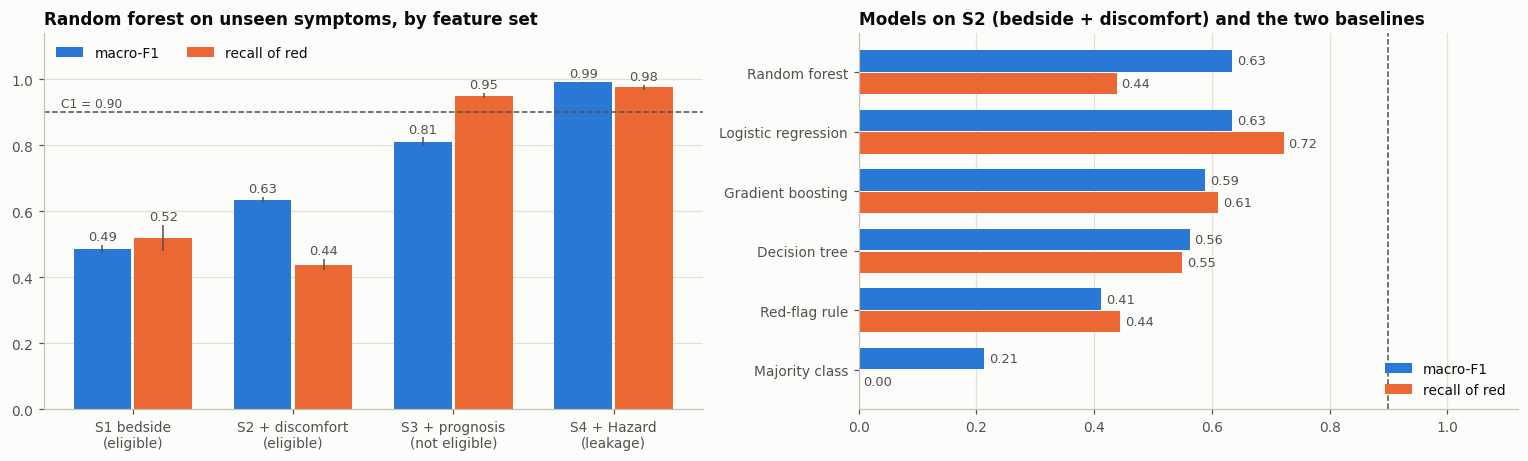

In [16]:
best = TA[TA.features.isin(SETS)].sort_values("macro_f1", ascending=False).groupby("features", sort=False).head(1).set_index("features").reindex(list(SETS))
best["eligible (C3)"] = [fs in ELIGIBLE for fs in best.index]
best["C1 red recall>=0.90"] = best.red_recall >= 0.90; best["C2 macro-F1>=0.80"] = best.macro_f1 >= 0.80
VERDICT_A = best[["model", "macro_f1", "macro_f1_sd", "red_recall", "red_recall_sd", "under_triage", "over_triage", "eligible (C3)", "C1 red recall>=0.90", "C2 macro-F1>=0.80"]]
print("Best model per feature set (cross-validation on unseen symptoms):"); display(VERDICT_A.round(3))
feasible = VERDICT_A[VERDICT_A["eligible (C3)"] & VERDICT_A["C1 red recall>=0.90"] & VERDICT_A["C2 macro-F1>=0.80"]]
A_FEASIBLE = len(feasible) > 0
max_rec = TA[TA.features.isin(ELIGIBLE)].red_recall.max()
print("\nRESULT:", "an eligible model meets C1 and C2." if A_FEASIBLE else
      f"NO eligible model meets C1 and C2. From bedside observations alone the best macro-F1 is {VERDICT_A.loc[ELIGIBLE, 'macro_f1'].max():.2f} and the best red recall {max_rec:.2f}.")
s3 = VERDICT_A.loc["S3 + prognosis"]
print(f"With the prognosis columns (S3) the criteria are met (macro-F1 {s3.macro_f1:.2f}, red recall {s3.red_recall:.2f}), but those columns are only known for a symptom that is already catalogued.")
print(f"With Hazard (S4) the result is near-perfect (macro-F1 {VERDICT_A.loc['S4 + Hazard (leak)', 'macro_f1']:.2f}): this is leakage, not skill.")
print("-> For a symptom the archive does not know, the colour cannot be read off the patient. Such a symptom needs an examination; until then it is handled by the patient-level risk model (§5).")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
order = list(SETS); x = np.arange(len(order)); wbar = 0.36
rf_ = TA[TA.model == "Random forest"].set_index("features").reindex(order)
b1 = ax[0].bar(x - wbar / 2 - 0.01, rf_.macro_f1, wbar, yerr=rf_.macro_f1_sd, color=BLUE, label="macro-F1", error_kw=dict(ecolor=INK2, lw=1))
b2 = ax[0].bar(x + wbar / 2 + 0.01, rf_.red_recall, wbar, yerr=rf_.red_recall_sd, color=ORANGE, label="recall of red", error_kw=dict(ecolor=INK2, lw=1))
bar_labels(ax[0], b1, err=rf_.macro_f1_sd); bar_labels(ax[0], b2, err=rf_.red_recall_sd)
ax[0].axhline(0.90, color=INK2, ls="--", lw=1); ax[0].text(-0.45, 0.915, "C1 = 0.90", fontsize=8, color=INK2)
ax[0].set_xticks(x); ax[0].set_xticklabels(["S1 bedside\n(eligible)", "S2 + discomfort\n(eligible)", "S3 + prognosis\n(not eligible)", "S4 + Hazard\n(leakage)"])
ax[0].set_ylim(0, 1.14); ax[0].legend(loc="upper left", ncol=2); ax[0].set_title("Random forest on unseen symptoms, by feature set"); ax[0].grid(axis="x", visible=False)
m2 = pd.concat([TA[TA.features == "S2 + discomfort"], TA[TA.model.isin(["Red-flag rule", "Majority class"])]]).sort_values("macro_f1"); yb = np.arange(len(m2))
b1 = ax[1].barh(yb + wbar / 2 + 0.01, m2.macro_f1, wbar, color=BLUE, label="macro-F1"); b2 = ax[1].barh(yb - wbar / 2 - 0.01, m2.red_recall, wbar, color=ORANGE, label="recall of red")
bar_labels(ax[1], b1, horizontal=True); bar_labels(ax[1], b2, horizontal=True)
ax[1].axvline(0.90, color=INK2, ls="--", lw=1); ax[1].set_yticks(yb); ax[1].set_yticklabels(m2.model); ax[1].set_xlim(0, 1.12); ax[1].legend(loc="lower right")
ax[1].set_title("Models on S2 (bedside + discomfort) and the two baselines"); ax[1].grid(axis="y", visible=False)
show("fig_symptom_models")

### Classification or regression?
The Health02 task allows both. The regressors predict the level as a number 0–2; the prediction is cut at 0.5 and 1.5. Same folds; feature set S3, where a model works.

In [17]:
def cv_regress(reg, fs, repeats=3):
    nums, cats = SETS[fs]; X, y = A_dev[nums + cats], A_dev.y.to_numpy(); per, first = [], None
    for r in range(repeats):
        yh = np.zeros(len(A_dev))
        for tr, va in StratifiedKFold(5, shuffle=True, random_state=SEED + r).split(X, y):
            est = Ridge(alpha=1.0) if reg == "Ridge regression" else RandomForestRegressor(n_estimators=150, min_samples_leaf=2, max_features=0.6, n_jobs=-1, random_state=SEED)
            yh[va] = Pipeline([("pre", make_pre(nums, cats, scale=(reg == "Ridge regression"))), ("m", est)]).fit(X.iloc[tr], y[tr]).predict(X.iloc[va])
        yh = np.clip(yh, 0, 2); m = level_metrics(y, np.digitize(yh, (0.5, 1.5))); m.update({"MAE": mean_absolute_error(y, yh), "R2": r2_score(y, yh)}); per.append(m)
        if r == 0: first = yh
    return {"model": reg, **pd.DataFrame(per).mean().to_dict()}, first
REG_A, YH = [], {}
for rn in ["Ridge regression", "RF regressor"]:
    r_, yh_ = cv_regress(rn, "S3 + prognosis"); REG_A.append(r_); YH[rn] = yh_
rf3 = TA[(TA.model == "Random forest") & (TA.features == "S3 + prognosis")].iloc[0]
cmp_ = pd.concat([pd.DataFrame(REG_A), pd.DataFrame([{"model": "Random forest (classifier)", **{k: rf3[k] for k in ["macro_f1", "red_recall", "under_triage", "over_triage", "accuracy"]}}])], ignore_index=True)
REG_TAB = cmp_[["model", "MAE", "R2", "macro_f1", "red_recall", "under_triage", "over_triage", "accuracy"]]; display(REG_TAB.round(3))
res_ = YH["RF regressor"] - A_dev.y.to_numpy()
REG_DIAG = {"skewness": float(stats.skew(res_)), "excess kurtosis": float(stats.kurtosis(res_)), "Spearman(|residual|, fitted)": float(stats.spearmanr(YH["RF regressor"], np.abs(res_))[0])}
print("Residual check of the forest regressor:", {k: round(v, 2) for k, v in REG_DIAG.items()})
print("Reading: the target has three ordered values, so the residuals are not normal and their spread depends on the fitted value.")
_reg_rr = max(r["red_recall"] for r in REG_A)
print(f"Red recall: best regressor {_reg_rr:.3f}, classifier {rf3.red_recall:.3f}.", "The regressors lose red recall, because the cut at 1.5 treats a missed red like any other error." if _reg_rr < rf3.red_recall else "", "Decisions use classification.")

,model,MAE,R2,macro_f1,red_recall,under_triage,over_triage,accuracy
0,Ridge regression,0.243,0.793,0.821,0.914,0.162,0.026,0.812
1,RF regressor,0.231,0.784,0.811,0.883,0.169,0.027,0.804
2,Random forest (classifier),NaN,NaN,0.811,0.951,0.088,0.135,0.777


Residual check of the forest regressor: {'skewness': -0.77, 'excess kurtosis': 1.24, 'Spearman(|residual|, fitted)': -0.17}
Reading: the target has three ordered values, so the residuals are not normal and their spread depends on the fitted value.
Red recall: best regressor 0.914, classifier 0.951. The regressors lose red recall, because the cut at 1.5 treats a missed red like any other error. Decisions use classification.


## 4.5 Hold-out test (used once) and what makes a symptom red

,configuration,macro_f1,red_recall,under_triage,over_triage,accuracy,macro_f1 95% CI,red_recall 95% CI
0,Majority class,0.212,0.000,0.535,0.000,0.465,,
1,Red-flag rule,0.437,0.571,0.380,0.056,0.563,,
2,"Random forest, S1 bedside",0.533,0.571,0.141,0.338,0.521,"[0.40, 0.64]","[0.29, 0.83]"
3,"Random forest, S2 + discomfort",0.656,0.571,0.239,0.070,0.690,"[0.52, 0.77]","[0.29, 0.83]"
4,"Random forest, S3 + prognosis",0.790,0.929,0.169,0.042,0.789,"[0.70, 0.88]","[0.77, 1.00]"
5,"Random forest, S4 + Hazard (leak)",0.969,1.000,0.000,0.028,0.972,"[0.91, 1.00]","[1.00, 1.00]"


Hold-out: 71 unseen symptoms, 14 of them red. The hold-out is small, so the intervals are wide; the cross-validation figures are the steadier estimate.
Compare with the cross-validation table of §4.4: the same pattern is expected (bedside sets below the criteria, prognosis set above them, Hazard near-perfect).


,shuffled,removed and retrained
Collapse information,0.330,0.187
DiscomfortLevel,0.148,0.146
Death risk,0.015,0.007
Cannot talk,0.005,0.009
Visible bleeding,0.000,0.007
Limping,-0.000,0.006
Mobility,-0.015,-0.006
Shame level,-0.018,0.007
Stage (how it was found),-0.018,-0.020
Complains,-0.020,0.010


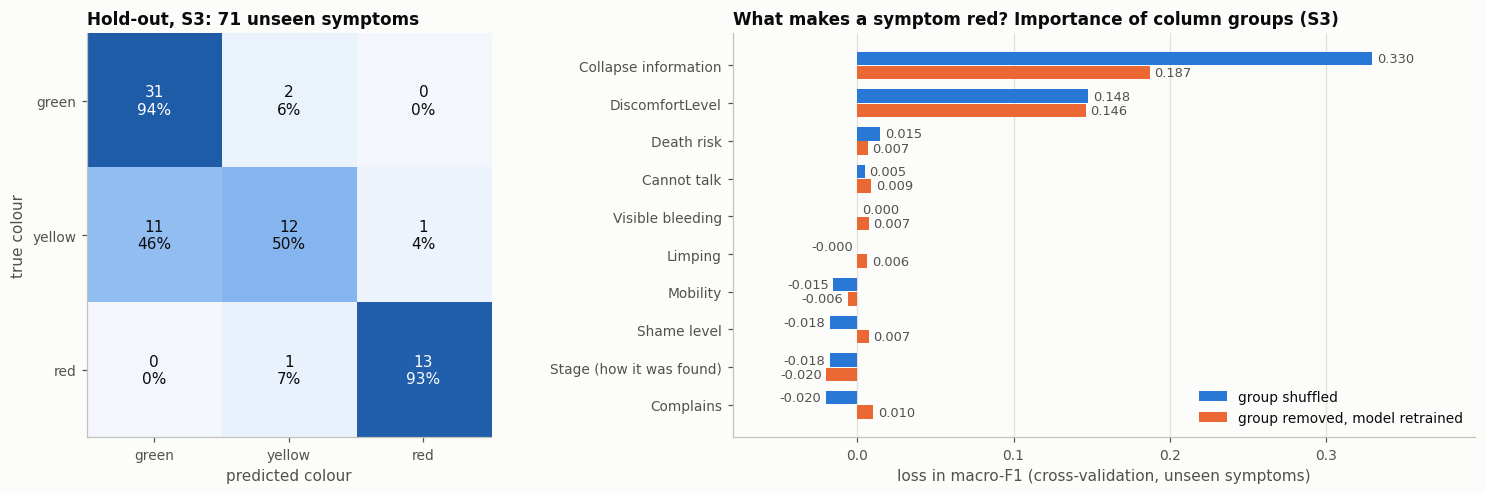

A readable tree (depth 3) on S3, as a plausibility check:
|--- collapse_symptom_None <= 0.50
|   |--- class: 2
|--- collapse_symptom_None >  0.50
|   |--- discomfort_Low <= 0.50
|   |   |--- discomfort_None <= 0.50
|   |   |   |--- class: 1
|   |   |--- discomfort_None >  0.50
|   |   |   |--- class: 0
|   |--- discomfort_Low >  0.50
|   |   |--- class: 0



In [18]:
def boot_ci(y, pred, n=1000, seed=SEED):
    rng = np.random.default_rng(seed); y, pred = np.asarray(y), np.asarray(pred); out = []
    for _ in range(n):
        ii = rng.integers(0, len(y), len(y)); out.append(level_metrics(y[ii], pred[ii]))
    B = pd.DataFrame(out); return B.quantile(0.025), B.quantile(0.975)

rows = [{"configuration": "Majority class", **level_metrics(A_test.y, np.full(len(A_test), A_dev.y.mode()[0]))},
        {"configuration": "Red-flag rule", **level_metrics(A_test.y, np.where(A_test.bedside_flags >= 1, 2, 0))}]
PRED_AT = {}
for fs in SETS:
    n_, c_ = SETS[fs]; p_ = make_pipe("Random forest", n_, c_).fit(A_dev[n_ + c_], A_dev.y); PRED_AT[fs] = p_.predict(A_test[n_ + c_])
    m_ = level_metrics(A_test.y, PRED_AT[fs]); lo, hi = boot_ci(A_test.y, PRED_AT[fs])
    rows.append({"configuration": f"Random forest, {fs}", **m_, "macro_f1 95% CI": f"[{lo.macro_f1:.2f}, {hi.macro_f1:.2f}]", "red_recall 95% CI": f"[{lo.red_recall:.2f}, {hi.red_recall:.2f}]"})
TA_TEST = pd.DataFrame(rows); display(TA_TEST.round(3).fillna(""))
print(f"Hold-out: {len(A_test)} unseen symptoms, {int((A_test.y == 2).sum())} of them red. The hold-out is small, so the intervals are wide; the cross-validation figures are the steadier estimate.")
print("Compare with the cross-validation table of §4.4: the same pattern is expected (bedside sets below the criteria, prognosis set above them, Hazard near-perfect).")

# what makes a symptom red? importance on the set where the model works (S3)
n3, c3 = SETS["S3 + prognosis"]
GROUPS_A = {"DiscomfortLevel": ["discomfort"], "Collapse information": ["has_collapse", "collapse_start", "collapse_end", "collapse_symptom"],
            "Death risk": ["has_death_risk", "death_start", "death_end"], "Mobility": ["mobility"], "Cannot talk": ["cannot_talk"], "Visible bleeding": ["bleeding"],
            "Limping": ["limp"], "Complains": ["complains"], "Shame level": ["shame"], "Stage (how it was found)": ["stage"]}
rng = np.random.default_rng(SEED); Xd, yd = A_dev[n3 + c3], A_dev.y.to_numpy(); perm = {k: [] for k in GROUPS_A}
for tr, va in StratifiedKFold(5, shuffle=True, random_state=SEED).split(Xd, yd):
    p_ = make_pipe("Random forest", n3, c3).fit(Xd.iloc[tr], yd[tr]); b_ = f1_score(yd[va], p_.predict(Xd.iloc[va]), average="macro")
    for k, cols in GROUPS_A.items():
        for _ in range(5):
            Xp = Xd.iloc[va].copy(); Xp[cols] = Xp[cols].to_numpy()[rng.permutation(len(Xp))]
            perm[k].append(b_ - f1_score(yd[va], p_.predict(Xp), average="macro"))
logo = {}
for k, cols in GROUPS_A.items():
    r_, _ = cv_symptom("Random forest", ([c for c in n3 if c not in cols], [c for c in c3 if c not in cols]), repeats=2); logo[k] = rf3.macro_f1 - r_["macro_f1"]
IMP_A = pd.DataFrame({"shuffled": {k: np.mean(v) for k, v in perm.items()}, "removed and retrained": logo}).sort_values("shuffled")
display(IMP_A.sort_values("shuffled", ascending=False).round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.3]})
cm = confusion_matrix(A_test.y, PRED_AT["S3 + prognosis"], labels=[0, 1, 2]); ax[0].imshow(cm / cm.sum(1, keepdims=True), cmap=SEQ, vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        sh = cm[i, j] / cm[i].sum(); ax[0].text(j, i, f"{cm[i, j]}\n{sh:.0%}", ha="center", va="center", fontsize=10, color="#ffffff" if sh > 0.6 else INK)
ax[0].set_xticks(range(3)); ax[0].set_yticks(range(3)); ax[0].set_xticklabels(["green", "yellow", "red"]); ax[0].set_yticklabels(["green", "yellow", "red"])
ax[0].set_xlabel("predicted colour"); ax[0].set_ylabel("true colour"); ax[0].set_title(f"Hold-out, S3: {len(A_test)} unseen symptoms"); ax[0].grid(False)
yb = np.arange(len(IMP_A)); hb = 0.36
b1 = ax[1].barh(yb + hb / 2 + 0.01, IMP_A["shuffled"], hb, color=BLUE, label="group shuffled"); b2 = ax[1].barh(yb - hb / 2 - 0.01, IMP_A["removed and retrained"], hb, color=ORANGE, label="group removed, model retrained")
bar_labels(ax[1], b1, "{:.3f}", horizontal=True); bar_labels(ax[1], b2, "{:.3f}", horizontal=True)
ax[1].set_yticks(yb); ax[1].set_yticklabels(IMP_A.index); ax[1].set_xlabel("loss in macro-F1 (cross-validation, unseen symptoms)"); ax[1].legend(loc="lower right")
ax[1].set_title("What makes a symptom red? Importance of column groups (S3)"); ax[1].grid(axis="y", visible=False)
ax[1].set_xlim(min(0, IMP_A.min().min()) - 0.06, IMP_A.max().max() * 1.2)
show("fig_symptom_holdout_importance")

tree = Pipeline([("pre", make_pre(n3, c3)), ("m", DecisionTreeClassifier(max_depth=3, min_samples_leaf=8, class_weight="balanced", random_state=SEED))]).fit(Xd, yd)
print("A readable tree (depth 3) on S3, as a plausibility check:")
print(export_text(tree.named_steps["m"], feature_names=[f.split("__")[1] for f in tree.named_steps["pre"].get_feature_names_out()], max_depth=3))

## 4.6 Symptoms without any bedside description
257 symptoms (888 rows) have no simulator attributes: nothing about them can be observed in this archive. For a new symptom of that kind the model sees only the stage at which it was found.

In [19]:
B0 = SYM[~SYM.has_attr].reset_index(drop=True)
n2_, c2_ = SETS["S2 + discomfort"]
pred_B0 = make_pipe("Random forest", n2_, c2_).fit(A[n2_ + c2_], A.y).predict(B0[n2_ + c2_])
NOATTR = pd.DataFrame({"forest (sees only the stage)": level_metrics(B0.y, pred_B0), "default: always yellow": level_metrics(B0.y, np.ones(len(B0), int)),
                       "default: always red": level_metrics(B0.y, np.full(len(B0), 2))}).T
display(NOATTR.round(3))
print("Colours of these symptoms:", {LEVEL_NAME[k]: int(v) for k, v in B0.y.value_counts().sort_index().items()}, "| found by:", B0.stage.map({0: "interview", 1: "bedside exam", 2: "instrument/lab"}).value_counts().to_dict())
print("Reading: without observations no model can do better than a default. A symptom that is neither in the table nor describable should count as red until it is examined.")

SYMPTOM_SUMMARY = {"symptoms": int(len(SYM)), "symptoms_with_attributes": int(len(A)), "symptoms_always_same_colour": STRUCT["symptoms that always have the same colour"],
                   "eligible_model_meets_criteria": bool(A_FEASIBLE),
                   "cv_best_per_feature_set": VERDICT_A.reset_index()[["features", "model", "macro_f1", "red_recall", "under_triage", "over_triage"]].round(4).to_dict(orient="records"),
                   "holdout": TA_TEST.round(4).fillna("").to_dict(orient="records"), "regression_vs_classification": REG_TAB.round(4).fillna("").to_dict(orient="records"),
                   "importance_S3": IMP_A.round(4).reset_index().to_dict(orient="records"), "lookup": LOOKUP.reset_index().to_dict(orient="records"),
                   "no_attribute_symptoms": NOATTR.round(4).reset_index().to_dict(orient="records")}

,macro_f1,red_recall,under_triage,over_triage,accuracy
forest (sees only the stage),0.303,0.91,0.070,0.533,0.397
default: always yellow,0.174,0.00,0.346,0.300,0.354
default: always red,0.171,1.00,0.000,0.654,0.346


Colours of these symptoms: {'green': 77, 'yellow': 91, 'red': 89} | found by: {'instrument/lab': 201, 'interview': 36, 'bedside exam': 20}
Reading: without observations no model can do better than a default. A symptom that is neither in the table nor describable should count as red until it is examined.


# 5. Modelling, part B – the patient at the triage desk

## 5.1 From the archive to patients
The course notebook generates a patient by drawing a diagnosis and up to three symptoms that the interview reveals. We keep that and add the part that makes triage hard: **what the patient has but has not revealed.**

1. **Diagnosis:** draw a random archive row and take its diagnosis (course generator).
2. **Symptoms the patient has:** each symptom of the diagnosis is present with the archive's percentage (share of cases, §2.5). At least one symptom is present.
3. **Known at the desk:** up to three of the present symptoms that an interview reveals (course generator). The nurse also sees the patient: cannot talk, cannot move, visible bleeding, limping, discomfort.
4. **True colour:** the most urgent symptom the patient has, revealed or not. This is the MAX rule of the workbook's traffic-light sheet, applied to all present symptoms.
5. **Deterioration deadline:** the shortest "hours until a collapse can start" among the present symptoms, if any (used in §6).

Assumptions to keep in mind: diagnoses are drawn as in the course generator (not by real incidence), and the archive describes hospital cases, so the share of critical patients is far higher than in a real ED.

In [20]:
DX_LIST = np.array(sorted(df.Diagnosis.unique())); DX_ID = {d: i for i, d in enumerate(DX_LIST)}; N_DX = len(DX_LIST)
SYM_ID = {s: i for i, s in enumerate(SYM.Symptom)}; SYM_LVL = SYM.y.to_numpy()
ROW_DX, ROW_SYM = df.Diagnosis.map(DX_ID).to_numpy(), df.Symptom.map(SYM_ID).to_numpy()
Yr, OCC, STAGE = df.y.to_numpy(), df.occ.to_numpy(), df.stage.to_numpy()
DX_ROWS = [np.where(ROW_DX == i)[0] for i in range(N_DX)]
DX_DEPT = df.groupby(ROW_DX).avdeling.agg(lambda s: s.mode().iloc[0]).to_numpy(); DX_COMMON = df.groupby(ROW_DX).common.agg(lambda s: s.mode().iloc[0]).to_numpy()
OBS_ROW = {"obs_cannot_talk": df.cannot_talk.to_numpy(), "obs_immobile": df.immobile.to_numpy(), "obs_bleeding": df.bleeding.to_numpy(),
           "obs_limp": df.limp.to_numpy(), "obs_discomfort": df.discomfort_ord.to_numpy()}
DEADLINE_ROW = np.where(df.has_collapse.to_numpy() == 1, df.collapse_start.to_numpy() * 60.0, np.nan)      # minutes until a collapse can start

def generate_patients(n, dx_ids, seed, cap=3):
    rng = np.random.default_rng(seed); pool = np.where(np.isin(ROW_DX, dx_ids))[0]; out = []
    for pid in range(n):
        d = ROW_DX[pool[rng.integers(len(pool))]]; idx = DX_ROWS[d]
        pres = idx[rng.random(len(idx)) < OCC[idx]]
        if len(pres) == 0: pres = idx[[int(np.argmax(OCC[idx]))]]
        desk = pres[STAGE[pres] == 0]
        rev = rng.choice(desk, size=min(cap, len(desk)), replace=False) if len(desk) else np.array([], dtype=int)
        rec = {"pid": pid, "dx": int(d), "present": pres, "revealed": rev, "rev_sym": np.unique(ROW_SYM[rev]), "n_present": len(pres), "n_revealed": len(rev),
               "true_level": int(Yr[pres].max()), "revealed_level": int(Yr[rev].max()) if len(rev) else -1}
        for k, v in OBS_ROW.items(): rec[k] = np.nanmax(v[pres]) if np.isfinite(v[pres]).any() else np.nan
        dl = DEADLINE_ROW[pres]; rec["deadline_min"] = np.nanmin(dl) if np.isfinite(dl).any() else np.nan
        out.append(rec)
    P = pd.DataFrame(out)
    P["Diagnosis"] = DX_LIST[P.dx]; P["department"] = DX_DEPT[P.dx]; P["common"] = DX_COMMON[P.dx]
    P["red_flags"] = (P[["obs_cannot_talk", "obs_immobile"]].fillna(0).sum(axis=1) + (P.obs_bleeding.fillna(0) > 0)).astype(int)
    return P

demo = generate_patients(8, np.arange(N_DX), SEED)
demo_show = demo.assign(revealed_at_desk=demo.revealed.map(lambda r: ", ".join(df.Symptom.to_numpy()[r])), true_colour=demo.true_level.map(LEVEL_NAME),
                        colour_of_revealed=demo.revealed_level.map({-1: "nothing revealed", **LEVEL_NAME}))
print("Eight random patients:"); display(demo_show[["Diagnosis", "department", "n_present", "revealed_at_desk", "colour_of_revealed", "true_colour"]])

big = generate_patients(5000, np.arange(N_DX), SEED + 1)
MIX = pd.DataFrame({"true colour (all present symptoms)": big.true_level.map(LEVEL_NAME).value_counts(normalize=True),
                    "colour of what is revealed at the desk": big.revealed_level.clip(lower=0).map(LEVEL_NAME).value_counts(normalize=True)}).reindex(["green", "yellow", "red"])
display((MIX * 100).round(1))
HIDDEN_RED = float(((big.true_level == 2) & (big.revealed_level < 2)).sum() / (big.true_level == 2).sum())
print(f"Over 5,000 random patients: {(big.true_level == 2).mean():.1%} are truly red; {HIDDEN_RED:.1%} of the red patients show no red symptom at the desk (hidden critical finding).")
print(f"Symptoms present per patient: mean {big.n_present.mean():.1f}; revealed at the desk: {big.n_revealed.value_counts().sort_index().to_dict()}")

Eight random patients:


,Diagnosis,department,n_present,revealed_at_desk,colour_of_revealed,true_colour
0,Chickenpox,emergency,4,"Fever, Headache, Loss of Appetite",yellow,yellow
1,Ulcerative Colitis,general medicine,7,"Fever, Diarrhea, Fatigue",yellow,yellow
2,Severe Frostbite On Legs,trauma,11,"Severe Leg Pain, Blisters, Swelling",yellow,red
3,Simple Fracture of Clavicle,ortho,9,"Collarbone Injury, Dizziness, Pain",yellow,yellow
4,Spiral Fracture of Tibia,ortho,8,"Tenderness, Pain, Limited Leg Motion",yellow,yellow
5,West Nile Fever,infectious,8,"High Fever, Fatigue, Chills",red,red
6,Hay Fever,emergency,6,"Nasal Congestion, Fatigue, Sneezing",green,green
7,Nasal Fracture,ortho,4,"Tenderness, Nasal Deformity, Pain",yellow,yellow


,true colour (all present symptoms),colour of what is revealed at the desk
green,2.9,19.0
yellow,41.7,65.9
red,55.4,15.1


Over 5,000 random patients: 55.4% are truly red; 72.7% of the red patients show no red symptom at the desk (hidden critical finding).
Symptoms present per patient: mean 8.4; revealed at the desk: {0: 157, 1: 103, 2: 242, 3: 4498}


## 5.2 The rules we compare

| Rule | What it uses | Source |
|---|---|---|
| **Keyword rule** | fixed points for words in the revealed symptom names ("chest pain" 10, any "pain" 5, "fever" 3; red from 15, yellow from 10) | the priority score in HospitalSim (`Patient.calculate_priority`, MIT licence), re-implemented here so that it runs without the package |
| **Lookup rule** | colour of the most urgent revealed symptom | traffic-light sheet of the course workbook |
| **Lookup + red flags** | lookup, and red if the patient cannot talk, cannot move or bleeds | nurse checklist |
| **Risk model** | all of the above plus what the archive says about the diagnoses that fit the revealed symptoms | this project |
| **Everybody red** | nothing | reference: meets C1 with maximal over-triage |

**Inputs of the risk model.** (a) *Lookup:* colour and count of the revealed symptoms. (b) *Knowledge base:* for the diagnoses that contain the revealed symptoms, how likely is a red symptom? (c) *Bedside observation:* cannot talk, cannot move, bleeding, limping. (d) *Discomfort*, tested separately. All knowledge-base values are computed **without the patient's own diagnosis**, so the model is always judged on a diagnosis it has not seen.

In [21]:
# --- keyword rule of HospitalSim (hospital_sim/main.py, Patient.calculate_priority; MIT licence) ---
HSIM_EMERGENCY = ["chest pain", "shortness of breath", "severe bleeding", "unconscious", "seizure", "stroke symptoms", "trauma"]
def hsim_score(symptom_names):
    score = 0
    for s in symptom_names:
        s = s.lower()
        if any(e in s for e in HSIM_EMERGENCY): score += 10
        elif "pain" in s: score += 5
        elif "fever" in s: score += 3
    return min(score, 20)
hsim_level = lambda sc: 2 if sc >= 15 else (1 if sc >= 10 else 0)       # its queue treats >= 15 as emergency and >= 10 as urgent

# --- knowledge base: per symptom the diagnoses that contain it; per diagnosis the chance of a red symptom ---
_sd = df.assign(s=ROW_SYM, d=ROW_DX).groupby(["s", "d"]).occ.max().reset_index()
SYM_DX = {int(s): (g.d.to_numpy(), g.occ.to_numpy()) for s, g in _sd.groupby("s")}
DX_W = np.array([len(r) for r in DX_ROWS], dtype=float)
noisy_or = lambda p: 1 - np.prod(1 - p)
DX_RED = np.array([noisy_or(OCC[r][Yr[r] == 2]) for r in DX_ROWS])                         # P(at least one red symptom present)
DX_RED_HID = np.array([noisy_or(OCC[r][(Yr[r] == 2) & (STAGE[r] > 0)]) for r in DX_ROWS])    # ... red symptom that an interview does not reveal

def kb_features(P, kb_mask):
    # kb_mask[d] = True if diagnosis d may be used. The patient's own diagnosis is always left out.
    rows = []
    for syms, own in zip(P.rev_sym.to_numpy(), P.dx.to_numpy()):
        lv, r_all, r_hid, nd, cand = [], [], [], [], None
        for s in syms:
            dxs, occ = SYM_DX[int(s)]; m = kb_mask[dxs] & (dxs != own)
            if not m.any(): continue                                   # symptom unknown to the knowledge base
            dxs, occ = dxs[m], occ[m]; w = DX_W[dxs] * occ
            lv.append(SYM_LVL[int(s)]); r_all.append(np.average(DX_RED[dxs], weights=w)); r_hid.append(np.average(DX_RED_HID[dxs], weights=w)); nd.append(len(dxs))
            cur = dict(zip(dxs.tolist(), occ.tolist()))
            cand = cur if cand is None else {d: cand[d] * cur[d] for d in cand.keys() & cur.keys()}
        f = {"lk_level": max(lv) if lv else -1, "n_revealed": len(syms), "n_unknown": len(syms) - len(lv), "n_rev_yellow": sum(l == 1 for l in lv), "n_rev_red": sum(l == 2 for l in lv),
             "kb_risk_mean": np.mean(r_all) if lv else np.nan, "kb_risk_max": max(r_all) if lv else np.nan, "kb_hidden_mean": np.mean(r_hid) if lv else np.nan,
             "kb_hidden_max": max(r_hid) if lv else np.nan, "kb_n_dx_min": min(nd) if lv else np.nan, "cand_n": len(cand) if cand else 0, "cand_risk": np.nan, "cand_hidden": np.nan}
        if cand:
            cd = np.fromiter(cand.keys(), dtype=int); cw = DX_W[cd] * np.fromiter(cand.values(), dtype=float)
            f["cand_risk"] = np.average(DX_RED[cd], weights=cw); f["cand_hidden"] = np.average(DX_RED_HID[cd], weights=cw)
        rows.append(f)
    F = pd.DataFrame(rows, index=P.index)
    for c in ["obs_cannot_talk", "obs_immobile", "obs_bleeding", "obs_limp", "obs_discomfort"]: F[c] = P[c].to_numpy()
    return F

F_LOOKUP = ["lk_level", "n_revealed", "n_unknown", "n_rev_yellow", "n_rev_red"]
F_KB = ["kb_risk_mean", "kb_risk_max", "kb_hidden_mean", "kb_hidden_max", "kb_n_dx_min", "cand_n", "cand_risk", "cand_hidden"]
F_OBS = ["obs_cannot_talk", "obs_immobile", "obs_bleeding", "obs_limp"]; F_DISC = ["obs_discomfort"]
PSETS = {"P1 lookup inputs": F_LOOKUP, "P2 + knowledge base": F_LOOKUP + F_KB, "P3 + bedside observation": F_LOOKUP + F_KB + F_OBS, "P4 + discomfort": F_LOOKUP + F_KB + F_OBS + F_DISC}

def rule_levels(P, F):
    names = df.Symptom.to_numpy()
    kw = np.array([hsim_level(hsim_score(names[r])) for r in P.revealed])
    lk = np.maximum(F.lk_level.to_numpy(), 0)
    return {"Keyword rule (HospitalSim)": kw, "Lookup rule": lk, "Lookup + red flags": np.where(P.red_flags.to_numpy() >= 1, 2, lk), "Everybody red": np.full(len(P), 2)}
print("Knowledge base ready:", N_DX, "diagnoses,", len(SYM_DX), "symptoms.")

Knowledge base ready: 349 diagnoses, 608 symptoms.


## 5.3 Test design
* **Hold-out:** 20 % of the **diagnoses** (70) are set aside; 3,000 patients are generated from them and used once (§5.5).
* **Development:** 6,000 patients from the other 279 diagnoses, 5-fold cross-validation **grouped by diagnosis**. In each fold the knowledge base contains only the training diagnoses of that fold.
* **Target:** the true colour (three classes). **Decision:** the colour with the lowest expected cost (§5.5); the patient never gets a colour below the lookup colour.
* **Metrics:** recall of red, over-triage and under-triage (share of all patients), AUC for "red or not", macro-F1. Intervals: bootstrap over diagnoses.

In [22]:
dx_tab = pd.DataFrame({"dx": np.arange(N_DX), "dept": DX_DEPT})
dev_i, test_i = next(StratifiedKFold(5, shuffle=True, random_state=SEED).split(dx_tab, dx_tab.dept))
DEV_DX, TEST_DX = dx_tab.dx.to_numpy()[dev_i], dx_tab.dx.to_numpy()[test_i]
P_dev, P_test = generate_patients(6000, DEV_DX, SEED + 10), generate_patients(3000, TEST_DX, SEED + 11)
KB_DEV = np.zeros(N_DX, bool); KB_DEV[DEV_DX] = True
print(f"Diagnoses: {len(DEV_DX)} development, {len(TEST_DX)} hold-out | patients: {len(P_dev)} development, {len(P_test)} hold-out")
print("True colours (dev):", (P_dev.true_level.map(LEVEL_NAME).value_counts(normalize=True).reindex(["green", "yellow", "red"]) * 100).round(1).to_dict(),
      "| (hold-out):", (P_test.true_level.map(LEVEL_NAME).value_counts(normalize=True).reindex(["green", "yellow", "red"]) * 100).round(1).to_dict())

# fold-wise knowledge-base features for the development patients
t0 = time.time(); y_dev = P_dev.true_level.to_numpy(); g_dev = P_dev.dx.to_numpy()
FOLDS = list(StratifiedGroupKFold(5, shuffle=True, random_state=SEED).split(P_dev, y_dev, g_dev)); F_FOLD = []
for tr, va in FOLDS:
    kb = KB_DEV.copy(); kb[np.unique(g_dev[va])] = False
    F_FOLD.append(kb_features(P_dev, kb))
print(f"Features computed for 5 folds ({time.time() - t0:.0f} s). Symptoms unknown to the fold's knowledge base: {np.mean([F.n_unknown.sum() / F.n_revealed.sum() for F in F_FOLD]):.1%} of revealed symptoms.")

def p_model(name, rf=None):
    if name == "Logistic regression": return Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("sc", StandardScaler()), ("m", LogisticRegression(max_iter=3000, class_weight="balanced"))])
    if name == "Decision tree":       return Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)), ("m", DecisionTreeClassifier(max_depth=6, min_samples_leaf=30, class_weight="balanced", random_state=SEED))])
    if name == "Random forest":       return Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                                                       ("m", RandomForestClassifier(**{**dict(n_estimators=200, min_samples_leaf=10, max_features="sqrt"), **(rf or {})}, class_weight="balanced", n_jobs=-1, random_state=SEED))])
    if name == "Gradient boosting":   return HistGradientBoostingClassifier(max_depth=4, learning_rate=0.08, max_iter=120, class_weight="balanced", random_state=SEED)
    raise ValueError(name)

def cv_patient(name, cols, rf=None):
    proba = np.zeros((len(P_dev), 3))
    for (tr, va), F in zip(FOLDS, F_FOLD):
        proba[va] = p_model(name, rf).fit(F.iloc[tr][cols], y_dev[tr]).predict_proba(F.iloc[va][cols])
    return proba
LK_DEV = np.zeros(len(P_dev), int)
for (tr, va), F in zip(FOLDS, F_FOLD): LK_DEV[va] = np.maximum(F.lk_level.to_numpy()[va], 0)

Diagnoses: 279 development, 70 hold-out | patients: 6000 development, 3000 hold-out
True colours (dev): {'green': 2.6, 'yellow': 43.3, 'red': 54.2} | (hold-out): {'green': 4.3, 'yellow': 45.8, 'red': 49.9}
Features computed for 5 folds (2 s). Symptoms unknown to the fold's knowledge base: 1.4% of revealed symptoms.


## 5.4 Build and compare models
**Decision rule.** With probabilities *p* for green, yellow and red and a cost matrix where over-triage costs 1 per level and under-triage costs *w′* per level, the chosen colour is the one with the lowest expected cost: `colour = argmin_j Σ_k p_k · C[k, j]`. The patient never gets a colour below the lookup colour. A larger *w′* moves decisions towards red.

**How models are compared.** By the patient-level criterion of §1.5: the **over-triage needed to reach a red recall of 0.90** (lower is better), plus the AUC for "red or not".

In [23]:
ASSUMED_W = 10
def cost_matrix(w):
    C = np.zeros((3, 3))
    for k in range(3):
        for j in range(3): C[k, j] = w * (k - j) if j < k else (j - k)
    return C
def decide(proba, w, floor=None):
    d = (proba @ cost_matrix(w)).argmin(1)
    return d if floor is None else np.maximum(d, floor)
realised_cost = lambda y, pred, w=ASSUMED_W: float(cost_matrix(w)[np.asarray(y), np.asarray(pred)].mean())
W_GRID = [1, 1.5, 2, 2.5, 3, 3.5, 4, 5, 6, 8, 10, 15, 25]

def frontier(y, proba, floor):
    rows = []
    for w in W_GRID:
        d_ = decide(proba, w, floor); m_ = level_metrics(y, d_); rows.append({"w'": w, **m_, **{f"cost@w={a}": realised_cost(y, d_, a) for a in (2, 5, 10, 25)}})
    return pd.DataFrame(rows)
def at_c1(fr, target=0.90):
    ok = fr[fr.red_recall >= target]
    return ok.sort_values(["over_triage", "w'"]).iloc[0] if len(ok) else fr.sort_values("red_recall", ascending=False).iloc[0]

t0 = time.time(); RES_P, OOF_P = [], {}
def run_p(name, fs, rf=None, label=None):
    pr = cv_patient(name, PSETS[fs], rf); label = label or name; c1 = at_c1(frontier(y_dev, pr, LK_DEV)); am = level_metrics(y_dev, np.maximum(pr.argmax(1), LK_DEV))
    RES_P.append({"model": label, "inputs": fs, "auc_red": roc_auc_score(y_dev == 2, pr[:, 2]), "w' at C1": c1["w'"], "red_recall at C1": c1.red_recall, "over_triage at C1": c1.over_triage,
                  "red_recall (most likely colour)": am["red_recall"], "over_triage (most likely colour)": am["over_triage"]})
    OOF_P[(label, fs)] = pr
for m_ in ["Logistic regression", "Decision tree", "Random forest", "Gradient boosting"]: run_p(m_, "P3 + bedside observation")
for fs in ["P1 lookup inputs", "P2 + knowledge base", "P4 + discomfort"]: run_p("Random forest", fs)
for leaf, mf in [(3, "sqrt"), (30, "sqrt"), (10, 0.5)]:                 # revised forest settings
    run_p("Random forest", "P3 + bedside observation", rf=dict(min_samples_leaf=leaf, max_features=mf), label=f"Random forest (leaf {leaf}, features {mf})")
TP = pd.DataFrame(RES_P)
KW_DEV = np.array([hsim_level(hsim_score(df.Symptom.to_numpy()[r])) for r in P_dev.revealed])
base_dev = pd.DataFrame({k: level_metrics(y_dev, v) for k, v in {"Keyword rule (HospitalSim)": KW_DEV, "Lookup rule": LK_DEV,
                         "Lookup + red flags": np.where(P_dev.red_flags.to_numpy() >= 1, 2, LK_DEV), "Everybody red": np.full(len(P_dev), 2)}.items()}).T
print("Models, cross-validation by diagnosis:"); display(TP.sort_values("over_triage at C1").round(3).reset_index(drop=True))
print("Rules without a model, same patients:"); display(base_dev[["red_recall", "over_triage", "under_triage", "accuracy"]].round(3))
print(f"({time.time() - t0:.0f} s)")

Models, cross-validation by diagnosis:


,model,inputs,auc_red,w' at C1,red_recall at C1,over_triage at C1,red_recall (most likely colour),over_triage (most likely colour)
0,Random forest,P4 + discomfort,0.833,2.5,0.904,0.237,0.715,0.110
1,"Random forest (leaf 30, features sqrt)",P3 + bedside observation,0.826,3.0,0.911,0.247,0.702,0.108
2,Gradient boosting,P3 + bedside observation,0.823,4.0,0.913,0.254,0.690,0.130
3,Random forest,P2 + knowledge base,0.799,2.5,0.904,0.254,0.707,0.133
4,"Random forest (leaf 3, features sqrt)",P3 + bedside observation,0.830,2.5,0.901,0.256,0.734,0.133
5,Logistic regression,P3 + bedside observation,0.817,4.0,0.906,0.259,0.618,0.084
6,Random forest,P3 + bedside observation,0.830,3.0,0.925,0.262,0.710,0.111
7,Decision tree,P3 + bedside observation,0.792,5.0,0.914,0.272,0.588,0.101
8,"Random forest (leaf 10, features 0.5)",P3 + bedside observation,0.817,3.5,0.929,0.282,0.708,0.128
9,Random forest,P1 lookup inputs,0.685,8.0,0.946,0.416,0.360,0.027


Rules without a model, same patients:


,red_recall,over_triage,under_triage,accuracy
Keyword rule (HospitalSim),0.023,0.003,0.929,0.068
Lookup rule,0.279,0.000,0.483,0.517
Lookup + red flags,0.462,0.026,0.380,0.594
Everybody red,1.000,0.458,0.000,0.542


(17 s)


**Selection.** Lowest over-triage at C1 among models whose inputs are available at the desk (P3 or P4). A model without discomfort is preferred unless discomfort lowers the over-triage at C1 by more than one percentage point.

In [24]:
elig = TP[TP.inputs.isin(["P3 + bedside observation", "P4 + discomfort"])].sort_values(["over_triage at C1", "auc_red"], ascending=[True, False])
no_disc = elig[elig.inputs == "P3 + bedside observation"].iloc[0]; with_disc = elig[elig.inputs == "P4 + discomfort"].iloc[0]
BEST_P = with_disc if with_disc["over_triage at C1"] < no_disc["over_triage at C1"] - 0.01 else no_disc
P_LABEL, P_FS = BEST_P.model, BEST_P.inputs; P_COLS = PSETS[P_FS]
_m = re.match(r"Random forest \(leaf (\d+), features (.+)\)", P_LABEL)
P_NAME, P_RF = ("Random forest", dict(min_samples_leaf=int(_m.group(1)), max_features=(_m.group(2) if _m.group(2) == "sqrt" else float(_m.group(2))))) if _m else (P_LABEL, None)
proba_dev = OOF_P[(P_LABEL, P_FS)]
print(f"SELECTED: {P_LABEL} on '{P_FS}' | AUC (red or not) {BEST_P.auc_red:.3f} | over-triage at C1 {BEST_P['over_triage at C1']:.3f}")
print(f"Over-triage at C1 without discomfort {no_disc['over_triage at C1']:.3f}, with discomfort {with_disc['over_triage at C1']:.3f} -> discomfort {'is used' if P_FS == 'P4 + discomfort' else 'is not needed'}.")

ABL = TP[TP.model == "Random forest"].set_index("inputs").reindex(list(PSETS))[["auc_red", "over_triage at C1", "red_recall (most likely colour)"]]
print("\nWhat each input group adds (same forest, growing inputs):"); display(ABL.round(3))

FRONT_DEV = frontier(y_dev, proba_dev, LK_DEV)
W_C1 = float(at_c1(FRONT_DEV)["w'"]); W_COST = float(FRONT_DEV.sort_values([f"cost@w={ASSUMED_W}", "w'"]).iloc[0]["w'"])
display(FRONT_DEV[["w'", "red_recall", "over_triage", "under_triage", "accuracy", "cost@w=2", "cost@w=10"]].round(3))
print(f"Operating point 1 (C1 with the least over-triage): w' = {W_C1:g}.   Operating point 2 (lowest cost if a missed level costs {ASSUMED_W} times an extra level): w' = {W_COST:g}.")

SELECTED: Random forest (leaf 30, features sqrt) on 'P3 + bedside observation' | AUC (red or not) 0.826 | over-triage at C1 0.247
Over-triage at C1 without discomfort 0.247, with discomfort 0.237 -> discomfort is not needed.

What each input group adds (same forest, growing inputs):


,auc_red,over_triage at C1,red_recall (most likely colour)
inputs,,,
P1 lookup inputs,0.685,0.416,0.360
P2 + knowledge base,0.799,0.254,0.707
P3 + bedside observation,0.830,0.262,0.710
P4 + discomfort,0.833,0.237,0.715


,w',red_recall,over_triage,under_triage,accuracy,cost@w=2,cost@w=10
0,1.0,0.647,0.095,0.250,0.655,0.666,2.947
1,1.5,0.800,0.175,0.135,0.690,0.473,1.661
2,2.0,0.853,0.204,0.094,0.702,0.414,1.246
3,2.5,0.879,0.226,0.075,0.699,0.395,1.056
4,3.0,0.911,0.247,0.054,0.699,0.372,0.855
5,3.5,0.925,0.267,0.044,0.689,0.372,0.764
6,4.0,0.935,0.285,0.036,0.680,0.372,0.688
7,5.0,0.953,0.311,0.026,0.663,0.374,0.582
8,6.0,0.962,0.331,0.021,0.648,0.385,0.553
9,8.0,0.975,0.353,0.013,0.634,0.394,0.500


Operating point 1 (C1 with the least over-triage): w' = 3.   Operating point 2 (lowest cost if a missed level costs 10 times an extra level): w' = 15.


## 5.5 Hold-out test (used once)
The model is trained on all development patients, with a knowledge base of the 279 development diagnoses. The 3,000 hold-out patients come from 70 diagnoses that neither the model nor the knowledge base has seen.

,red_recall,red_recall 95% CI,over_triage,over_triage 95% CI,under_triage,accuracy,macro_f1,cost@w=10
rule,,,,,,,,
Keyword rule (HospitalSim),0.023,"[0.00, 0.05]",0.000,"[0.00, 0.00]",0.933,0.066,0.060,13.540
Lookup rule,0.229,"[0.12, 0.34]",0.000,"[0.00, 0.00]",0.485,0.515,0.447,5.550
Lookup + red flags,0.449,"[0.31, 0.60]",0.013,"[0.00, 0.04]",0.372,0.615,0.550,4.276
Everybody red,1.000,"[1.00, 1.00]",0.501,"[0.38, 0.62]",0.000,0.499,0.222,0.544
"Risk model, most likely colour",0.692,"[0.60, 0.79]",0.136,"[0.08, 0.19]",0.240,0.624,0.556,3.081
"Risk model, cost-sensitive w'=3 (C1)",0.882,"[0.82, 0.94]",0.303,"[0.22, 0.39]",0.073,0.624,0.499,1.105
"Risk model, cost-sensitive w'=15 (cost, w=10)",0.984,"[0.96, 1.00]",0.442,"[0.33, 0.55]",0.008,0.550,0.304,0.551


AUC for 'red or not' on the hold-out: risk model 0.799 | knowledge-base risk alone (no model) 0.731
C1 at w' = 3: red recall 0.882 [0.82, 0.94] -> NOT met on the point estimate; over-triage 0.303 against 0.501 for 'everybody red' (39% less).
Macro-F1 is low for every rule because only about 3-4 % of the patients are truly green; red recall and over-triage are the measures that matter here.


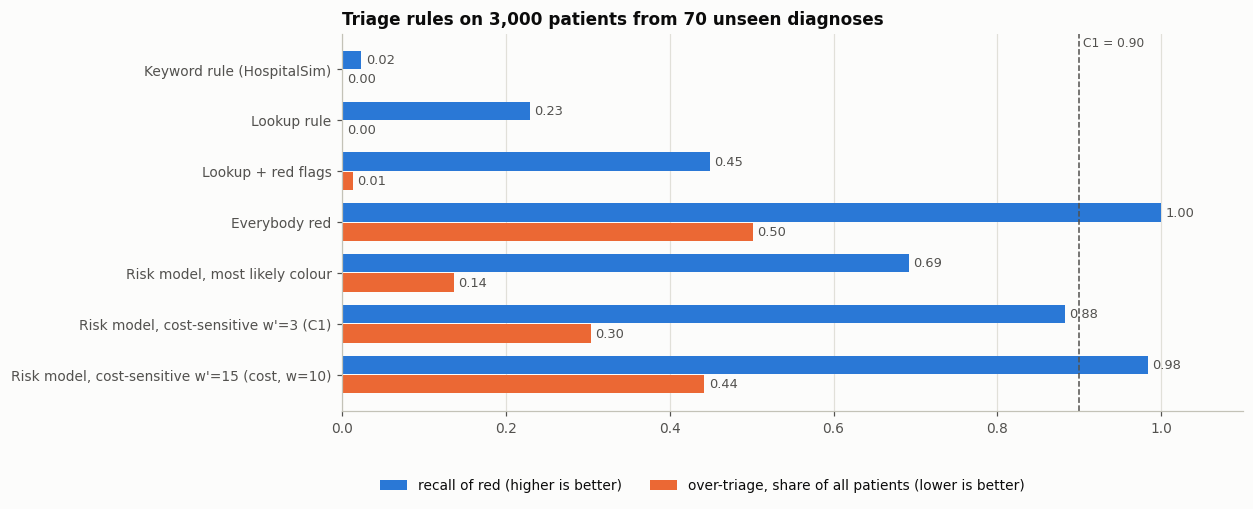

In [25]:
F_dev_full, F_test = kb_features(P_dev, KB_DEV), kb_features(P_test, KB_DEV)
model_P = p_model(P_NAME, P_RF).fit(F_dev_full[P_COLS], y_dev)
proba_test = model_P.predict_proba(F_test[P_COLS]); y_test = P_test.true_level.to_numpy(); LK_TEST = np.maximum(F_test.lk_level.to_numpy(), 0)
RULES_T = rule_levels(P_test, F_test)
M_ARG, M_C1, M_COST = "Risk model, most likely colour", f"Risk model, cost-sensitive w'={W_C1:g} (C1)", f"Risk model, cost-sensitive w'={W_COST:g} (cost, w={ASSUMED_W})"
RULES_T[M_ARG] = np.maximum(proba_test.argmax(1), LK_TEST); RULES_T[M_C1] = decide(proba_test, W_C1, LK_TEST)
if W_COST != W_C1: RULES_T[M_COST] = decide(proba_test, W_COST, LK_TEST)
for k, v in RULES_T.items(): P_test["a_" + k] = v

def cluster_boot(P, col, n=400, seed=SEED):
    y, pr, g = P.true_level.to_numpy(), P[col].to_numpy(), P.dx.to_numpy()
    idx = pd.Series(np.arange(len(P))).groupby(g).apply(lambda s: s.to_numpy()); keys = idx.index.to_numpy(); rng = np.random.default_rng(seed); out = []
    for _ in range(n):
        ii = np.concatenate([idx[k] for k in rng.choice(keys, len(keys), replace=True)]); out.append(level_metrics(y[ii], pr[ii]))
    B = pd.DataFrame(out); return B.quantile(0.025), B.quantile(0.975)

rows = []
for k, v in RULES_T.items():
    m_ = level_metrics(y_test, v); lo, hi = cluster_boot(P_test, "a_" + k)
    rows.append({"rule": k, "red_recall": m_["red_recall"], "red_recall 95% CI": f"[{lo.red_recall:.2f}, {hi.red_recall:.2f}]", "over_triage": m_["over_triage"],
                 "over_triage 95% CI": f"[{lo.over_triage:.2f}, {hi.over_triage:.2f}]", "under_triage": m_["under_triage"], "accuracy": m_["accuracy"], "macro_f1": m_["macro_f1"],
                 f"cost@w={ASSUMED_W}": realised_cost(y_test, v)})
T_TEST = pd.DataFrame(rows).set_index("rule"); display(T_TEST.round(3))
AUC_TEST = roc_auc_score(y_test == 2, proba_test[:, 2])
kb_only = F_test.cand_hidden.fillna(F_test.kb_hidden_mean).fillna(0.5).to_numpy()
AUC_KB = roc_auc_score(y_test == 2, kb_only)
print(f"AUC for 'red or not' on the hold-out: risk model {AUC_TEST:.3f} | knowledge-base risk alone (no model) {AUC_KB:.3f}")
c1r = T_TEST.loc[M_C1]; allred = T_TEST.loc["Everybody red"]
print(f"C1 at w' = {W_C1:g}: red recall {c1r.red_recall:.3f} {c1r['red_recall 95% CI']} -> {'met' if c1r.red_recall >= .9 else 'NOT met'} on the point estimate; "
      f"over-triage {c1r.over_triage:.3f} against {allred.over_triage:.3f} for 'everybody red' ({1 - c1r.over_triage / allred.over_triage:.0%} less).")
print("Macro-F1 is low for every rule because only about 3-4 % of the patients are truly green; red recall and over-triage are the measures that matter here.")

fig, ax = plt.subplots(figsize=(11.5, 4.8)); names = list(T_TEST.index); yb = np.arange(len(names))[::-1]; hb = 0.36
b1 = ax.barh(yb + hb / 2 + 0.01, T_TEST.red_recall, hb, color=BLUE, label="recall of red (higher is better)")
b2 = ax.barh(yb - hb / 2 - 0.01, T_TEST.over_triage, hb, color=ORANGE, label="over-triage, share of all patients (lower is better)")
bar_labels(ax, b1, horizontal=True); bar_labels(ax, b2, horizontal=True)
ax.axvline(0.90, color=INK2, ls="--", lw=1); ax.text(0.905, len(names) - 0.55, "C1 = 0.90", fontsize=8, color=INK2)
ax.set_yticks(yb); ax.set_yticklabels(names); ax.set_xlim(0, 1.1); ax.legend(loc="lower center", bbox_to_anchor=(0.4, -0.25), ncol=2); ax.grid(axis="y", visible=False)
ax.set_title(f"Triage rules on {len(P_test):,} patients from {len(TEST_DX)} unseen diagnoses")
show("fig_patient_rules")

### The cost-sensitivity frontier (decision level)
Each point is one decision weight *w′*. Moving right buys recall of red with over-triage. The second panel shows the realised cost for four assumed cost ratios *w*: the best weight depends on what a missed red patient is taken to cost. §6.4 adds waiting times and congestion to this picture.

,w',red_recall,over_triage,under_triage,cost@w=2,cost@w=5,cost@w=10,cost@w=25
0,1.0,0.668,0.133,0.234,0.661,1.453,2.773,6.733
1,1.5,0.783,0.211,0.143,0.540,1.031,1.849,4.304
2,2.0,0.822,0.241,0.112,0.492,0.866,1.489,3.359
3,2.5,0.862,0.281,0.085,0.471,0.752,1.220,2.625
4,3.0,0.882,0.303,0.073,0.467,0.706,1.105,2.300
5,3.5,0.896,0.321,0.062,0.462,0.663,0.998,2.003
6,4.0,0.907,0.332,0.054,0.457,0.631,0.921,1.791
7,5.0,0.928,0.356,0.041,0.456,0.585,0.800,1.445
8,6.0,0.949,0.377,0.027,0.451,0.534,0.672,1.087
9,8.0,0.963,0.401,0.019,0.461,0.517,0.611,0.891


Best decision weight w' for each assumed cost ratio w (chosen on development data): {2: 4.0, 5: 10.0, 10: 15.0, 25: 25.0}
Reading: about half of these patients are truly red. The best weight rises quickly with the assumed cost ratio, and at high ratios the cheapest rule approaches 'everybody red'. The cost ratio is therefore a decision for clinicians, not a technical detail.


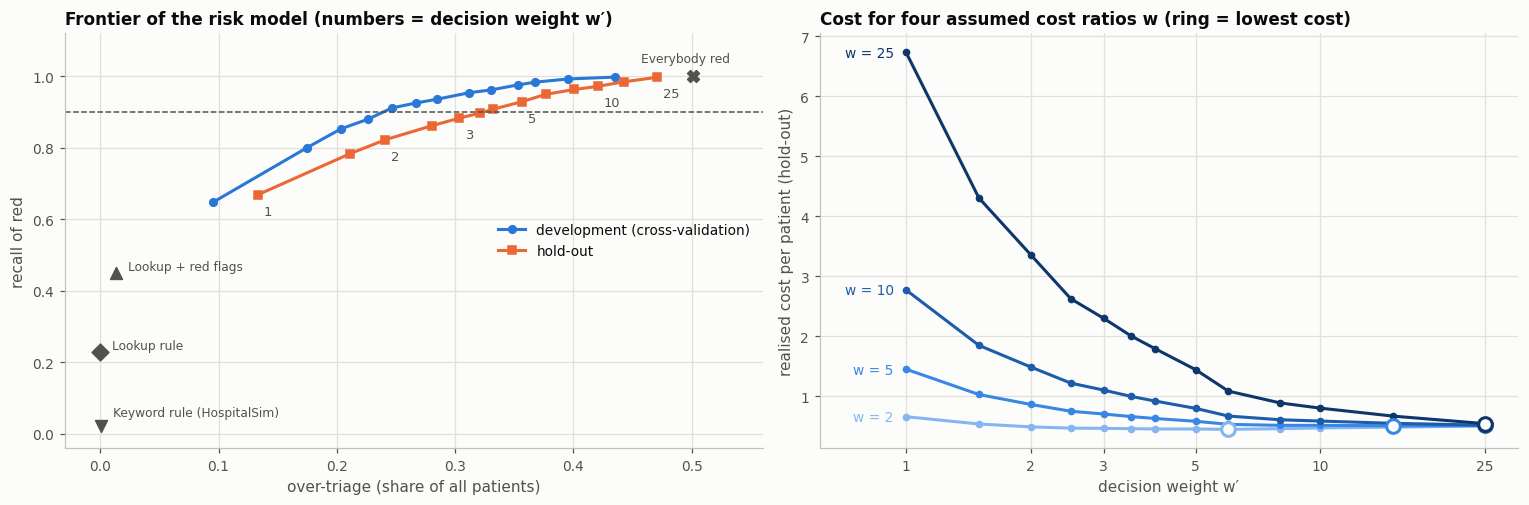

In [26]:
FRONT_TEST = frontier(y_test, proba_test, LK_TEST)
display(FRONT_TEST[["w'", "red_recall", "over_triage", "under_triage", "cost@w=2", "cost@w=5", "cost@w=10", "cost@w=25"]].round(3))
BEST_W_BY_RATIO = {a: float(FRONT_DEV.sort_values([f"cost@w={a}", "w'"]).iloc[0]["w'"]) for a in (2, 5, 10, 25)}
print("Best decision weight w' for each assumed cost ratio w (chosen on development data):", BEST_W_BY_RATIO)
print("Reading: about half of these patients are truly red. The best weight rises quickly with the assumed cost ratio, and at high ratios the cheapest rule approaches 'everybody red'. The cost ratio is therefore a decision for clinicians, not a technical detail.")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.7))
for fr, who, col, mk in [(FRONT_DEV, "development (cross-validation)", BLUE, "o"), (FRONT_TEST, "hold-out", ORANGE, "s")]:
    ax[0].plot(fr.over_triage, fr.red_recall, marker=mk, ms=5, color=col, label=who)
for _, r_ in FRONT_TEST.iterrows():                      # decision weights are written on the hold-out curve only
    if r_["w'"] in (1, 2, 3, 5, 10, 25): ax[0].annotate(f"{r_['w' + chr(39)]:g}", (r_.over_triage, r_.red_recall), textcoords="offset points", xytext=(4, -13), fontsize=8.5, color=INK2)
for nm, mk, off in [("Lookup rule", "D", (8, 2)), ("Lookup + red flags", "^", (8, 2)), ("Everybody red", "X", (-34, 9)), ("Keyword rule (HospitalSim)", "v", (8, 6))]:
    ax[0].scatter(T_TEST.loc[nm, "over_triage"], T_TEST.loc[nm, "red_recall"], marker=mk, s=60, color=INK2, zorder=3)
    ax[0].annotate(nm, (T_TEST.loc[nm, "over_triage"], T_TEST.loc[nm, "red_recall"]), textcoords="offset points", xytext=off, fontsize=8, color=INK2)
ax[0].axhline(0.90, color=INK2, ls="--", lw=1); ax[0].set_xlabel("over-triage (share of all patients)"); ax[0].set_ylabel("recall of red"); ax[0].set_ylim(-0.04, 1.12)
ax[0].set_title("Frontier of the risk model (numbers = decision weight w′)"); ax[0].legend(loc="center right"); ax[0].set_xlim(-0.03, 0.56)
for a, col in zip((2, 5, 10, 25), ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]):
    cst = FRONT_TEST[f"cost@w={a}"]; ax[1].plot(FRONT_TEST["w'"], cst, marker="o", ms=4, color=col)
    ax[1].annotate(f"w = {a}", (FRONT_TEST["w'"].iloc[0], cst.iloc[0]), textcoords="offset points", xytext=(-8, -3), ha="right", fontsize=9, color=col)
    j = int(cst.to_numpy().argmin()); ax[1].scatter(FRONT_TEST["w'"].iloc[j], cst.iloc[j], s=80, facecolor=SURFACE, edgecolor=col, linewidth=2, zorder=3)
ax[1].set_xscale("log"); ax[1].set_xticks([1, 2, 3, 5, 10, 25]); ax[1].set_xticklabels(["1", "2", "3", "5", "10", "25"]); ax[1].set_xlim(0.62, 30); ax[1].minorticks_off()
ax[1].set_xlabel("decision weight w′"); ax[1].set_ylabel("realised cost per patient (hold-out)"); ax[1].set_title("Cost for four assumed cost ratios w (ring = lowest cost)")
show("fig_patient_frontier")

## 5.6 Six Sigma – defects, DPMO and sigma level
**Define:** a defect is a truly red patient who is not triaged red. **Measure:** defects per million opportunities (DPMO), one opportunity per red patient; sigma level = Φ⁻¹(1 − DPMO/10⁶) + 1.5. **Analyse:** §5.7. **Improve:** the decision weight. **Control:** monitoring (§8).

In [27]:
def sigma_from(defects, opps):
    dpmo = 1e6 * defects / max(opps, 1)
    return dpmo, (min(6.0, norm.ppf(1 - dpmo / 1e6) + 1.5) if dpmo > 0 else 6.0)
def six_sigma(P, col, n_boot=400, seed=SEED):
    red = P.true_level.to_numpy() == 2; miss = red & (P[col].to_numpy() < 2); d, s = sigma_from(miss.sum(), red.sum())
    idx = pd.Series(np.arange(len(P))).groupby(P.dx.to_numpy()).apply(lambda x: x.to_numpy()); keys = idx.index.to_numpy(); rng = np.random.default_rng(seed); sg = []
    for _ in range(n_boot):
        ii = np.concatenate([idx[k] for k in rng.choice(keys, len(keys), replace=True)])
        if red[ii].sum() > 0: sg.append(sigma_from(miss[ii].sum(), red[ii].sum())[1])
    lo, hi = np.percentile(sg, [2.5, 97.5])
    return {"red patients (opportunities)": int(red.sum()), "defects (red not triaged red)": int(miss.sum()), "DPMO": int(round(d)), "sigma level": round(s, 2), "sigma 95% CI": f"[{lo:.2f}, {hi:.2f}]",
            "over-triaged patients per 100": round(100 * float((P[col].to_numpy() > P.true_level.to_numpy()).mean()), 1)}
SS = pd.DataFrame({k: six_sigma(P_test, "a_" + k) for k in RULES_T if k != "Everybody red"}).T
display(SS)
print("The sigma level describes this simulated patient sample, not a hospital. It is used here to compare rules on one scale.")

,red patients (opportunities),defects (red not triaged red),DPMO,sigma level,sigma 95% CI,over-triaged patients per 100
Keyword rule (HospitalSim),1496,1461,976604,-0.49,"[-1.15, -0.11]",0.0
Lookup rule,1496,1153,770722,0.76,"[0.32, 1.10]",0.0
Lookup + red flags,1496,825,551471,1.37,"[1.01, 1.76]",1.3
"Risk model, most likely colour",1496,461,308155,2.0,"[1.76, 2.31]",13.6
"Risk model, cost-sensitive w'=3 (C1)",1496,176,117647,2.69,"[2.40, 3.07]",30.3
"Risk model, cost-sensitive w'=15 (cost, w=10)",1496,24,16043,3.64,"[3.26, 4.38]",44.2


The sigma level describes this simulated patient sample, not a hospital. It is used here to compare rules on one scale.


## 5.7 Where does it fail? Subgroup analysis
The archive has **no age, sex or language** of patients, so those subgroups cannot be analysed. We use the subgroups the data allow: department (diagnosis family), how common the diagnosis is, how many symptoms were revealed, whether the patient can talk (communication), whether a red flag is visible, and whether any bedside description exists (missing information). Rule: risk model at operating point 1. Small groups are marked by their size.

,subgroup,value,patients,share red,red recall,over-triage,lookup red recall
0,department,cardiology,221,0.882,0.933,0.077,0.000
1,department,emergency,184,0.000,NaN,0.293,NaN
2,department,general medicine,471,0.312,0.769,0.442,0.163
3,department,infectious,708,0.616,0.876,0.353,0.177
4,department,internal medicine,351,0.436,0.876,0.362,0.118
5,department,neurology,248,0.730,0.707,0.089,0.232
6,department,ortho,453,0.267,1.000,0.333,0.562
7,department,trauma,364,0.723,0.989,0.223,0.433
8,how common,Common,1968,0.471,0.855,0.303,0.195
9,how common,Rare,109,1.000,1.000,0.000,0.716


Lowest red recall among subgroups with at least 100 patients:


,subgroup,value,patients,share red,red recall,over-triage
5,department,neurology,248,0.730,0.707,0.089
2,department,general medicine,471,0.312,0.769,0.442
12,revealed symptoms,2,102,0.373,0.816,0.353


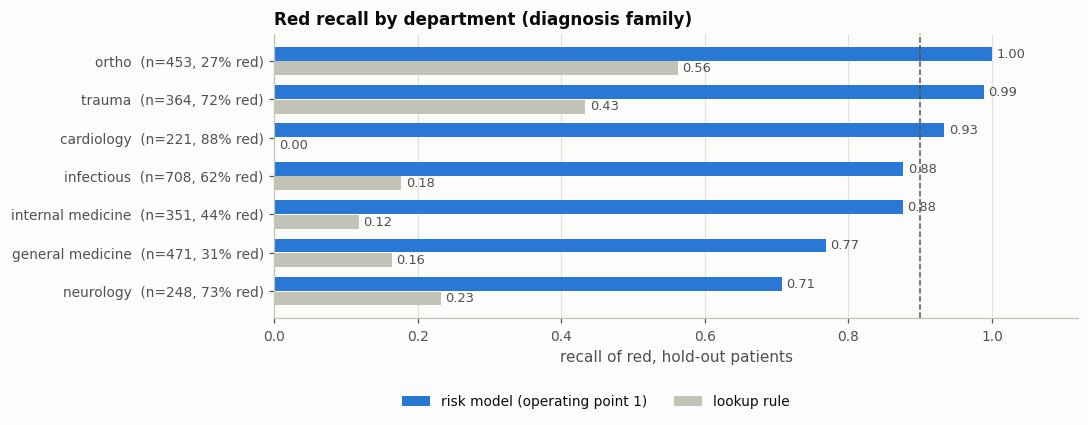

In [28]:
def subgroup(P, key, col, label=None):
    out = []
    for k, g in P.groupby(key, dropna=False):
        t, a = g.true_level.to_numpy(), g[col].to_numpy(); red = t == 2
        out.append({"subgroup": label or key, "value": k, "patients": len(g), "share red": red.mean(), "red recall": (a[red] == 2).mean() if red.any() else np.nan,
                    "over-triage": (a > t).mean(), "lookup red recall": (g["a_Lookup rule"].to_numpy()[red] == 2).mean() if red.any() else np.nan})
    return pd.DataFrame(out)
PT = P_test.copy()
PT["revealed symptoms"] = PT.n_revealed.map(lambda n: "0-1" if n <= 1 else str(n))
PT["can talk"] = np.where(PT.obs_cannot_talk == 1, "cannot talk", "can talk")
PT["visible red flag"] = np.where(PT.red_flags >= 1, "yes", "no")
PT["bedside description"] = np.where(PT.obs_discomfort.isna(), "none (no attributes)", "available")
PT["unknown symptom at desk"] = np.where(F_test.n_unknown.to_numpy() > 0, "yes", "no")
SUB = pd.concat([subgroup(PT, "department", "a_" + M_C1), subgroup(PT, "common", "a_" + M_C1, "how common"), subgroup(PT, "revealed symptoms", "a_" + M_C1),
                 subgroup(PT, "can talk", "a_" + M_C1, "communication"), subgroup(PT, "visible red flag", "a_" + M_C1), subgroup(PT, "bedside description", "a_" + M_C1, "missing information"),
                 subgroup(PT, "unknown symptom at desk", "a_" + M_C1)], ignore_index=True)
display(SUB.round(3))
worst = SUB[(SUB.patients >= 100) & SUB["red recall"].notna()].sort_values("red recall").head(3)
print("Lowest red recall among subgroups with at least 100 patients:"); display(worst[["subgroup", "value", "patients", "share red", "red recall", "over-triage"]].round(3))

d_ = SUB[SUB.subgroup == "department"].sort_values("red recall"); d_ = d_[d_["red recall"].notna()]
fig, ax = plt.subplots(figsize=(10, 4.2)); yb = np.arange(len(d_)); hb = 0.36
b1 = ax.barh(yb + hb / 2 + 0.01, d_["red recall"], hb, color=BLUE, label="risk model (operating point 1)"); b2 = ax.barh(yb - hb / 2 - 0.01, d_["lookup red recall"], hb, color=AXIS, label="lookup rule")
bar_labels(ax, b1, horizontal=True); bar_labels(ax, b2, horizontal=True)
ax.set_yticks(yb); ax.set_yticklabels([f"{v}  (n={n}, {s:.0%} red)" for v, n, s in zip(d_.value, d_.patients, d_["share red"])]); ax.axvline(0.90, color=INK2, ls="--", lw=1)
ax.set_xlim(0, 1.12); ax.set_xlabel("recall of red, hold-out patients"); ax.set_title("Red recall by department (diagnosis family)"); ax.legend(loc="lower center", bbox_to_anchor=(0.4, -0.36), ncol=2); ax.grid(axis="y", visible=False)
show("fig_patient_subgroups")

### Symptom type as a subgroup
The first professor asked for a fairness and subgroup analysis by **symptom type**. In this archive the type of a symptom that matters for triage is **how it is found** (§3.3): by interview at the desk (stage 0), by a bedside examination (stage 1), or by an instrument, laboratory test or scan (stage 2). For every hold-out patient we take the symptoms that set the true colour (the present symptoms with that colour) and ask how the easiest of them is found. A red patient whose only red symptom needs a laboratory test is the hard case: nothing at the desk shows it. We also split by whether a symptom with the true colour has been revealed at the desk. Rule: risk model at operating point 1, as in the table above.

,subgroup,value,patients,red patients,share red,red recall,lookup red recall,over-triage
0,symptom type,bedside examination,405,392,0.968,0.847,0.000,0.000
1,symptom type,instrument / lab / imaging,604,536,0.887,0.851,0.000,0.048
2,symptom type,interview,1991,568,0.285,0.937,0.604,0.442
3,deciding symptom,not revealed at desk,1458,1153,0.791,0.847,0.000,0.043
4,deciding symptom,revealed at desk,1542,343,0.222,1.000,1.000,0.550


Red patients only - share found as red, by how their red symptom is found:


,red patients,risk model,lookup rule,keyword rule
symptom type,,,,
bedside examination,392,0.847,0.000,0.005
instrument / lab / imaging,536,0.851,0.000,0.045
interview,568,0.937,0.604,0.016


Lowest red recall among the symptom types with at least 30 red patients: bedside examination: 0.85 (392 red patients).
Reading: if the red symptom needs an instrument or a laboratory test, the desk sees nothing of it, so the model can only use what the patient reveals and the archive knows about the diagnoses that fit. Small groups are marked by their size.


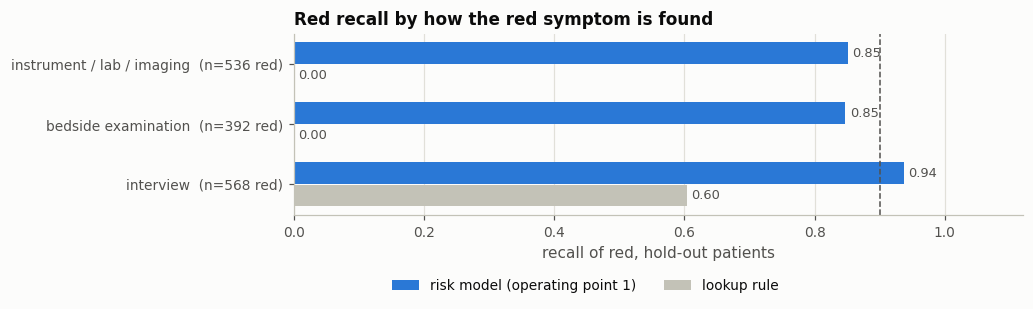

In [29]:
# Symptom type = how the symptom that sets the true colour is found: 0 interview, 1 bedside examination, 2 instrument / laboratory / imaging.
STAGE_NAME = {0: "interview", 1: "bedside examination", 2: "instrument / lab / imaging"}
def deciding_stage(present, level):
    s = present[Yr[present] == level]                 # present symptoms that have the colour of the patient
    return int(STAGE[s].min())                        # the easiest way to find one of them
PT["symptom type"] = [STAGE_NAME[deciding_stage(p, l)] for p, l in zip(PT.present, PT.true_level)]
PT["deciding symptom at desk"] = np.where(PT.revealed_level == PT.true_level, "revealed at desk", "not revealed at desk")

SYM_TYPE = pd.concat([subgroup(PT, "symptom type", "a_" + M_C1, "symptom type"), subgroup(PT, "deciding symptom at desk", "a_" + M_C1, "deciding symptom")], ignore_index=True)
SYM_TYPE["red patients"] = (SYM_TYPE.patients * SYM_TYPE["share red"]).round().astype(int)
SYM_TYPE["share of all patients"] = SYM_TYPE.patients / len(PT)
display(SYM_TYPE[["subgroup", "value", "patients", "red patients", "share red", "red recall", "lookup red recall", "over-triage"]].round(3))

# the same for red patients only, split by symptom type: how often does each rule find the red patient?
RT = PT[PT.true_level == 2]
by_type = pd.DataFrame([{"symptom type": n_, "red patients": len(g), "risk model": (g["a_" + M_C1] == 2).mean(), "lookup rule": (g["a_Lookup rule"] == 2).mean(),
                         "keyword rule": (g["a_Keyword rule (HospitalSim)"] == 2).mean()} for n_, g in RT.groupby("symptom type")]).set_index("symptom type")
print("Red patients only - share found as red, by how their red symptom is found:"); display(by_type.round(3))
lo = SYM_TYPE[(SYM_TYPE.subgroup == "symptom type") & (SYM_TYPE["red patients"] >= 30)].sort_values("red recall").iloc[0]
print(f"Lowest red recall among the symptom types with at least 30 red patients: {lo['value']}: {lo['red recall']:.2f} ({int(lo['red patients'])} red patients).")
print("Reading: if the red symptom needs an instrument or a laboratory test, the desk sees nothing of it, so the model can only use what the patient reveals and the archive knows about the diagnoses that fit. Small groups are marked by their size.")

fig, ax = plt.subplots(figsize=(9.5, 3.4)); d_ = by_type.reindex(list(STAGE_NAME.values())).dropna(); yb = np.arange(len(d_)); hb = 0.36
b1 = ax.barh(yb + hb / 2 + 0.01, d_["risk model"], hb, color=BLUE, label="risk model (operating point 1)"); b2 = ax.barh(yb - hb / 2 - 0.01, d_["lookup rule"], hb, color=AXIS, label="lookup rule")
bar_labels(ax, b1, horizontal=True); bar_labels(ax, b2, horizontal=True)
ax.set_yticks(yb); ax.set_yticklabels([f"{v}  (n={int(n)} red)" for v, n in zip(d_.index, d_["red patients"])]); ax.axvline(0.90, color=INK2, ls="--", lw=1)
ax.set_xlim(0, 1.12); ax.set_xlabel("recall of red, hold-out patients"); ax.set_title("Red recall by how the red symptom is found"); ax.legend(loc="lower center", bbox_to_anchor=(0.4, -0.5), ncol=2); ax.grid(axis="y", visible=False)
show("fig_patient_symptom_type")
SYM_TYPE_RECORDS = SYM_TYPE.round(3).to_dict(orient="records")        # added to the summary file in the staffing cell below


## 5.8 Reliability – other splits, a known diagnosis, calibration, generator settings

In [30]:
t0 = time.time()
# (a) five different sets of unseen diagnoses
rows = []
for k, (dv, te) in enumerate(StratifiedKFold(5, shuffle=True, random_state=SEED + 5).split(dx_tab, dx_tab.dept), 1):
    kb = np.zeros(N_DX, bool); kb[dv] = True
    Ptr, Pte = generate_patients(3000, dv, SEED + 100 + k), generate_patients(1500, te, SEED + 200 + k)
    Ftr, Fte = kb_features(Ptr, kb), kb_features(Pte, kb)
    pr = p_model(P_NAME, P_RF).fit(Ftr[P_COLS], Ptr.true_level).predict_proba(Fte[P_COLS]); lk = np.maximum(Fte.lk_level.to_numpy(), 0); yt = Pte.true_level.to_numpy()
    m_ = level_metrics(yt, decide(pr, W_C1, lk)); rows.append({"split": k, "auc_red": roc_auc_score(yt == 2, pr[:, 2]), "red_recall": m_["red_recall"], "over_triage": m_["over_triage"],
                                                               "lookup red_recall": level_metrics(yt, lk)["red_recall"], "share red": (yt == 2).mean()})
SPLITS = pd.DataFrame(rows); display(SPLITS.round(3))
print(f"Five splits, operating point 1 (w' = {W_C1:g}): red recall {SPLITS.red_recall.mean():.3f} ± {SPLITS.red_recall.std():.3f} (min {SPLITS.red_recall.min():.3f}), "
      f"over-triage {SPLITS.over_triage.mean():.3f} ± {SPLITS.over_triage.std():.3f}, AUC {SPLITS.auc_red.mean():.3f} ± {SPLITS.auc_red.std():.3f}. C1 holds in {int((SPLITS.red_recall >= .9).sum())} of 5 splits.")

# (b) if the diagnosis IS in the knowledge base (new patients of known diseases)
ALL_KB = np.ones(N_DX, bool)
def kb_features_known(P):          # same features, but the patient's own diagnosis stays in the knowledge base
    Q = P.copy(); Q["dx"] = -1; F = kb_features(Q, ALL_KB); return F
Pc_tr, Pc_te = generate_patients(4000, np.arange(N_DX), SEED + 300), generate_patients(2000, np.arange(N_DX), SEED + 301)
Fc_tr, Fc_te = kb_features_known(Pc_tr), kb_features_known(Pc_te)
prc = p_model(P_NAME, P_RF).fit(Fc_tr[P_COLS], Pc_tr.true_level).predict_proba(Fc_te[P_COLS]); lkc = np.maximum(Fc_te.lk_level.to_numpy(), 0); ytc = Pc_te.true_level.to_numpy()
frc = at_c1(frontier(ytc, prc, lkc))
KNOWN = {"auc_red": float(roc_auc_score(ytc == 2, prc[:, 2])), "over_triage at red recall 0.90": float(frc.over_triage), "red_recall": float(frc.red_recall)}
print(f"\nKnown diagnoses (disease is in the archive): AUC {KNOWN['auc_red']:.3f}; over-triage at red recall 0.90: {KNOWN['over_triage at red recall 0.90']:.3f} "
      f"(unseen diagnoses: AUC {AUC_TEST:.3f}, over-triage {T_TEST.loc[M_C1, 'over_triage']:.3f}).")

# (c) calibration of P(red) on the hold-out
bins = pd.cut(proba_test[:, 2], [0, .2, .4, .6, .8, 1.0], include_lowest=True)
CAL = pd.DataFrame({"predicted": proba_test[:, 2], "observed": (y_test == 2).astype(float)}).groupby(bins, observed=True).agg(patients=("observed", "size"), mean_predicted=("predicted", "mean"), observed_share_red=("observed", "mean"))
BRIER = brier_score_loss(y_test == 2, proba_test[:, 2]); print("\nCalibration of the probability of red (hold-out):"); display(CAL.round(3)); print(f"Brier score {BRIER:.3f} (0.25 = no skill at a 50 % base rate).")

# (d) generator setting: how many symptoms does the interview reveal?
rows = []
for cap in (1, 2, 3, 99):
    Ptr, Pte = generate_patients(3000, DEV_DX, SEED + 400 + cap, cap=cap), generate_patients(2000, TEST_DX, SEED + 500 + cap, cap=cap)
    Ftr, Fte = kb_features(Ptr, KB_DEV), kb_features(Pte, KB_DEV)
    pr = p_model(P_NAME, P_RF).fit(Ftr[P_COLS], Ptr.true_level).predict_proba(Fte[P_COLS]); lk = np.maximum(Fte.lk_level.to_numpy(), 0); yt = Pte.true_level.to_numpy(); c1_ = at_c1(frontier(yt, pr, lk))
    rows.append({"symptoms revealed (max)": "all" if cap == 99 else cap, "lookup red_recall": level_metrics(yt, lk)["red_recall"], "model auc_red": roc_auc_score(yt == 2, pr[:, 2]), "model over_triage at red recall 0.90": c1_.over_triage})
CAPS = pd.DataFrame(rows); print("\nSensitivity to the number of revealed symptoms:"); display(CAPS.round(3)); print(f"({time.time() - t0:.0f} s)")

,split,auc_red,red_recall,over_triage,lookup red_recall,share red
0,1,0.841,0.908,0.209,0.287,0.625
1,2,0.826,0.947,0.257,0.318,0.582
2,3,0.820,0.873,0.266,0.342,0.481
3,4,0.825,0.914,0.291,0.299,0.486
4,5,0.732,0.869,0.349,0.198,0.483


Five splits, operating point 1 (w' = 3): red recall 0.902 ± 0.032 (min 0.869), over-triage 0.274 ± 0.051, AUC 0.809 ± 0.044. C1 holds in 3 of 5 splits.

Known diagnoses (disease is in the archive): AUC 0.949; over-triage at red recall 0.90: 0.090 (unseen diagnoses: AUC 0.799, over-triage 0.303).

Calibration of the probability of red (hold-out):


,patients,mean_predicted,observed_share_red
"(-0.001, 0.2]",726,0.101,0.191
"(0.2, 0.4]",521,0.298,0.355
"(0.4, 0.6]",861,0.506,0.506
"(0.6, 0.8]",489,0.670,0.681
"(0.8, 1.0]",403,0.952,1.000


Brier score 0.183 (0.25 = no skill at a 50 % base rate).

Sensitivity to the number of revealed symptoms:


,symptoms revealed (max),lookup red_recall,model auc_red,model over_triage at red recall 0.90
0,1,0.081,0.721,0.391
1,2,0.170,0.788,0.360
2,3,0.210,0.794,0.321
3,all,0.354,0.835,0.264


(6 s)


## 5.9 Side result – recommending a department
The feedback asked whether recommending the right department would also be valuable. The same knowledge base can do it without a new model: every diagnosis that fits the revealed symptoms votes for its department. Evaluated on the hold-out patients (their diagnosis is not in the knowledge base).

In [31]:
DEPTS = sorted(set(DX_DEPT)); DEPT_IDX = np.array([DEPTS.index(d) for d in DX_DEPT])
def dept_votes(P, kb_mask):
    V = np.zeros((len(P), len(DEPTS)))
    for i, (syms, own) in enumerate(zip(P.rev_sym.to_numpy(), P.dx.to_numpy())):
        cand, single = None, np.zeros(len(DEPTS))
        for s in syms:
            dxs, occ = SYM_DX[int(s)]; m = kb_mask[dxs] & (dxs != own)
            if not m.any(): continue
            dxs, occ = dxs[m], occ[m]; np.add.at(single, DEPT_IDX[dxs], DX_W[dxs] * occ / (DX_W[dxs] * occ).sum())
            cur = dict(zip(dxs.tolist(), occ.tolist())); cand = cur if cand is None else {d: cand[d] * cur[d] for d in cand.keys() & cur.keys()}
        if cand:
            cd = np.fromiter(cand.keys(), dtype=int); np.add.at(V[i], DEPT_IDX[cd], DX_W[cd] * np.fromiter(cand.values(), dtype=float))
        else: V[i] = single
    return V
V = dept_votes(P_test, KB_DEV); true_d = np.array([DEPTS.index(d) for d in P_test.department]); rank = np.argsort(-V, axis=1)
has_vote = V.sum(1) > 0; major = pd.Series(DX_DEPT[P_dev.dx]).mode()[0]
DEPT = {"top-1 accuracy": float((rank[:, 0] == true_d)[has_vote].mean()), "top-2 accuracy": float(((rank[:, 0] == true_d) | (rank[:, 1] == true_d))[has_vote].mean()),
        "patients with a recommendation": float(has_vote.mean()), "baseline: always the largest department": float((P_test.department == major).mean()), "departments": len(DEPTS)}
display(pd.Series(DEPT).round(3).to_frame("value"))
by_dept = pd.DataFrame({"department": P_test.department, "hit": rank[:, 0] == true_d})[has_vote].groupby("department").hit.agg(["mean", "size"]).rename(columns={"mean": "top-1 accuracy", "size": "patients"}).sort_values("top-1 accuracy")
display(by_dept.round(3))
print("Reading: for diagnoses the archive has not seen, the symptoms revealed at the desk point to the right department far more often than the baseline. This is a lookup with votes, not a trained model.")

PATIENT_SUMMARY = {"share_truly_red": float((big.true_level == 2).mean()), "share_red_hidden_at_desk": HIDDEN_RED, "selected_model": P_LABEL, "selected_inputs": P_FS,
                   "w_c1": W_C1, "w_cost": W_COST, "assumed_w": ASSUMED_W, "holdout_auc_red": float(AUC_TEST), "holdout_auc_kb_only": float(AUC_KB),
                   "holdout_rules": T_TEST.round(4).reset_index().to_dict(orient="records"), "cv_models": TP.round(4).to_dict(orient="records"), "input_groups": ABL.round(4).reset_index().to_dict(orient="records"),
                   "frontier_holdout": FRONT_TEST.round(4).to_dict(orient="records"), "best_w_by_cost_ratio": BEST_W_BY_RATIO, "six_sigma": SS.reset_index().rename(columns={"index": "rule"}).to_dict(orient="records"),
                   "subgroups": SUB.round(4).to_dict(orient="records"), "five_splits": SPLITS.round(4).to_dict(orient="records"), "known_diagnoses": KNOWN,
                   "calibration": CAL.round(4).reset_index().astype(str).to_dict(orient="records"), "brier": float(BRIER), "revealed_cap_sensitivity": CAPS.round(4).astype(str).to_dict(orient="records"), "department": DEPT}

,value
top-1 accuracy,0.559
top-2 accuracy,0.696
patients with a recommendation,0.984
baseline: always the largest department,0.236
departments,8.000


,top-1 accuracy,patients
department,,
internal medicine,0.170,312
cardiology,0.210,219
emergency,0.253,182
general medicine,0.544,469
neurology,0.567,245
ortho,0.611,453
infectious,0.762,707
trauma,0.810,364


Reading: for diagnoses the archive has not seen, the symptoms revealed at the desk point to the right department far more often than the baseline. This is a lookup with votes, not a trained model.


# 6. Evaluation, part C – the queue (Lean) and the objective function

## 6.1 The simulation model
The archive has no timestamps, so waiting times can only be studied in a **discrete-event simulation** built on stated assumptions (§1.3). Following the simulation framework of the course:

* **Conceptual model.** Patients arrive, get a colour from a triage rule, wait in one priority queue and are treated at one of *c* identical places.
* **Justification.** No flow data exist; a simulation is the only way to show what a triage rule does to waiting.
* **Hypothesis H.** For the mean wait of truly red patients: true colour (oracle) ≤ risk model ≤ lookup rule ≤ first come, first served, whatever the load.
* **Queue discipline.** Red before yellow before green, first come first served within a colour. One extra rule is tested: within a colour, the patient with the higher predicted risk goes first ("colour, then risk").
* **Measures.** Mean and 90th percentile wait of truly red patients, mean wait of the others, mean queue length (congestion), patients who deteriorate before treatment, share treated within the target time.
* **Independent variable.** The triage rule. Everything else is an assumption that §6.5 varies.

**Left out** (no data): transport, bed blocking, separate nurses and doctors, patients who leave, re-triage after examinations. Each would add parameters we cannot estimate.

The event loop is written directly with a heap (§1.2); *SimPy* would give the same results with more code around it.

In [32]:
SERVICE_MEAN = np.array([12.0, 25.0, 40.0])        # minutes by TRUE colour (green, yellow, red) - assumed
OVERHEAD = 0.0                                      # base case: a wrong colour only changes the order. §6.5 tests 5 and 10 extra minutes per over-triaged patient
TARGET = np.array([120.0, 60.0, 10.0])             # maximum acceptable wait by true colour - assumed
SERVERS, RHO, N_PAT, N_RUNS = 3, 0.90, 200, 40
BETA, GAMMA, DELTA = 1.0, 0.2, 1.0                  # weights of red wait, other wait, over-triage in J; alpha = w * delta

def simulate(arr, prio, svc, c=3):
    # non-pre-emptive priority queue with c servers; prio = None means first come, first served. Returns the wait of every patient.
    n = len(arr); free = [0.0] * c; heapq.heapify(free); heap = []; i = 0; started = 0; wait = np.zeros(n)
    while started < n:
        T = heapq.heappop(free)
        if not heap and i < n and arr[i] > T: T = arr[i]
        while i < n and arr[i] <= T:
            heapq.heappush(heap, (0.0 if prio is None else -float(prio[i]), arr[i], i)); i += 1
        _, _, j = heapq.heappop(heap); wait[j] = T - arr[j]; heapq.heappush(free, T + svc[j]); started += 1
    return wait

TRUE_T, DEADLINE_T = P_test.true_level.to_numpy(), P_test.deadline_min.to_numpy()
MEAN_SVC = SERVICE_MEAN[TRUE_T].mean()
KW_SCORE_T = np.array([hsim_score(df.Symptom.to_numpy()[r]) for r in P_test.revealed])
A_C1 = P_test["a_" + M_C1].to_numpy()
# priority values: higher = earlier. "by colour" uses the colour only; "colour, then risk" also orders patients of one colour by their probability of red.
POLICY = {"First come, first served": None, "Keyword rule (HospitalSim)": KW_SCORE_T, "Lookup rule": P_test["a_Lookup rule"].to_numpy(),
          "Risk model, by colour": A_C1, "Risk model, colour then risk": A_C1 + 0.99 * proba_test[:, 2], "True colour (oracle)": TRUE_T}
ASSIGNED = {"First come, first served": None, "Keyword rule (HospitalSim)": P_test["a_Keyword rule (HospitalSim)"].to_numpy(), "Lookup rule": POLICY["Lookup rule"],
            "Risk model, by colour": A_C1, "Risk model, colour then risk": A_C1, "True colour (oracle)": TRUE_T}
POL_COL = {"First come, first served": AXIS, "Keyword rule (HospitalSim)": MAGENTA, "Lookup rule": BLUE, "Risk model, by colour": ORANGE, "Risk model, colour then risk": AQUA, "True colour (oracle)": INK2}

def make_runs(n_runs=N_RUNS, n_pat=N_PAT, rho=RHO, servers=SERVERS, svc_level=1.0, dist="exp", seed=SEED + 11):
    # common random numbers: the same patients, arrivals and base treatment times for every rule
    rng = np.random.default_rng(seed); runs = []
    for _ in range(n_runs):
        ii = rng.integers(0, len(P_test), n_pat); nominal = SERVICE_MEAN[TRUE_T[ii]]
        base = rng.exponential(nominal * svc_level) if dist == "exp" else rng.gamma(4.0, nominal * svc_level / 4.0)        # gamma: same mean, less spread
        arr = np.cumsum(rng.exponential(MEAN_SVC / (servers * rho), n_pat))                                            # Poisson arrivals at the nominal load
        runs.append((ii, arr, base))
    return runs

def evaluate(prio, assigned, runs, servers=SERVERS, overhead=OVERHEAD):
    rec = []
    for ii, arr, base in runs:
        t = TRUE_T[ii]; a = None if assigned is None else assigned[ii]
        svc = base if a is None else base + overhead * ((a == 2) & (t < 2))
        w = simulate(arr, None if prio is None else prio[ii], svc, servers); red = t == 2; dl = DEADLINE_T[ii]
        rec.append({"red_wait": w[red].mean(), "red_p90": np.percentile(w[red], 90), "other_wait": w[~red].mean(), "all_wait": w.mean(), "queue_len": w.sum() / (arr[-1] - arr[0]),
                    "deteriorated_per_100": 100 * np.mean(w > np.where(np.isnan(dl), np.inf, dl)), "red_within_target": np.mean(w[red] <= TARGET[2]), "other_within_target": np.mean(w[~red] <= TARGET[t[~red]]),
                    "missed_red_per_100": 0.0 if a is None else 100 * np.mean(red & (a < 2)), "over_triage_per_100": 0.0 if a is None else 100 * np.mean(a > t)})
    return pd.DataFrame(rec)
def J_cost(m, w=ASSUMED_W): return w * DELTA * m["missed_red_per_100"] + BETA * m["red_wait"] + GAMMA * m["other_wait"] + DELTA * m["over_triage_per_100"]
print(f"Mean treatment time of the patient mix: {MEAN_SVC:.1f} min -> arrival rate at {RHO:.0%} utilisation with {SERVERS} places: one patient every {MEAN_SVC / (SERVERS * RHO):.1f} min.")

Mean treatment time of the patient mix: 31.9 min -> arrival rate at 90% utilisation with 3 places: one patient every 11.8 min.


## 6.2 Base case
Three treatment places, utilisation 0.90, 200 patients per run, 40 runs, the same patients and treatment times for every rule. The risk model is used at operating point 1 (the weight chosen for C1). "First come, first served" has no triage, so it has no missed red patients in the table; all its red patients simply wait their turn.

,"red wait, mean (min)",± 95% CI,"red wait, 90th pct","other wait, mean (min)","all, mean (min)",mean queue length,red within 10 min,deteriorated per 100,missed red per 100,over-triaged per 100,red wait vs first come,J (w=10)
"First come, first served",35.61,6.18,87.62,37.59,36.54,3.11,0.42,5.59,0.00,0.00,0.00,NaN
Keyword rule (HospitalSim),35.55,6.28,114.17,42.95,38.99,3.32,0.54,4.51,49.72,0.00,-0.00,541.39
Lookup rule,32.04,5.79,83.76,49.12,40.20,3.41,0.53,3.02,38.44,0.00,-0.10,426.24
"Risk model, by colour",28.42,5.24,67.61,55.85,41.61,3.54,0.52,2.75,6.02,29.54,-0.20,129.38
"Risk model, colour then risk",25.55,4.56,61.52,63.58,43.98,3.75,0.62,1.75,6.02,29.54,-0.28,128.06
True colour (oracle),14.91,1.78,42.92,79.58,46.06,3.92,0.58,1.68,0.00,0.00,-0.58,30.82


(0 s)
J for 'first come, first served' is not defined: without triage there is no triage decision to count as missed or over-triaged.


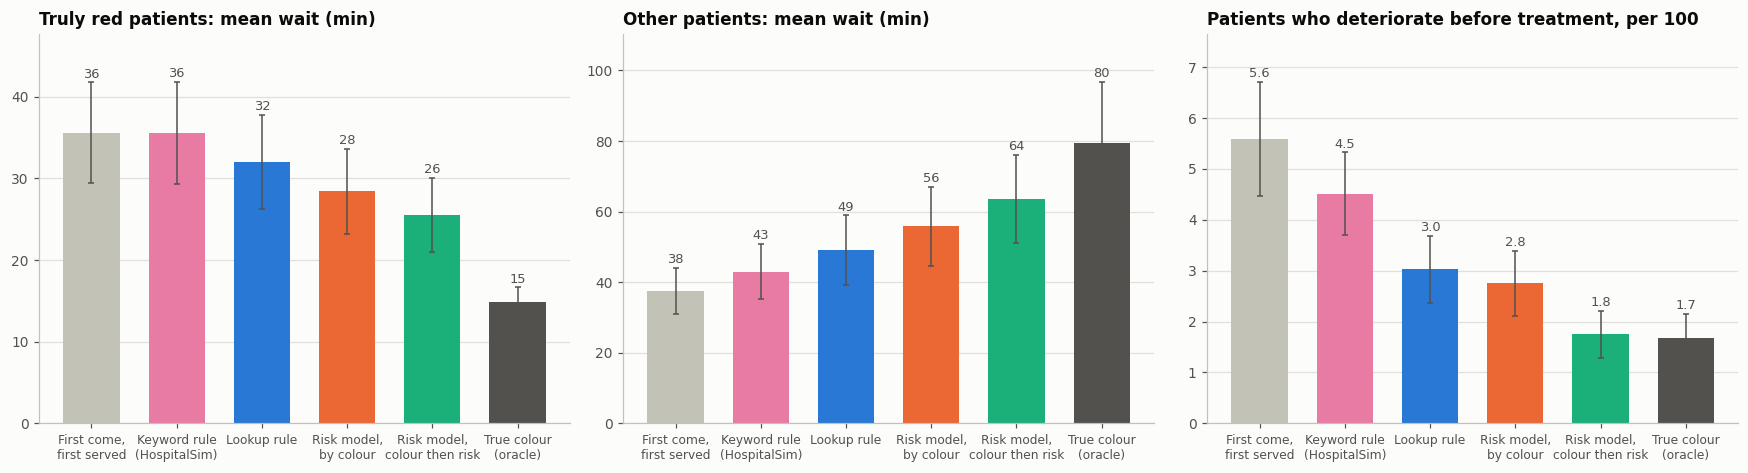

In [33]:
t0 = time.time(); RUNS = make_runs(); SIM = {k: evaluate(POLICY[k], ASSIGNED[k], RUNS) for k in POLICY}
ci95 = lambda s: 1.96 * s.std(ddof=1) / np.sqrt(len(s))
SIMT = pd.DataFrame({k: {"red wait, mean (min)": v.red_wait.mean(), "± 95% CI": ci95(v.red_wait), "red wait, 90th pct": v.red_p90.mean(), "other wait, mean (min)": v.other_wait.mean(),
                         "all, mean (min)": v.all_wait.mean(), "mean queue length": v.queue_len.mean(), "red within 10 min": v.red_within_target.mean(),
                         "deteriorated per 100": v.deteriorated_per_100.mean(), "missed red per 100": v.missed_red_per_100.mean(), "over-triaged per 100": v.over_triage_per_100.mean()} for k, v in SIM.items()}).T
SIMT["red wait vs first come"] = SIMT["red wait, mean (min)"] / SIMT.loc["First come, first served", "red wait, mean (min)"] - 1
SIMT[f"J (w={ASSUMED_W})"] = [J_cost(SIM[k].mean(), ASSUMED_W) if ASSIGNED[k] is not None else np.nan for k in SIMT.index]
display(SIMT.round(2)); print(f"({time.time() - t0:.0f} s)")
print("J for 'first come, first served' is not defined: without triage there is no triage decision to count as missed or over-triaged.")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4)); names = list(SIM); xs = np.arange(len(names))
for a_, (col, ttl, fmt) in zip(ax, [("red_wait", "Truly red patients: mean wait (min)", "{:.0f}"), ("other_wait", "Other patients: mean wait (min)", "{:.0f}"), ("deteriorated_per_100", "Patients who deteriorate before treatment, per 100", "{:.1f}")]):
    v = [SIM[k][col].mean() for k in names]; e = [ci95(SIM[k][col]) for k in names]
    b = a_.bar(xs, v, yerr=e, color=[POL_COL[k] for k in names], width=0.66, error_kw=dict(ecolor=INK2, lw=1, capsize=2)); bar_labels(a_, b, fmt, err=e)
    a_.set_xticks(xs); a_.set_xticklabels([k.replace(" (", "\n(").replace(", ", ",\n") for k in names], fontsize=8); a_.set_title(ttl); a_.grid(axis="x", visible=False); a_.set_ylim(0, max(np.add(v, e)) * 1.14)
show("fig_queue_base")

### Waits by colour: green, yellow and red
The second professor asked for the green waiting time as well. The table shows the mean wait of truly green, yellow and red patients under every rule (same patients, arrivals and treatment times as the base case above) and the share who start treatment within their target (green 120, yellow 60, red 10 minutes; all assumed). The red column must equal the red wait in the base-case table.

In [34]:
# Waits by true colour (green, yellow, red) and share treated within the target, for every rule.
# Uses the same RUNS (patients, arrivals, treatment times) as the base case in 6.2, so the red column must match the base-case table.
def wait_by_colour(prio, assigned, runs, servers=SERVERS, overhead=OVERHEAD):
    rec = []
    for ii, arr, base in runs:
        t = TRUE_T[ii]; a = None if assigned is None else assigned[ii]
        svc = base if a is None else base + overhead * ((a == 2) & (t < 2))
        w = simulate(arr, None if prio is None else prio[ii], svc, servers); r = {}
        for c, name in enumerate(["green", "yellow", "red"]):
            m = t == c
            r[f"{name} wait"] = w[m].mean() if m.any() else np.nan
            r[f"{name} within {TARGET[c]:.0f} min"] = np.mean(w[m] <= TARGET[c]) if m.any() else np.nan
        rec.append(r)
    return pd.DataFrame(rec)

WBC = {k: wait_by_colour(POLICY[k], ASSIGNED[k], RUNS) for k in POLICY}
WAIT_COLOUR = pd.DataFrame({k: v.mean() for k, v in WBC.items()}).T[["green wait", "yellow wait", "red wait", "green within 120 min", "yellow within 60 min", "red within 10 min"]]
display(WAIT_COLOUR.round(2))
# check: the red wait must equal the base-case table
print("Max difference to the red wait in 6.2:", float((WAIT_COLOUR["red wait"] - SIMT["red wait, mean (min)"]).abs().max()))

,green wait,yellow wait,red wait,green within 120 min,yellow within 60 min,red within 10 min
"First come, first served",35.49,37.76,35.61,0.95,0.75,0.42
Keyword rule (HospitalSim),72.49,40.34,35.55,0.76,0.78,0.54
Lookup rule,109.24,43.71,32.04,0.68,0.80,0.53
"Risk model, by colour",115.46,50.88,28.42,0.74,0.78,0.52
"Risk model, colour then risk",123.13,58.59,25.55,0.72,0.77,0.62
True colour (oracle),176.99,71.18,14.91,0.63,0.61,0.58


Max difference to the red wait in 6.2: 0.0


## 6.3 The objective function
$J = \alpha\cdot\text{MissedRed} + \beta\cdot\text{RedWait} + \gamma\cdot\text{OtherWait} + \delta\cdot\text{OverTriage}$ with β = 1, γ = 0.2, δ = 1 and α = *w*·δ. MissedRed and OverTriage are per 100 patients, waits in minutes. The table shows the four parts for each triage rule at *w* = 10.

In [35]:
rows = []
for k in POLICY:
    if ASSIGNED[k] is None: continue
    m = SIM[k].mean()
    rows.append({"rule": k, "alpha x MissedRed": ASSUMED_W * DELTA * m.missed_red_per_100, "beta x RedWait": BETA * m.red_wait, "gamma x OtherWait": GAMMA * m.other_wait,
                 "delta x OverTriage": DELTA * m.over_triage_per_100, "J": J_cost(m, ASSUMED_W)})
JTAB = pd.DataFrame(rows).set_index("rule"); display(JTAB.round(1))
BEST_J = JTAB.drop(index="True colour (oracle)").J.idxmin()
print(f"Lowest J among usable rules at w = {ASSUMED_W}: {BEST_J} (the oracle is a bound, not a usable rule).")
print("Missed red patients dominate J at this cost ratio. The weights are assumptions; §6.4 shows how the best decision moves with w.")

,alpha x MissedRed,beta x RedWait,gamma x OtherWait,delta x OverTriage,J
rule,,,,,
Keyword rule (HospitalSim),497.2,35.6,8.6,0.0,541.4
Lookup rule,384.4,32.0,9.8,0.0,426.2
"Risk model, by colour",60.2,28.4,11.2,29.5,129.4
"Risk model, colour then risk",60.2,25.6,12.7,29.5,128.1
True colour (oracle),0.0,14.9,15.9,0.0,30.8


Lowest J among usable rules at w = 10: Risk model, colour then risk (the oracle is a bound, not a usable rule).
Missed red patients dominate J at this cost ratio. The weights are assumptions; §6.4 shows how the best decision moves with w.


## 6.4 The cost-sensitivity frontier with waiting times and congestion
The decision weight *w′* of the risk model is moved from 1 to 25 (queue rule: by colour). For each value the same simulated days are replayed. The six panels show what the feedback asked for: red recall, over-triage, red waiting time, waiting time of the others, queue congestion, and the objective *J* for four assumed cost ratios *w*.

,w',red_recall,over_triage,red_wait,green_wait,yellow_wait,other_wait,queue_len,deteriorated_per_100,J@w=2,J@w=5,J@w=10,J@w=25
0,1.0,0.67,0.13,28.97,120.84,50.64,56.21,3.57,2.49,87.14,137.73,222.04,474.98
1,1.5,0.78,0.21,29.06,121.34,49.30,54.93,3.53,2.54,82.72,115.72,170.72,335.72
2,2.0,0.82,0.24,28.16,121.78,50.43,56.08,3.54,2.52,81.01,108.20,153.51,289.45
3,3.0,0.88,0.30,28.42,115.46,50.88,55.85,3.54,2.75,81.18,99.26,129.38,219.76
4,4.0,0.91,0.33,28.05,100.92,50.16,54.24,3.45,2.89,80.84,94.94,118.44,188.94
5,5.0,0.93,0.36,28.17,95.91,51.46,55.13,3.50,3.09,81.27,92.18,110.37,164.93
6,8.0,0.96,0.40,28.19,86.41,52.61,55.25,3.52,3.65,81.66,87.06,96.06,123.06
7,10.0,0.97,0.42,29.05,85.52,50.90,53.52,3.49,3.86,83.32,87.71,95.02,116.96
8,15.0,0.98,0.44,30.69,83.07,47.60,50.33,3.43,4.59,85.68,88.20,92.38,104.95
9,25.0,1.00,0.47,32.58,69.27,43.75,45.61,3.31,5.05,88.02,88.55,89.42,92.05


Decision weight with the lowest J, for each assumed cost ratio w: {2: 4.0, 5: 8.0, 10: 25.0, 25: 25.0} (0 s)


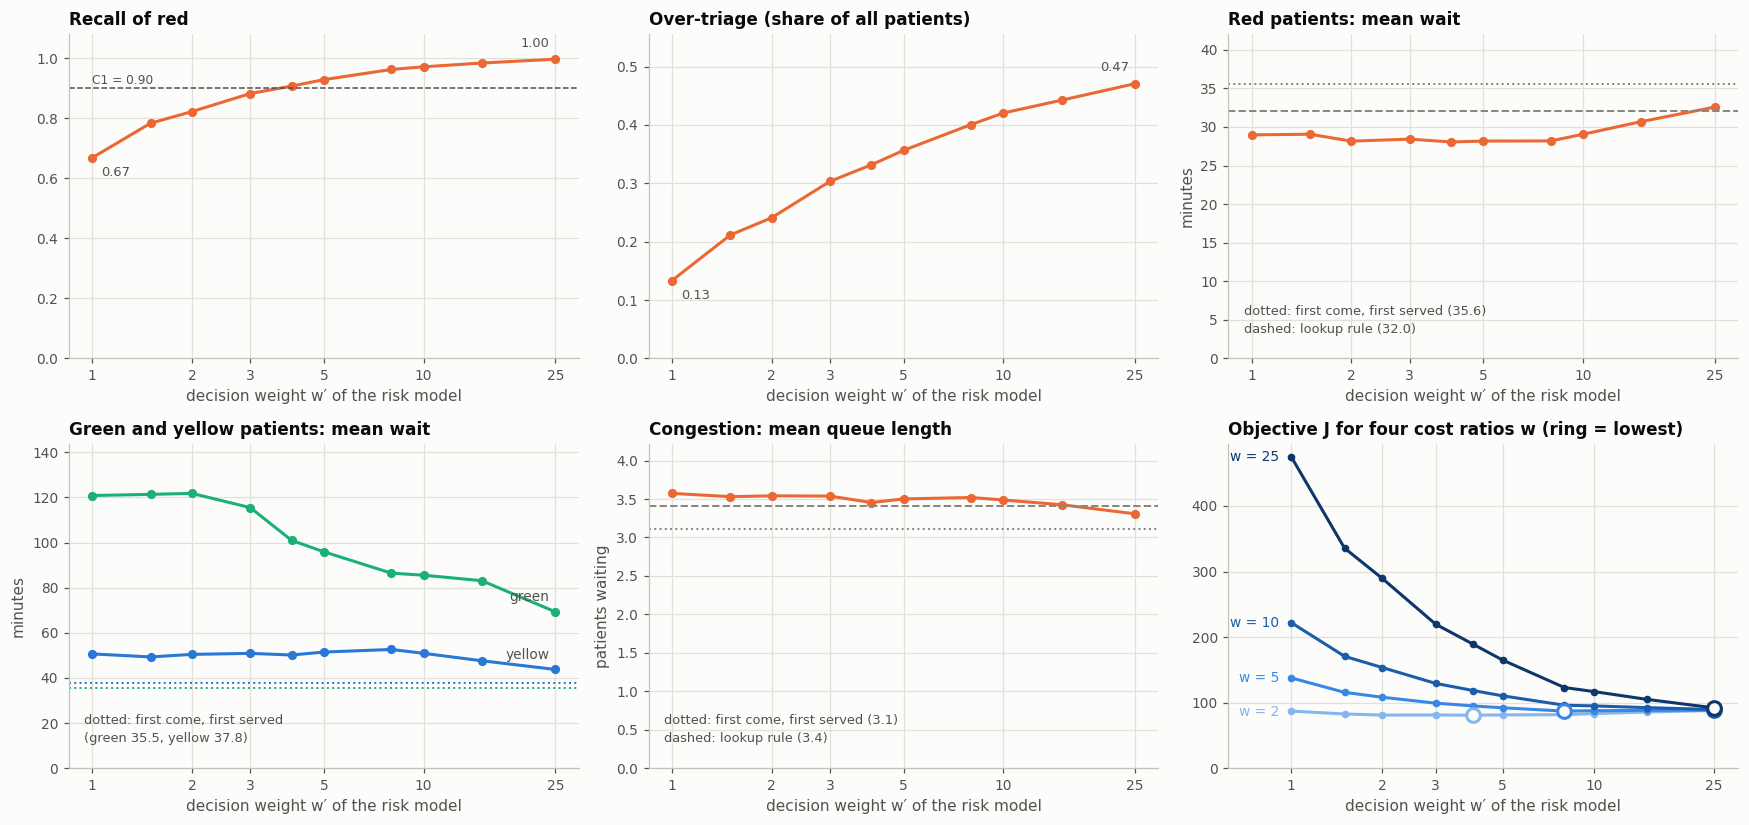

In [36]:
t0 = time.time(); WQ = [1, 1.5, 2, 3, 4, 5, 8, 10, 15, 25]; rows = []
for w in WQ:
    a_ = decide(proba_test, w, LK_TEST); m = evaluate(a_, a_, RUNS).mean(); lm = level_metrics(y_test, a_); wc = wait_by_colour(a_, a_, RUNS).mean()
    rows.append({"w'": w, "red_recall": lm["red_recall"], "over_triage": lm["over_triage"], "red_wait": m.red_wait, "green_wait": wc["green wait"], "yellow_wait": wc["yellow wait"], "other_wait": m.other_wait, "queue_len": m.queue_len,
                 "deteriorated_per_100": m.deteriorated_per_100, **{f"J@w={r}": J_cost(m, r) for r in (2, 5, 10, 25)}})
FQ = pd.DataFrame(rows); display(FQ.round(2))
BEST_WQ = {r: float(FQ.loc[FQ[f"J@w={r}"].idxmin(), "w'"]) for r in (2, 5, 10, 25)}
print("Decision weight with the lowest J, for each assumed cost ratio w:", BEST_WQ, f"({time.time() - t0:.0f} s)")

fig, axs = plt.subplots(2, 3, figsize=(16, 7.6)); axs = axs.ravel()
ref = {"red_recall": 0.90}; fifo, lk_ = SIM["First come, first served"].mean(), SIM["Lookup rule"].mean()
for a_, (col, ttl, unit) in zip(axs[:5], [("red_recall", "Recall of red", ""), ("over_triage", "Over-triage (share of all patients)", ""), ("red_wait", "Red patients: mean wait", " min"),
                                           ("other_wait", "Other patients: mean wait", " min"), ("queue_len", "Congestion: mean queue length", " patients")]):
    a_.plot(FQ["w'"], FQ[col], marker="o", ms=5, color=ORANGE); a_.set_title(ttl)
    if col in ("red_recall", "over_triage"):
        a_.annotate(f"{FQ[col].iloc[0]:.2f}", (FQ["w'"].iloc[0], FQ[col].iloc[0]), textcoords="offset points", xytext=(6, -12), fontsize=8.5, color=INK2)
        a_.annotate(f"{FQ[col].iloc[-1]:.2f}", (FQ["w'"].iloc[-1], FQ[col].iloc[-1]), textcoords="offset points", xytext=(-4, 8), ha="right", fontsize=8.5, color=INK2)
    else:
        a_.set_ylabel("minutes" if "wait" in col else "patients waiting")
    if col == "red_recall": a_.axhline(0.90, color=INK2, ls="--", lw=1); a_.text(1, 0.915, "C1 = 0.90", fontsize=8, color=INK2)
    a_.set_ylim(0, 1.08 if col == "red_recall" else max(FQ[col].max(), fifo[col] if col in fifo.index else 0, lk_[col] if col in lk_.index else 0) * 1.18)       # axes start at zero: differences are shown at their true size
    if col in ("red_wait", "other_wait", "queue_len"):
        a_.axhline(fifo[col], color=MUTED, ls=":", lw=1.3); a_.axhline(lk_[col], color=MUTED, ls="--", lw=1.3)
        a_.text(0.03, 0.08, f"dotted: first come, first served ({fifo[col]:.1f})\ndashed: lookup rule ({lk_[col]:.1f})", transform=a_.transAxes, fontsize=8.5, color=INK2, linespacing=1.5)
# panel 4: waits of green and yellow patients (the second professor asked for the green waiting time)
a_ = axs[3]; a_.clear(); fw = WAIT_COLOUR.loc["First come, first served"]
a_.plot(FQ["w'"], FQ["green_wait"], marker="o", ms=5, color=AQUA); a_.plot(FQ["w'"], FQ["yellow_wait"], marker="o", ms=5, color=BLUE)
a_.axhline(fw["green wait"], color=AQUA, ls=":", lw=1.3); a_.axhline(fw["yellow wait"], color=BLUE, ls=":", lw=1.3)
a_.annotate("green", (FQ["w'"].iloc[-1], FQ["green_wait"].iloc[-1]), textcoords="offset points", xytext=(-4, 7), ha="right", fontsize=9, color=INK2)
a_.annotate("yellow", (FQ["w'"].iloc[-1], FQ["yellow_wait"].iloc[-1]), textcoords="offset points", xytext=(-4, 7), ha="right", fontsize=9, color=INK2)
a_.set_title("Green and yellow patients: mean wait"); a_.set_ylabel("minutes"); a_.set_ylim(0, max(FQ["green_wait"].max(), fw["green wait"]) * 1.18)
a_.text(0.03, 0.08, f"dotted: first come, first served\n(green {fw['green wait']:.1f}, yellow {fw['yellow wait']:.1f})", transform=a_.transAxes, fontsize=8.5, color=INK2, linespacing=1.5)
for r, colr in zip((2, 5, 10, 25), ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]):
    axs[5].plot(FQ["w'"], FQ[f"J@w={r}"], marker="o", ms=4, color=colr); axs[5].annotate(f"w = {r}", (FQ["w'"].iloc[0], FQ[f"J@w={r}"].iloc[0]), textcoords="offset points", xytext=(-8, -3), ha="right", fontsize=9, color=colr)
    j = int(FQ[f"J@w={r}"].to_numpy().argmin()); axs[5].scatter(FQ["w'"].iloc[j], FQ[f"J@w={r}"].iloc[j], s=80, facecolor=SURFACE, edgecolor=colr, linewidth=2, zorder=3)
axs[5].set_title("Objective J for four cost ratios w (ring = lowest)"); axs[5].set_ylim(0, None)
for a_ in axs:
    a_.set_xscale("log"); a_.set_xticks([1, 2, 3, 5, 10, 25]); a_.set_xticklabels(["1", "2", "3", "5", "10", "25"]); a_.minorticks_off(); a_.set_xlabel("decision weight w′ of the risk model")
axs[5].set_xlim(0.62, 30)
show("fig_frontier_queue")

## 6.5 Experimental design and sensitivity
The result depends on assumed inputs, so they are varied in a designed experiment: a **full factorial** of utilisation (0.80, 0.90, 0.95) and treatment-time level (0.75, 1.00, 1.25 times the assumed means), and **one factor at a time** for the number of places, the length of a run, the treatment-time distribution and the **extra work caused by over-triage**. 25 runs per point.

| Status | Factor | Reason |
|---|---|---|
| Independent variable | triage rule | the decision under study |
| Varied, full factorial | utilisation; treatment-time level | unknown for a real department and they drive waiting non-linearly |
| Varied, one at a time | places; patients per run; distribution; extra minutes per over-triaged patient (0 in the base case, 5 and 10 here) | capacity, run length, variability, **effect of over-triage on congestion** |
| Fixed | patient mix; model and its errors; ratio of treatment times 40/25/12 | the mix comes from the archive; model errors are the content of the comparison |
| Left out | transport, bed blocking, staff types, patients leaving, re-triage | no data |

,design,utilisation,time level,places,patients,distribution,extra min per over-triage,red wait: first come,red wait: lookup,red wait: model,red wait: oracle,reduction model vs first come,other wait: first come,other wait: model,deteriorated per 100: first come,deteriorated per 100: model,H holds
0,full factorial,0.80,0.75,3,200,exp,0.0,6.01,5.54,5.16,3.93,0.14,6.77,9.11,0.52,0.28,True
1,full factorial,0.80,1.00,3,200,exp,0.0,24.89,22.44,18.29,11.38,0.27,26.18,39.91,3.38,1.28,True
2,full factorial,0.80,1.25,3,200,exp,0.0,109.42,93.35,65.85,26.61,0.40,112.12,192.17,12.88,3.96,True
3,full factorial,0.90,0.75,3,200,exp,0.0,9.24,8.57,7.06,5.35,0.24,10.14,14.64,0.76,0.32,True
4,full factorial,0.90,1.00,3,200,exp,0.0,47.58,42.59,32.32,16.10,0.32,48.78,82.29,6.26,2.26,True
5,full factorial,0.90,1.25,3,200,exp,0.0,192.50,160.49,106.82,37.46,0.45,195.89,336.54,19.62,5.52,True
6,full factorial,0.95,0.75,3,200,exp,0.0,11.47,10.35,8.71,6.15,0.24,12.35,18.21,1.12,0.38,True
7,full factorial,0.95,1.00,3,200,exp,0.0,66.29,57.60,41.25,19.11,0.38,67.83,116.50,8.84,2.90,True
8,full factorial,0.95,1.25,3,200,exp,0.0,237.09,198.64,130.86,44.91,0.45,240.46,420.31,22.32,6.54,True
9,one at a time,0.90,1.00,2,200,exp,0.0,78.24,69.85,52.11,28.24,0.33,80.26,135.86,9.58,3.70,True


Without extra work for over-triage (14 design points): H holds in 14 of 14; the risk model changes the red wait by -47% to -14% against first come, first served; the others wait 1.3 to 1.8 times as long.
With 5 extra minutes per over-triaged patient: red wait 40 min with the model against 48 min first come, first served (-15%); others 113 against 49 min; H holds.
With 10 extra minutes per over-triaged patient: red wait 50 min with the model against 48 min first come, first served (+6%); others 152 against 49 min; H does NOT hold.
-> Over-triage is not free. If each over-triaged patient costs extra treatment time, the queue fills up and the gain for red patients shrinks or turns into a loss. (0 s)


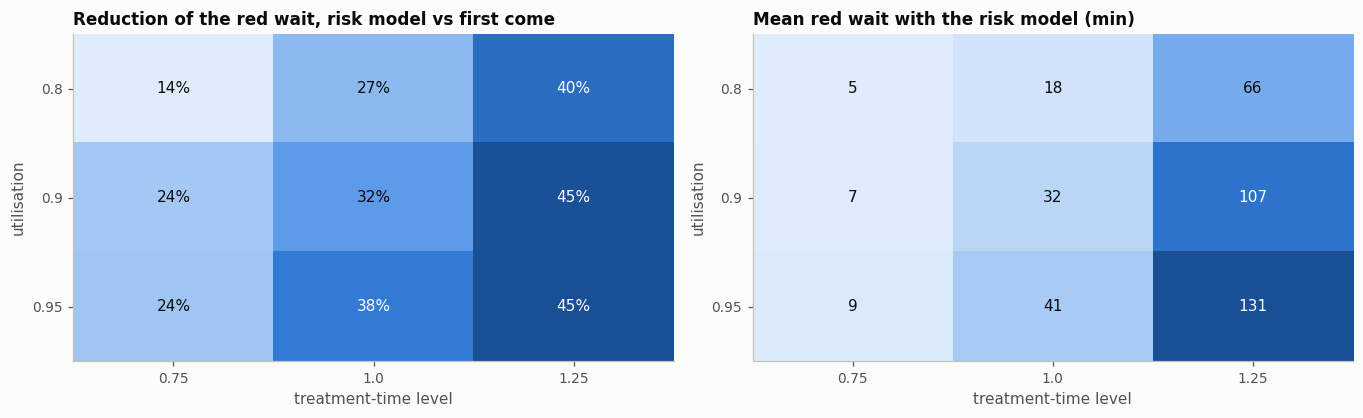

In [37]:
t0 = time.time(); SENS_POL = ["True colour (oracle)", "Risk model, colour then risk", "Lookup rule", "First come, first served"]; MODEL_Q = "Risk model, colour then risk"
design = [("full factorial", r_, l_, SERVERS, N_PAT, "exp", OVERHEAD) for r_ in (0.80, 0.90, 0.95) for l_ in (0.75, 1.0, 1.25)]
design += [("one at a time", RHO, 1.0, s_, N_PAT, "exp", OVERHEAD) for s_ in (2, 4)] + [("one at a time", RHO, 1.0, SERVERS, n_, "exp", OVERHEAD) for n_ in (100, 400)]
design += [("one at a time", RHO, 1.0, SERVERS, N_PAT, "gamma", OVERHEAD)] + [("one at a time", RHO, 1.0, SERVERS, N_PAT, "exp", o_) for o_ in (5.0, 10.0)]
rows = []
for kind, r_, l_, s_, n_, d_, o_ in design:
    runs = make_runs(25, n_, r_, s_, l_, d_, seed=SEED + 101); m = {k: evaluate(POLICY[k], ASSIGNED[k], runs, s_, o_).mean() for k in SENS_POL}
    rw = [m[k].red_wait for k in SENS_POL]
    rows.append({"design": kind, "utilisation": r_, "time level": l_, "places": s_, "patients": n_, "distribution": d_, "extra min per over-triage": o_, "red wait: first come": m["First come, first served"].red_wait,
                 "red wait: lookup": m["Lookup rule"].red_wait, "red wait: model": m[MODEL_Q].red_wait, "red wait: oracle": m["True colour (oracle)"].red_wait,
                 "reduction model vs first come": 1 - m[MODEL_Q].red_wait / m["First come, first served"].red_wait, "other wait: first come": m["First come, first served"].other_wait,
                 "other wait: model": m[MODEL_Q].other_wait, "deteriorated per 100: first come": m["First come, first served"].deteriorated_per_100, "deteriorated per 100: model": m[MODEL_Q].deteriorated_per_100,
                 "H holds": all(rw[i] <= rw[i + 1] + 1e-9 for i in range(3))})
SENS = pd.DataFrame(rows); display(SENS.round(2))
no_oh = SENS[SENS["extra min per over-triage"] == 0]; oh = SENS[SENS["extra min per over-triage"] > 0]
RED_RANGE = (float(no_oh["reduction model vs first come"].min()), float(no_oh["reduction model vs first come"].max()))
OTHER_RATIO = (float((no_oh["other wait: model"] / no_oh["other wait: first come"]).min()), float((no_oh["other wait: model"] / no_oh["other wait: first come"]).max()))
print(f"Without extra work for over-triage ({len(no_oh)} design points): H holds in {int(no_oh['H holds'].sum())} of {len(no_oh)}; the risk model changes the red wait by {-RED_RANGE[1]:+.0%} to {-RED_RANGE[0]:+.0%} against first come, first served; "
      f"the others wait {OTHER_RATIO[0]:.1f} to {OTHER_RATIO[1]:.1f} times as long.")
for _, r_ in oh.iterrows():
    print(f"With {r_['extra min per over-triage']:.0f} extra minutes per over-triaged patient: red wait {r_['red wait: model']:.0f} min with the model against {r_['red wait: first come']:.0f} min first come, first served "
          f"({-r_['reduction model vs first come']:+.0%}); others {r_['other wait: model']:.0f} against {r_['other wait: first come']:.0f} min; H {'holds' if r_['H holds'] else 'does NOT hold'}.")
print(f"-> Over-triage is not free. If each over-triaged patient costs extra treatment time, the queue fills up and the gain for red patients shrinks or turns into a loss. ({time.time() - t0:.0f} s)")

ff = SENS[SENS.design == "full factorial"]; fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.9))
for a_, (val, ttl, fmt) in zip(ax, [("reduction model vs first come", "Reduction of the red wait, risk model vs first come", "{:.0%}"), ("red wait: model", "Mean red wait with the risk model (min)", "{:.0f}")]):
    pv = ff.pivot(index="utilisation", columns="time level", values=val).to_numpy(); lab = ff.pivot(index="utilisation", columns="time level", values=val)
    a_.imshow(pv, cmap=SEQ, aspect="auto", vmin=pv.min() - 0.15 * (pv.max() - pv.min()), vmax=pv.max())
    for i in range(pv.shape[0]):
        for j in range(pv.shape[1]): a_.text(j, i, fmt.format(pv[i, j]), ha="center", va="center", fontsize=10, color="#ffffff" if pv[i, j] > pv.min() + 0.6 * (pv.max() - pv.min()) else INK)
    a_.set_xticks(range(pv.shape[1])); a_.set_xticklabels(lab.columns); a_.set_yticks(range(pv.shape[0])); a_.set_yticklabels(lab.index); a_.set_xlabel("treatment-time level"); a_.set_ylabel("utilisation"); a_.set_title(ttl); a_.grid(False)
show("fig_queue_sensitivity")

## 6.6 A capacity question
The second decision variable of §1.3 is the number of treatment places. With the arrival rate of the base case fixed, how many places does each triage rule need so that at least 90 % of the truly red patients start treatment within the 10-minute target?

In [38]:
t0 = time.time(); rows = []; CAP_POL = ["First come, first served", "Lookup rule", "Risk model, by colour", "Risk model, colour then risk", "True colour (oracle)"]
for c_ in (3, 4, 5, 6):
    for k in CAP_POL:
        m = evaluate(POLICY[k], ASSIGNED[k], RUNS, servers=c_).mean()        # same arrivals as the base case, more places
        rows.append({"places": c_, "rule": k, "red within 10 min": m.red_within_target, "red wait (min)": m.red_wait, "other wait (min)": m.other_wait, "deteriorated per 100": m.deteriorated_per_100})
CAP = pd.DataFrame(rows)
print("Share of truly red patients who start treatment within 10 minutes:"); display(CAP.pivot(index="rule", columns="places", values="red within 10 min").reindex(CAP_POL).round(2))
print("Patients who deteriorate before treatment, per 100:"); display(CAP.pivot(index="rule", columns="places", values="deteriorated per 100").reindex(CAP_POL).round(2))
NEED = {k: (int(g[g["red within 10 min"] >= 0.90].places.min()) if (g["red within 10 min"] >= 0.90).any() else None) for k, g in CAP.groupby("rule")}
print("Smallest number of places with at least 90 % of red patients treated within 10 minutes:", {k: NEED[k] for k in CAP_POL}, f"({time.time() - t0:.0f} s)")
same = len(set(NEED.values())) == 1
print("Reading:", "every rule needs the same number of places for the 10-minute target. With about half of the patients truly red, the target is a capacity question; triage decides who is helped first, and it lowers the number of patients who deteriorate."
      if same else "a better triage rule reaches the target with fewer places. Whether that is cheaper than one more place depends on staffing costs, which the hospital must supply.")

QUEUE_SUMMARY = {"assumptions": {"servers": SERVERS, "utilisation": RHO, "patients_per_run": N_PAT, "runs": N_RUNS, "service_mean_green_yellow_red": SERVICE_MEAN.tolist(), "extra_min_per_overtriage_base": OVERHEAD,
                                 "targets_green_yellow_red_min": TARGET.tolist(), "J_weights": {"beta": BETA, "gamma": GAMMA, "delta": DELTA, "alpha": "w x delta"}},
                 "base_case": SIMT.round(3).reset_index().rename(columns={"index": "rule"}).to_dict(orient="records"), "J_parts": JTAB.round(2).reset_index().to_dict(orient="records"),
                 "frontier": FQ.round(3).to_dict(orient="records"), "best_w_by_cost_ratio_J": BEST_WQ, "sensitivity_points": int(len(SENS)), "H_holds_in": int(SENS["H holds"].sum()),
                 "red_wait_reduction_range": RED_RANGE, "other_wait_ratio_range": OTHER_RATIO, "sensitivity": SENS.round(3).to_dict(orient="records"),
                 "capacity": CAP.round(3).to_dict(orient="records"), "places_needed": NEED,
                 "wait_by_colour": WAIT_COLOUR.round(3).reset_index().rename(columns={"index": "rule"}).to_dict(orient="records")}

Share of truly red patients who start treatment within 10 minutes:


places,3,4,5,6
rule,,,,
"First come, first served",0.42,0.81,0.95,0.99
Lookup rule,0.53,0.84,0.96,0.99
"Risk model, by colour",0.52,0.84,0.95,0.99
"Risk model, colour then risk",0.62,0.87,0.96,0.99
True colour (oracle),0.58,0.87,0.96,0.99


Patients who deteriorate before treatment, per 100:


places,3,4,5,6
rule,,,,
"First come, first served",5.59,0.41,0.04,0.02
Lookup rule,3.02,0.31,0.02,0.02
"Risk model, by colour",2.75,0.34,0.05,0.02
"Risk model, colour then risk",1.75,0.22,0.04,0.01
True colour (oracle),1.68,0.14,0.02,0.02


Smallest number of places with at least 90 % of red patients treated within 10 minutes: {'First come, first served': 5, 'Lookup rule': 5, 'Risk model, by colour': 5, 'Risk model, colour then risk': 5, 'True colour (oracle)': 5} (0 s)
Reading: every rule needs the same number of places for the 10-minute target. With about half of the patients truly red, the target is a capacity question; triage decides who is helped first, and it lowers the number of patients who deteriorate.


### Staffing cost of a treatment place
The archive has no information about nurses, doctors or their pay, so **the price of a place is a parameter, not a measurement**. We write *s* for the cost of one treatment place (a room with its staff) for one hour, in the units of J (one unit = one over-triaged patient per 100 patients, §6.3). The staffing cost of a run is *places* × *hours in which 100 patients arrive* × *s*. For each rule we add it to J at *w* = 10 and ask two questions: how many places give the lowest total for each *s*, and **what must a place-hour cost for one more place to pay off** (break-even *s*)? The First come, first served rule is not in this table because J has no meaning for a rule that gives no colour (§6.3); its 10-minute result is in §6.6. Nurses and doctors as separate resources are not modelled.

In [39]:
# Staffing cost: s = cost of one treatment place for one hour, in J units (assumed). Total = J(w = 10) + places x hours x s, per 100 patients.
HOURS_PER_100 = 100 * MEAN_SVC / (SERVERS * RHO) / 60           # hours in which 100 patients arrive at the base-case rate
S_GRID = [0, 0.5, 1, 2, 5]; PLACES = (3, 4, 5, 6); STAFF_RULES = ["Lookup rule", "Risk model, by colour", "Risk model, colour then risk"]
t0 = time.time(); rows = []
for c_ in PLACES:
    for k in STAFF_RULES:
        m = evaluate(POLICY[k], ASSIGNED[k], RUNS, servers=c_).mean()        # same arrivals as the base case
        rows.append({"places": c_, "rule": k, "J": J_cost(m, ASSUMED_W), "red wait (min)": m.red_wait, "other wait (min)": m.other_wait, "red within 10 min": m.red_within_target, "staffing hours per 100 patients": c_ * HOURS_PER_100})
STAFF = pd.DataFrame(rows)
for s_ in S_GRID: STAFF[f"total @ s={s_:g}"] = STAFF.J + s_ * STAFF["staffing hours per 100 patients"]
print(f"100 patients arrive in {HOURS_PER_100:.1f} hours at the base-case rate. Total cost (J + staffing) per 100 patients, by number of places:")
for k in STAFF_RULES:
    print(f"\n{k}:"); display(STAFF[STAFF.rule == k].set_index("places")[["J"] + [f"total @ s={s_:g}" for s_ in S_GRID]].round(1))
BEST_PLACES = {k: {s_: int(STAFF[STAFF.rule == k].sort_values(f"total @ s={s_:g}").iloc[0].places) for s_ in S_GRID} for k in STAFF_RULES}
print("Number of places with the lowest total cost, for each assumed cost s of a place-hour:"); display(pd.DataFrame(BEST_PLACES).T.rename_axis("rule"))
BREAK_EVEN = {}
for k in STAFF_RULES:
    j = STAFF[STAFF.rule == k].set_index("places").J; BREAK_EVEN[k] = {f"{a}->{b}": float((j[a] - j[b]) / HOURS_PER_100) for a, b in zip(PLACES[:-1], PLACES[1:])}
BE = pd.DataFrame(BREAK_EVEN).T; print("Break-even s: one more place pays off if a place-hour costs less than this (J units):"); display(BE.round(2))
print(f"Reading: going from 3 to 4 places pays off for the risk model (colour, then risk) as long as one place-hour costs less than {BE.loc['Risk model, colour then risk', '3->4']:.1f} J units, "
      f"from 4 to 5 places below {BE.loc['Risk model, colour then risk', '4->5']:.1f}. The step to 6 places is worth {BE.loc['Risk model, colour then risk', '5->6']:.1f}. "
      "J mixes minutes and patient counts, so these break-even values are relative, not money. To use them, the hospital must say what one over-triaged patient costs in money; s is then the price of a place-hour divided by that amount.")
PATIENT_SUMMARY["symptom_type_subgroups"] = SYM_TYPE_RECORDS
QUEUE_SUMMARY["staffing"] = {"assumption": "cost of one treatment place per hour s, in J units; J at w = 10", "hours_per_100_patients": float(HOURS_PER_100), "break_even_s": BREAK_EVEN,
                             "best_places_by_s": {k: {str(s_): v for s_, v in d.items()} for k, d in BEST_PLACES.items()}, "table": STAFF.round(3).to_dict(orient="records")}
print(f"({time.time() - t0:.0f} s)")


100 patients arrive in 19.7 hours at the base-case rate. Total cost (J + staffing) per 100 patients, by number of places:

Lookup rule:


,J,total @ s=0,total @ s=0.5,total @ s=1,total @ s=2,total @ s=5
places,,,,,,
3,426.2,426.2,455.8,485.3,544.5,721.8
4,391.3,391.3,430.8,470.2,549.0,785.4
5,385.9,385.9,435.2,484.5,583.0,878.5
6,384.8,384.8,443.9,503.0,621.2,975.9



Risk model, by colour:


,J,total @ s=0,total @ s=0.5,total @ s=1,total @ s=2,total @ s=5
places,,,,,,
3,129.4,129.4,158.9,188.5,247.6,424.9
4,96.6,96.6,136.0,175.5,254.3,490.7
5,91.4,91.4,140.7,189.9,288.4,584.0
6,90.2,90.2,149.3,208.4,326.6,681.3



Risk model, colour then risk:


,J,total @ s=0,total @ s=0.5,total @ s=1,total @ s=2,total @ s=5
places,,,,,,
3,128.1,128.1,157.6,187.2,246.3,423.6
4,96.3,96.3,135.8,175.2,254.0,490.4
5,91.3,91.3,140.5,189.8,288.3,583.9
6,90.2,90.2,149.3,208.4,326.6,681.3


Number of places with the lowest total cost, for each assumed cost s of a place-hour:


,0.0,0.5,1.0,2.0,5.0
rule,,,,,
Lookup rule,6,4,4,3,3
"Risk model, by colour",6,4,4,3,3
"Risk model, colour then risk",6,4,4,3,3


Break-even s: one more place pays off if a place-hour costs less than this (J units):


,3->4,4->5,5->6
Lookup rule,1.77,0.27,0.06
"Risk model, by colour",1.66,0.27,0.06
"Risk model, colour then risk",1.61,0.26,0.06


Reading: going from 3 to 4 places pays off for the risk model (colour, then risk) as long as one place-hour costs less than 1.6 J units, from 4 to 5 places below 0.3. The step to 6 places is worth 0.1. J mixes minutes and patient counts, so these break-even values are relative, not money. To use them, the hospital must say what one over-triaged patient costs in money; s is then the price of a place-hour divided by that amount.
(0 s)


# 7. HospitalSim – baseline and demo

**What HospitalSim is.** An open-source package (The Swarm Corporation, MIT licence) in which language-model agents play receptionist, nurse, doctor and managers. Patients enter a priority queue. The priority comes from `Patient.calculate_priority`, a fixed keyword score.

**What we did with it.**
1. **Baseline (done above, no package needed).** Its keyword score is re-implemented in §5.2 and evaluated on the same patients as our rules (§5.5, §6.2). It recognises very few of the archive's critical patients, because its keywords cover few of the archive's symptoms.
2. **Demo (cell below, run in Google Colab).** A few archive patients are sent through HospitalSim twice: once with its own keyword priority and once with the priority from our risk model. The cell needs `pip install -U hospital-sim` and an OpenAI API key, and every patient costs several model calls, so it is an illustration, not an experiment. The agents' answers differ from run to run.

**Why we keep our own queue simulation for the numbers.** HospitalSim measures time with the real clock (how long the model calls take) and treats one patient at a time, so its waiting times are not simulated minutes and cannot be repeated.

In [40]:
RUN_HOSPITALSIM_DEMO = False        # set to True in Google Colab after `pip install -U hospital-sim` and setting OPENAI_API_KEY

def to_hospitalsim_inputs(P, k=4, seed=SEED):
    # pick k hold-out patients (two truly red, two not) and describe them for HospitalSim
    rng = np.random.default_rng(seed); red = P.index[P.true_level == 2].to_numpy(); oth = P.index[P.true_level < 2].to_numpy()
    pick = np.r_[rng.choice(red, k // 2, replace=False), rng.choice(oth, k - k // 2, replace=False)]; names = df.Symptom.to_numpy(); out = []
    for n_, i in enumerate(pick):
        syms = [str(s).lower() for s in names[P.loc[i, "revealed"]]]
        out.append({"name": f"Archive patient {n_ + 1}", "symptoms": syms, "chief_complaint": syms[0] if syms else "feels unwell", "true_colour": LEVEL_NAME[int(P.loc[i, "true_level"])],
                    "keyword_score": hsim_score(syms), "model_colour": LEVEL_NAME[int(P.loc[i, "a_" + M_C1])], "model_priority": {0: 3, 1: 10, 2: 20}[int(P.loc[i, "a_" + M_C1])]})
    return pd.DataFrame(out)
HSIM_DEMO = to_hospitalsim_inputs(P_test)
print("Patients prepared for the HospitalSim demo (priority 20 = emergency in HospitalSim's scale):"); display(HSIM_DEMO)

if RUN_HOSPITALSIM_DEMO:
    try:
        from hospital_sim.main import HospitalSimulation, Patient
        for label, use_model in [("HospitalSim keyword priority", False), ("priority from our risk model", True)]:
            hospital = HospitalSimulation(f"IND310 demo - {label}")
            for _, r in HSIM_DEMO.iterrows():
                p = Patient(name=r["name"], age=50, gender="unknown", chief_complaint=r["chief_complaint"], symptoms=list(r["symptoms"]))   # the archive has no age or sex; 50 is a placeholder
                if use_model: p.priority_score = int(r["model_priority"])      # replaces the keyword score before the patient enters the queue
                hospital.add_patient(p)
            hospital.run_simulation(duration_minutes=2, patient_arrival_rate=0.01)
    except Exception as e:
        print("HospitalSim demo not run:", type(e).__name__, e)
else:
    print("\nDemo not run here (RUN_HOSPITALSIM_DEMO = False). The table above shows what would be sent: the keyword score and the model's colour for the same patients.")

Patients prepared for the HospitalSim demo (priority 20 = emergency in HospitalSim's scale):


,name,symptoms,chief_complaint,true_colour,keyword_score,model_colour,model_priority
0,Archive patient 1,"[hand injury, skin avulsion, pain]",hand injury,red,5,red,20
1,Archive patient 2,"[petechiae, night sweats, weight loss]",petechiae,red,0,red,20
2,Archive patient 3,"[walking problems, back pain, neck pain]",walking problems,yellow,10,red,20
3,Archive patient 4,"[frequent falling, dysphagia, poor balance]",frequent falling,yellow,0,red,20



Demo not run here (RUN_HOSPITALSIM_DEMO = False). The table above shows what would be sent: the keyword score and the model's colour for the same patients.


# 8. Deployment and monitoring

## 8.1 How the result would be used
The product is **decision support for the triage nurse**, not an automatic triage. For each patient it returns: the lookup colour of what is revealed, the estimated probability of a red finding, the suggested colour at the chosen decision weight, and the two most likely departments. The nurse confirms or overrides. The function below is that product in its smallest form.

In [41]:
ALL_KB = np.ones(N_DX, bool)
def triage(symptoms, cannot_talk=0, immobile=0, bleeding=0, limp=0, weight=None):
    # symptoms: names as in the archive. Returns the decision-support output for one patient.
    weight = W_C1 if weight is None else weight
    known = [s for s in symptoms if s in SYM_ID]; unknown = [s for s in symptoms if s not in SYM_ID]
    one = pd.DataFrame([{"rev_sym": np.array([SYM_ID[s] for s in known], dtype=int), "dx": -1, "obs_cannot_talk": cannot_talk, "obs_immobile": immobile, "obs_bleeding": bleeding,
                         "obs_limp": limp, "obs_discomfort": np.nan}])
    F = kb_features(one, ALL_KB); F["n_revealed"] = len(symptoms); F["n_unknown"] = len(unknown)
    pr = model_P.predict_proba(F[P_COLS]); lk = max(int(F.lk_level.iloc[0]), 0); col = int(decide(pr, weight, np.array([lk]))[0])
    V = dept_votes(one, ALL_KB)[0]; top = [DEPTS[i] for i in np.argsort(-V)[:2]] if V.sum() > 0 else []
    return {"revealed": symptoms, "not in the archive": unknown, "lookup colour": LEVEL_NAME[lk], "probability of red": round(float(pr[0, 2]), 2), "suggested colour": LEVEL_NAME[col], "departments": top}

EXAMPLES = [dict(symptoms=["Fever", "Headache", "Fatigue"]), dict(symptoms=["Chest Pain", "Breathing Problems"]), dict(symptoms=["Pain", "Swelling"], immobile=1),
            dict(symptoms=["Abdominal Pain", "Vomiting", "Unknown new complaint"])]
display(pd.DataFrame([triage(**e) for e in EXAMPLES]))

t_ = []
for _ in range(30):
    t1 = time.perf_counter(); triage(["Fever", "Headache", "Fatigue"]); t_.append(1000 * (time.perf_counter() - t1))
joblib.dump({"model": model_P, "columns": P_COLS, "w_c1": W_C1, "w_cost": W_COST}, f"{OUT_DIR}/triage_risk_model.joblib")
SIZE_MB = os.path.getsize(f"{OUT_DIR}/triage_risk_model.joblib") / 1e6
DEPLOY = {"median_ms_per_patient": float(np.median(t_)), "p95_ms_per_patient": float(np.percentile(t_, 95)), "model_file_mb": float(SIZE_MB)}
print(f"One patient: median {DEPLOY['median_ms_per_patient']:.0f} ms, 95th percentile {DEPLOY['p95_ms_per_patient']:.0f} ms on this machine; model file {SIZE_MB:.1f} MB.")
print("A call per arriving patient from the triage desk (a small web service) is enough. Batch scoring is only needed for audits.")

,revealed,not in the archive,lookup colour,probability of red,suggested colour,departments
0,"[Fever, Headache, Fatigue]",[],yellow,0.44,red,"[infectious, emergency]"
1,"[Chest Pain, Breathing Problems]",[],yellow,0.46,red,"[internal medicine, cardiology]"
2,"[Pain, Swelling]",[],yellow,0.14,yellow,"[ortho, trauma]"
3,"[Abdominal Pain, Vomiting, Unknown new complaint]",[Unknown new complaint],yellow,0.66,red,"[general medicine, infectious]"


One patient: median 16 ms, 95th percentile 16 ms on this machine; model file 2.4 MB.
A call per arriving patient from the triage desk (a small web service) is enough. Batch scoring is only needed for audits.


## 8.2 Conditions before a shadow deployment (RQ4)
A shadow deployment means the tool scores every patient silently while the nurse triages as usual; the two are compared afterwards. The results above justify a shadow trial at most, and only if these conditions are met:

1. **Real data.** The archive is simulated. The lookup table and the knowledge base must be checked by clinicians and the model re-estimated on the hospital's own records.
2. **Real prevalence.** In the archive about half of the patients are truly red. A real ED has far fewer; the decision weight must be set again for the real mix.
3. **A cost ratio set by clinicians.** The best decision weight changes several-fold with the assumed cost of a missed red patient (§5.5, §6.4).
4. **Bedside observations recorded** in a fixed form (can talk, can move, bleeding), because the model uses them.
5. **A stopping rule** agreed in advance (§8.3).

## 8.3 Monitoring
* **Input drift:** the Population Stability Index (PSI) compares the inputs of new patients with the training patients. Below 0.10 stable, 0.10–0.25 watch, above 0.25 investigate.
* **Outcome:** red recall on patients whose final colour was confirmed by a clinician. Alarm when the lower bound of its confidence interval falls below 0.90.

In [42]:
def psi(ref, new, bins=6):
    ref, new = pd.Series(ref).astype(float), pd.Series(new).astype(float)
    edges = np.unique(np.quantile(ref.dropna(), np.linspace(0, 1, bins + 1))) if ref.notna().any() else np.array([0.0, 1.0])
    if len(edges) < 3: edges = np.array([-np.inf, ref.dropna().median() if ref.notna().any() else 0.0, np.inf])
    edges[0], edges[-1] = -np.inf, np.inf
    def dist(x): return np.r_[np.histogram(x.dropna(), edges)[0], x.isna().sum()] / len(x)      # last cell = missing values
    a, b = np.clip(dist(ref), 1e-4, None), np.clip(dist(new), 1e-4, None)
    return float(((b - a) * np.log(b / a)).sum())

REF = F_dev_full[P_COLS]
trauma_dx = TEST_DX[DX_DEPT[TEST_DX] == "trauma"]
batches = {"normal batch": P_test.sample(1000, random_state=SEED).index, "trauma surge": None, "observations not recorded": P_test.sample(1000, random_state=SEED + 1).index}
P_tr = generate_patients(1000, trauma_dx, SEED + 600); F_tr = kb_features(P_tr, KB_DEV)
rows, eff = {}, {}
for name, idx in batches.items():
    if name == "trauma surge": Fb, yb = F_tr, P_tr.true_level.to_numpy()
    else: Fb, yb = F_test.loc[idx].copy(), P_test.loc[idx, "true_level"].to_numpy()
    if name == "observations not recorded": Fb[F_OBS] = np.nan
    rows[name] = {c: psi(REF[c], Fb[c]) for c in P_COLS}
    d_ = decide(model_P.predict_proba(Fb[P_COLS]), W_C1, np.maximum(Fb.lk_level.to_numpy(), 0)); m_ = level_metrics(yb, d_)
    eff[name] = {"inputs with PSI > 0.25": int(sum(v > 0.25 for v in rows[name].values())), "largest PSI": max(rows[name].values()), "red recall": m_["red_recall"], "over-triage": m_["over_triage"], "share red": float((yb == 2).mean())}
PSI_TAB = pd.DataFrame(rows); DRIFT = pd.DataFrame(eff).T
display(PSI_TAB.round(2)); display(DRIFT.round(3))
print("Reading: the monitor is quiet on a normal batch and reacts to a change in the patient mix and to missing observations. A PSI alarm says 'look', not 'the model is wrong': the outcome check decides.")

# stopping rule: alarm if the one-sided 95 % Wilson lower bound of the audited red recall is below 0.90
def wilson_lower(k, n, z=1.645):
    if n == 0: return 0.0
    p = k / n; return (p + z * z / (2 * n) - z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n))) / (1 + z * z / n)
rng = np.random.default_rng(SEED); RETIRE = {}
for n_ in (50, 100, 200, 400, 800):
    RETIRE[n_] = {f"true recall {p_:.2f}": float(np.mean([wilson_lower(rng.binomial(n_, p_), n_) < 0.90 for _ in range(4000)])) for p_ in (0.97, 0.93, 0.90, 0.85)}
RETIRE = pd.DataFrame(RETIRE).T.rename_axis("audited red patients"); print("\nProbability that the alarm is raised:"); display((RETIRE * 100).round(0).astype(int).astype(str) + " %")
_gap = float(T_TEST.loc[M_C1, "red_recall"]) - 0.90
print("Reading: a real drop to 0.85 is caught with 100-200 audited red patients. A recall only just above 0.90 raises many false alarms, so the operating point needs a margin above 0.90.",
      f"The hold-out red recall at operating point 1 is {_gap:+.3f} from 0.90, so {'that margin is missing' if _gap < 0.03 else 'there is some margin'}.")

,normal batch,trauma surge,observations not recorded
lk_level,0.02,0.22,0.03
n_revealed,0.01,0.30,0.01
n_unknown,0.00,0.00,0.00
n_rev_yellow,0.02,0.01,0.01
n_rev_red,0.00,0.00,0.00
kb_risk_mean,0.04,1.17,0.04
kb_risk_max,0.06,1.41,0.09
kb_hidden_mean,0.05,1.16,0.06
kb_hidden_max,0.09,1.13,0.09
kb_n_dx_min,0.04,1.67,0.05


,inputs with PSI > 0.25,largest PSI,red recall,over-triage,share red
normal batch,0.0,0.086,0.888,0.298,0.492
trauma surge,8.0,1.673,0.990,0.244,0.710
observations not recorded,4.0,15.232,0.848,0.295,0.488


Reading: the monitor is quiet on a normal batch and reacts to a change in the patient mix and to missing observations. A PSI alarm says 'look', not 'the model is wrong': the outcome check decides.

Probability that the alarm is raised:


,true recall 0.97,true recall 0.93,true recall 0.90,true recall 0.85
audited red patients,,,,
50,44 %,88 %,97 %,100 %
100,9 %,72 %,94 %,100 %
200,0 %,55 %,94 %,100 %
400,0 %,31 %,95 %,100 %
800,0 %,8 %,94 %,100 %


Reading: a real drop to 0.85 is caught with 100-200 audited red patients. A recall only just above 0.90 raises many false alarms, so the operating point needs a margin above 0.90. The hold-out red recall at operating point 1 is -0.018 from 0.90, so that margin is missing.


# 9. Review of the process and next steps (CRISP-DM 5.2–5.3)

| Stage | Done well | What failed or misled | Improvement |
|---|---|---|---|
| Business understanding | Triage framed as a priority decision with unequal costs in a queue; objective function stated | No clinician consulted; all cost weights are assumed | Set weights and waiting-time targets with a triage nurse |
| Data understanding | Structure of the archive checked: label per symptom, how symptoms are revealed, meaning of the percentage | **Version 3 missed that the colour belongs to the symptom.** Its test on unseen diagnoses was passed by a lookup table | Check the level of the label before choosing a split |
| Data preparation | Cleaning logged; leakage (`Hazard`) excluded; examinations used only for timing | Version 3 used examination and department columns as predictors | Decide for every column when it is known |
| Modelling | Symptom model tested on unseen symptoms; patient model tested on unseen diagnoses with a knowledge base that excludes them | Bedside observations alone do not give the colour of an unknown symptom (§4.4); the patient model's red recall on the hold-out sits close to the 0.90 line with a wide interval (§5.5) | Report it as it is; choose the weight with a margin |
| Evaluation | Rules compared on the same patients; frontier, Six Sigma, subgroups, queue with sensitivity design | Half of the generated patients are red, far from a real ED; service times assumed | Calibrate the patient mix and the times with hospital data |
| Deployment | Decision-support function, monitoring and stopping rule defined | Not tested outside the notebook; HospitalSim demo needs paid model calls | Shadow trial on real data |

**Next steps, ranked.** (1) Expert validation of the lookup table, the cost ratio and the waiting-time targets. (2) A realistic patient mix (incidence of diagnoses) to re-set the decision weight. (3) Re-triage after bedside examination: the same model with the stage-1 findings added. (4) Resource allocation: choose the number of places and the weight together, with real staffing costs (candidate for the thesis proposal). (5) Real records, for example the public MIMIC-IV-ED data, to replace the simulated archive.

In [43]:
SUMMARY = {"notebook": "Health02_triage_notebook_v4", "seed": SEED, "versions": {"pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__},
           "data": {"rows": int(len(df)), "diagnoses": int(df.Diagnosis.nunique()), "symptoms": int(len(SYM)), "structure_checks": STRUCT, "workbook_check": WORKBOOK_CHECK,
                    "duplicates": dups.to_dict(orient="records"), "rows_by_stage": stage_tab.reset_index().astype(str).to_dict(orient="records")},
           "symptom_level": SYMPTOM_SUMMARY, "patient_level": PATIENT_SUMMARY, "queue": QUEUE_SUMMARY,
           "deployment": {**DEPLOY, "drift": DRIFT.round(4).reset_index().rename(columns={"index": "batch"}).to_dict(orient="records"),
                          "alarm_probability": RETIRE.round(4).reset_index().to_dict(orient="records")},
           "runtime_seconds": round(time.time() - T_START)}
def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)): return None if (isinstance(o, float) and math.isnan(o)) or (isinstance(o, np.floating) and np.isnan(o)) else float(o)
    if isinstance(o, (np.bool_,)): return bool(o)
    if isinstance(o, np.ndarray): return _clean(o.tolist())
    return o
with open(f"{OUT_DIR}/results_summary.json", "w") as f: json.dump(_clean(SUMMARY), f, indent=1)

c1 = T_TEST.loc[M_C1]; lk_ = T_TEST.loc["Lookup rule"]; kw_ = T_TEST.loc["Keyword rule (HospitalSim)"]; b = SIMT
print("KEY RESULTS (also saved to outputs/results_summary.json)")
print(f"1. Structure: {STRUCT['symptoms that always have the same colour']} of {STRUCT['symptom names']} symptoms always have the same colour -> lookup is exact for known symptoms; "
      f"{STRUCT['share of red rows that are not revealed by interview']:.0%} of red rows are not revealed by interview.")
print(f"2. Symptom level (unseen symptoms): bedside inputs reach macro-F1 {VERDICT_A.loc[ELIGIBLE, 'macro_f1'].max():.2f} -> C1 and C2 {'met' if A_FEASIBLE else 'not met'}; with prognosis columns {VERDICT_A.loc['S3 + prognosis', 'macro_f1']:.2f} / red recall {VERDICT_A.loc['S3 + prognosis', 'red_recall']:.2f}.")
print(f"3. Patient level (hold-out, unseen diagnoses): red recall keyword rule {kw_.red_recall:.2f}, lookup {lk_.red_recall:.2f}, risk model {c1.red_recall:.2f} {c1['red_recall 95% CI']} at over-triage {c1.over_triage:.2f} "
      f"(everybody red: {T_TEST.loc['Everybody red', 'over_triage']:.2f}); AUC {AUC_TEST:.2f}; five splits {SPLITS.red_recall.mean():.3f} ± {SPLITS.red_recall.std():.3f}.")
print(f"4. Six Sigma: defects per {int(SS.iloc[0, 0])} red patients: lookup {SS.loc['Lookup rule', 'defects (red not triaged red)']}, risk model {SS.loc[M_C1, 'defects (red not triaged red)']} "
      f"(sigma {SS.loc['Lookup rule', 'sigma level']} -> {SS.loc[M_C1, 'sigma level']}).")
print(f"5. Queue (base case): red wait {b.loc['First come, first served', 'red wait, mean (min)']:.0f} min first come, {b.loc['Lookup rule', 'red wait, mean (min)']:.0f} lookup, "
      f"{b.loc['Risk model, colour then risk', 'red wait, mean (min)']:.0f} risk model, {b.loc['True colour (oracle)', 'red wait, mean (min)']:.0f} oracle; "
      f"others {b.loc['First come, first served', 'other wait, mean (min)']:.0f} -> {b.loc['Risk model, colour then risk', 'other wait, mean (min)']:.0f} min; H holds in {int(no_oh['H holds'].sum())} of {len(no_oh)} design points without extra work for over-triage.")
print(f"6. Department recommendation: top-1 {DEPT['top-1 accuracy']:.2f}, top-2 {DEPT['top-2 accuracy']:.2f} (baseline {DEPT['baseline: always the largest department']:.2f}).")
print(f"\nFigures and tables are in '{OUT_DIR}/'. Total run time: {time.time() - T_START:.0f} s.")

KEY RESULTS (also saved to outputs/results_summary.json)
1. Structure: 605 of 608 symptoms always have the same colour -> lookup is exact for known symptoms; 76% of red rows are not revealed by interview.
2. Symptom level (unseen symptoms): bedside inputs reach macro-F1 0.63 -> C1 and C2 not met; with prognosis columns 0.83 / red recall 0.96.
3. Patient level (hold-out, unseen diagnoses): red recall keyword rule 0.02, lookup 0.23, risk model 0.88 [0.82, 0.94] at over-triage 0.30 (everybody red: 0.50); AUC 0.80; five splits 0.902 ± 0.032.
4. Six Sigma: defects per 1496 red patients: lookup 1153, risk model 176 (sigma 0.76 -> 2.69).
5. Queue (base case): red wait 36 min first come, 32 lookup, 26 risk model, 15 oracle; others 38 -> 64 min; H holds in 14 of 14 design points without extra work for over-triage.
6. Department recommendation: top-1 0.56, top-2 0.70 (baseline 0.24).

Figures and tables are in 'outputs/'. Total run time: 89 s.
